# ECE 3715 Mini-Project 3

## Random Vectors and the Multivariate Gaussian
Professor: Dr. Nir Regev

Team Members: Brandon Chie, Octavio Reyna, William Hsu

Start Date: November 14, 2026

Due Date: November 23, 2026

## Objective
Use joint, marginal and conditional densities, covariance matrices, linear transformations and the multivariate Gaussian to study several correlated random variables at once. We will use eigendecomposition and whitening to remove correlation, and then fuse two sensors with correlated noise into one linear MMSE estimate.

In [1]:
import time #Used for the timer function
import numpy #Used for easy array manipulation functions & RNG
import scipy #Used for numerical integration and the multivariate normal check
import matplotlib.pyplot as plt #Used for plotting graphs
import mp3lib as func #Functions from mp3lib.py file

T_START = time.time()     #Timer begins for total notebook time

SEED = 295929189          #Drawn 2026-11-14, do not change
rng = numpy.random.default_rng(SEED)
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8 = rng.spawn(8)

In [2]:
#Handcheckable Test
#Assert confirms that the comparison is true, if not assert error will pop up

#Sample Mean and Covariance Test
#Three samples of two variables, the mean is [2, 4] and the covariance can be done by hand
X_test = numpy.array([[1, 2], [2, 4], [3, 6]])
mean_test, cov_test = func.sample_mean_cov(X_test)
assert numpy.allclose(mean_test, [2, 4])
assert numpy.allclose(cov_test, [[1, 2], [2, 4]]) #Var(x) = 1, Var(y) = 4, Cov = 2
print(f"Sample Mean Test:       {mean_test}")
print(f"Sample Covariance Test: {cov_test[0]}")
print(f"                        {cov_test[1]}")

#Valid Covariance Test
#Identity matrix is valid, a non symmetric matrix is not, and [[1, 2], [2, 1]] has eigenvalues 3 and -1 so it is not
assert func.is_valid_covariance(numpy.eye(2)) == True
assert func.is_valid_covariance([[1, 2], [0, 1]]) == False
assert func.is_valid_covariance([[1, 2], [2, 1]]) == False
print("\nValid Covariance Test:")
print(f"Identity:              {func.is_valid_covariance(numpy.eye(2))}")
print(f"Non symmetric:         {func.is_valid_covariance([[1, 2], [0, 1]])}")
print(f"Negative eigenvalue:   {func.is_valid_covariance([[1, 2], [2, 1]])}")

#Gaussian PDF Test
#For a 2D standard Gaussian the density at the mean is 1/(2pi)
assert numpy.isclose(func.gaussian_pdf([0, 0], [0, 0], numpy.eye(2)), 1 / (2 * numpy.pi))
print("\nGaussian PDF Test:")
print(f"f(0, 0): {func.gaussian_pdf([0, 0], [0, 0], numpy.eye(2)):.6f}   1/(2pi): {1 / (2 * numpy.pi):.6f}")

#Whitening Matrix Test
#For Sigma = diag(4, 9) the whitening matrix should give W Sigma W^T = I
Sigma_test = numpy.diag([4.0, 9.0])
W_test = func.whitening_matrix(Sigma_test)
assert numpy.allclose(W_test @ Sigma_test @ W_test.T, numpy.eye(2))
print("\nWhitening Test:")
print(f"W Sigma W^T: {(W_test @ Sigma_test @ W_test.T)[0]}")
print(f"             {(W_test @ Sigma_test @ W_test.T)[1]}")

#LMMSE Weights Test
#Sigma_xx = 2I and Sigma_sx = [1, 1] should give equal weights of 0.5
assert numpy.allclose(func.lmmse_weights(2 * numpy.eye(2), [1, 1]), [0.5, 0.5])
print("\nLMMSE Weights Test:")
print(f"w: {func.lmmse_weights(2 * numpy.eye(2), [1, 1])}")

print("\nAll functions work as expected!")

Sample Mean Test:       [2. 4.]
Sample Covariance Test: [1. 2.]
                        [2. 4.]

Valid Covariance Test:
Identity:              True
Non symmetric:         False
Negative eigenvalue:   False

Gaussian PDF Test:
f(0, 0): 0.159155   1/(2pi): 0.159155

Whitening Test:
W Sigma W^T: [1. 0.]
             [0. 1.]

LMMSE Weights Test:
w: [0.5 0.5]

All functions work as expected!


## Step 1: Two Variables at Once

**Objective:** Find the joint, marginal and conditional densities of two random variables by hand and confirm them numerically.

$$f_{XY}(x,y)=x+y \qquad 0\leq x\leq 1,\; 0\leq y\leq 1$$

**Process:** We will verify the density, find the marginals, the conditional density and the moments by hand, then check each one with quadrature. Then we will generate $10^6$ samples by rejection sampling and compare the sample statistics with the exact values.

### Valid Density

Non negative:

$$x\geq 0,\; y\geq 0 \;\Rightarrow\; f_{XY}(x,y)=x+y\geq 0$$

Integrates to 1:

$$\int_0^1\int_0^1 (x+y)\,dx\,dy=\int_0^1\left[\frac{x^2}{2}+xy\right]_0^1dy$$

$$=\int_0^1\left(\frac{1}{2}+y\right)dy=\left[\frac{y}{2}+\frac{y^2}{2}\right]_0^1$$

$$=\frac{1}{2}+\frac{1}{2}=1$$

### Marginal Densities

Marginal of X:

$$f_X(x)=\int_0^1 (x+y)\,dy=\left[xy+\frac{y^2}{2}\right]_0^1$$

$$f_X(x)=x+\frac{1}{2} \qquad 0\leq x\leq 1$$

Marginal of Y:

$$f_Y(y)=\int_0^1 (x+y)\,dx=\left[\frac{x^2}{2}+xy\right]_0^1$$

$$f_Y(y)=y+\frac{1}{2} \qquad 0\leq y\leq 1$$

At $x=0.3$:

$$f_X(0.3)=0.3+0.5=0.8$$

### Conditional Density of Y given X = x

$$f_{Y|X}(y\mid x)=\frac{f_{XY}(x,y)}{f_X(x)}=\frac{x+y}{x+\frac{1}{2}}$$

At $x=0.3$:

$$f_{Y|X}(y\mid 0.3)=\frac{0.3+y}{0.8}$$

Integrates to 1:

$$\int_0^1\frac{0.3+y}{0.8}\,dy=\frac{1}{0.8}\left[0.3y+\frac{y^2}{2}\right]_0^1=\frac{0.3+0.5}{0.8}=1$$

### Moments

Mean:

$$E[X]=\int_0^1 x\left(x+\frac{1}{2}\right)dx=\left[\frac{x^3}{3}+\frac{x^2}{4}\right]_0^1=\frac{1}{3}+\frac{1}{4}$$

$$E[X]=E[Y]=\frac{7}{12}=0.583333$$

Variance:

$$E[X^2]=\int_0^1 x^2\left(x+\frac{1}{2}\right)dx=\left[\frac{x^4}{4}+\frac{x^3}{6}\right]_0^1=\frac{1}{4}+\frac{1}{6}=\frac{5}{12}$$

$$\text{Var}(X)=E[X^2]-E[X]^2=\frac{5}{12}-\frac{49}{144}=\frac{60}{144}-\frac{49}{144}$$

$$\text{Var}(X)=\frac{11}{144}=0.0763889$$

E[XY]:

$$E[XY]=\int_0^1\int_0^1 xy(x+y)\,dx\,dy=\int_0^1\int_0^1 x^2y\,dx\,dy+\int_0^1\int_0^1 xy^2\,dx\,dy$$

$$=\frac{1}{3}\cdot\frac{1}{2}+\frac{1}{2}\cdot\frac{1}{3}=\frac{1}{6}+\frac{1}{6}$$

$$E[XY]=\frac{1}{3}$$

Covariance:

$$\text{Cov}(X,Y)=E[XY]-E[X]E[Y]=\frac{1}{3}-\frac{49}{144}=\frac{48}{144}-\frac{49}{144}$$

$$\text{Cov}(X,Y)=-\frac{1}{144}=-0.00694444$$

Correlation coefficient:

$$\rho=\frac{\text{Cov}(X,Y)}{\sqrt{\text{Var}(X)\text{Var}(Y)}}=\frac{-1/144}{11/144}$$

$$\rho=-\frac{1}{11}=-0.0909091$$

In [3]:
#Step 1: Two variables at once

#Joint density f(x, y) = x + y on the unit square, 0 everywhere else
def joint_pdf(x, y):
    x = numpy.asarray(x, dtype=float)
    y = numpy.asarray(y, dtype=float)
    inside = (x >= 0) & (x <= 1) & (y >= 0) & (y <= 1)
    return numpy.where(inside, x + y, 0)

#Analytical marginal of X: f_X(x) = x + 1/2
def marginal_x(x):
    return x + 0.5

#Analytical marginal of Y: f_Y(y) = y + 1/2
def marginal_y(y):
    return y + 0.5

#Analytical conditional of Y given X = x: f(y|x) = (x + y)/(x + 1/2)
def conditional_y_given_x(y, x):
    return (x + y) / (x + 0.5)

#Part 1: Valid density

#2D quadrature of the joint density over the unit square
#dblquad integrates func(y, x) where y is the inner variable
total_probability = scipy.integrate.dblquad(lambda y, x: x + y, 0, 1, 0, 1)[0]

#Grid of x and y values used for the numerical marginals and the plots
x_grid = numpy.linspace(0, 1, 1001)
y_grid = numpy.linspace(0, 1, 1001)
X_grid, Y_grid = numpy.meshgrid(x_grid, y_grid, indexing="ij") #X_grid[i, j] = x_i and Y_grid[i, j] = y_j
joint_grid = joint_pdf(X_grid, Y_grid)

print("Part 1: Valid Density")
print(f"Smallest value of f(x, y) on the grid: {joint_grid.min():.6f}")
print(f"2D quadrature of f(x, y):              {total_probability:.10f}")
print(f"Difference from 1:                     {abs(total_probability - 1):.2e}")

#Part 2: Marginals

#Integrate the joint density over y (axis 1) to get f_X, and over x (axis 0) to get f_Y
fx_numerical = scipy.integrate.simpson(joint_grid, x=y_grid, axis=1)
fy_numerical = scipy.integrate.simpson(joint_grid, x=x_grid, axis=0)

#Largest difference between the numerical and analytical marginals
fx_max_diff = numpy.max(numpy.abs(fx_numerical - marginal_x(x_grid)))
fy_max_diff = numpy.max(numpy.abs(fy_numerical - marginal_y(y_grid)))

print("\nPart 2: Marginals")
print(f"Largest difference f_X numerical vs analytical: {fx_max_diff:.2e}")
print(f"Largest difference f_Y numerical vs analytical: {fy_max_diff:.2e}")
print(f"f_X(0.3) analytical: {marginal_x(0.3):.6f}   numerical: {fx_numerical[300]:.6f}")

#Part 3: Conditional density at x = 0.3

x0 = 0.3

#Analytical conditional on the y grid
conditional_analytical = conditional_y_given_x(y_grid, x0)

#Numerical conditional: joint density along x = 0.3 divided by the numerical marginal at x = 0.3
fx0_numerical = scipy.integrate.simpson(joint_pdf(x0, y_grid), x=y_grid)
conditional_numerical = joint_pdf(x0, y_grid) / fx0_numerical

#Integral of the conditional density over y
conditional_integral = scipy.integrate.quad(lambda y: conditional_y_given_x(y, x0), 0, 1)[0]

print("\nPart 3: Conditional Density at x = 0.3")
print(f"Integral of f(y | 0.3):                      {conditional_integral:.10f}")
print(f"Largest difference numerical vs analytical:  {numpy.max(numpy.abs(conditional_numerical - conditional_analytical)):.2e}")
print(f"f(y | 0.3) at y = 0: {conditional_y_given_x(0, x0):.4f}   at y = 1: {conditional_y_given_x(1, x0):.4f}")

#Part 4: Moments

#Hand calculated values
E_X_exact = 7 / 12
E_Y_exact = 7 / 12
E_XY_exact = 1 / 3
Var_X_exact = 11 / 144
Cov_XY_exact = -1 / 144
rho_exact = -1 / 11

#Quadrature values, each one integrates g(x, y) * f(x, y) over the unit square
E_X_quad = scipy.integrate.dblquad(lambda y, x: x * (x + y), 0, 1, 0, 1)[0]
E_Y_quad = scipy.integrate.dblquad(lambda y, x: y * (x + y), 0, 1, 0, 1)[0]
E_XY_quad = scipy.integrate.dblquad(lambda y, x: x * y * (x + y), 0, 1, 0, 1)[0]
E_X2_quad = scipy.integrate.dblquad(lambda y, x: x**2 * (x + y), 0, 1, 0, 1)[0]
E_Y2_quad = scipy.integrate.dblquad(lambda y, x: y**2 * (x + y), 0, 1, 0, 1)[0]

#Variance, covariance and correlation from the quadrature moments
Var_X_quad = E_X2_quad - E_X_quad**2
Var_Y_quad = E_Y2_quad - E_Y_quad**2
Cov_XY_quad = E_XY_quad - E_X_quad * E_Y_quad
rho_quad = Cov_XY_quad / numpy.sqrt(Var_X_quad * Var_Y_quad)

#Array of hand calculated values
exact_moments = numpy.array([E_X_exact, E_Y_exact, E_XY_exact, Var_X_exact, Cov_XY_exact, rho_exact])

#Array of quadrature values
quad_moments = numpy.array([E_X_quad, E_Y_quad, E_XY_quad, Var_X_quad, Cov_XY_quad, rho_quad])

#Difference between the quadrature and hand calculated values
diff_moments = numpy.abs(quad_moments - exact_moments)

print("\nPart 4: Moments")
print("Quantity      By Hand      Exact          Quadrature     Difference")
print(f"E[X]:         7/12         {exact_moments[0]:<15.6f}{quad_moments[0]:<15.6f}{diff_moments[0]:.2e}")
print(f"E[Y]:         7/12         {exact_moments[1]:<15.6f}{quad_moments[1]:<15.6f}{diff_moments[1]:.2e}")
print(f"E[XY]:        1/3          {exact_moments[2]:<15.6f}{quad_moments[2]:<15.6f}{diff_moments[2]:.2e}")
print(f"Var(X):       11/144       {exact_moments[3]:<15.6f}{quad_moments[3]:<15.6f}{diff_moments[3]:.2e}")
print(f"Cov(X,Y):     -1/144       {exact_moments[4]:<15.6f}{quad_moments[4]:<15.6f}{diff_moments[4]:.2e}")
print(f"rho:          -1/11        {exact_moments[5]:<15.6f}{quad_moments[5]:<15.6f}{diff_moments[5]:.2e}")
print(f"\nLargest difference between quadrature and hand values: {diff_moments.max():.2e}")

Part 1: Valid Density
Smallest value of f(x, y) on the grid: 0.000000
2D quadrature of f(x, y):              1.0000000000
Difference from 1:                     0.00e+00

Part 2: Marginals
Largest difference f_X numerical vs analytical: 4.44e-16
Largest difference f_Y numerical vs analytical: 1.11e-15
f_X(0.3) analytical: 0.800000   numerical: 0.800000

Part 3: Conditional Density at x = 0.3
Integral of f(y | 0.3):                      1.0000000000
Largest difference numerical vs analytical:  0.00e+00
f(y | 0.3) at y = 0: 0.3750   at y = 1: 1.6250

Part 4: Moments
Quantity      By Hand      Exact          Quadrature     Difference
E[X]:         7/12         0.583333       0.583333       1.11e-16
E[Y]:         7/12         0.583333       0.583333       1.11e-16
E[XY]:        1/3          0.333333       0.333333       1.11e-16
Var(X):       11/144       0.076389       0.076389       5.55e-17
Cov(X,Y):     -1/144       -0.006944      -0.006944      1.91e-16
rho:          -1/11        -0.0

### Rejection Sampling

We propose points uniformly on the unit square and accept each one if

$$U\cdot M\leq f_{XY}(x,y)$$

- $U$ = uniform random number between 0 and 1
- $M$ = bounding constant

We chose $M=2$ because the largest value of $x+y$ on the unit square is 2 at $(1,1)$. A larger $M$ would still work but would reject more points and make the notebook slower. The acceptance rate should be

$$P(\text{accept})=\frac{1}{M}=\frac{1}{2}$$

so we propose $2.2\times10^6$ points to get at least $10^6$ samples.

For the standard errors we use $SE=\frac{s}{\sqrt{N}}$, except for $\rho$, where we use batch means (100 batches of $10^4$ samples) since $\rho$ is not a simple average.

In [4]:
#Part 5: Rejection sampling

N_1 = 10**6 #One million samples

#Bounding constant, the density x + y is largest at (1, 1) where it equals 2
M = 2

#Number of proposals, the acceptance rate is 1/M = 0.5 so we propose a little more than 2 million
N_proposals = int(2.2 * N_1)

#Proposals from the uniform density on the unit square
x_proposals = rng1.random(N_proposals)
y_proposals = rng1.random(N_proposals)

#Uniform numbers used to decide if each proposal is accepted
u_accept = rng1.random(N_proposals)

#Accept the proposal if U * M is less than or equal to f(x, y)
accepted = u_accept * M <= joint_pdf(x_proposals, y_proposals)

#Acceptance rate and its standard error
acceptance_rate = accepted.mean()
acceptance_se = numpy.sqrt(acceptance_rate * (1 - acceptance_rate) / N_proposals)

#Makes sure that we have at least one million accepted samples, if not assert error will pop up
assert accepted.sum() >= N_1

#Keeps the first one million accepted samples
x_samples = x_proposals[accepted][:N_1]
y_samples = y_proposals[accepted][:N_1]

print("Rejection Sampling")
print(f"Proposals:          {N_proposals}")
print(f"Accepted:           {accepted.sum()}")
print(f"Acceptance rate:    {acceptance_rate:.5f}   Standard Error: {acceptance_se:.5f}")
print(f"Expected rate 1/M:  {1 / M}")
print(f"Difference:         {abs(acceptance_rate - 1 / M):.5f}")

#Sample statistics
E_X_sim = numpy.mean(x_samples)
E_Y_sim = numpy.mean(y_samples)
E_XY_sim = numpy.mean(x_samples * y_samples)
Var_X_sim = numpy.var(x_samples)
Cov_XY_sim = numpy.mean((x_samples - E_X_sim) * (y_samples - E_Y_sim))
rho_sim = numpy.corrcoef(x_samples, y_samples)[0, 1]

#Standard errors
#For a sample mean the standard error is the standard deviation divided by sqrt(N)
#Var and Cov are also sample means of (x - mean)^2 and (x - mean)(y - mean), so the same formula works
se_E_X = numpy.std(x_samples) / numpy.sqrt(N_1)
se_E_Y = numpy.std(y_samples) / numpy.sqrt(N_1)
se_E_XY = numpy.std(x_samples * y_samples) / numpy.sqrt(N_1)
se_Var_X = numpy.std((x_samples - E_X_sim)**2) / numpy.sqrt(N_1)
se_Cov_XY = numpy.std((x_samples - E_X_sim) * (y_samples - E_Y_sim)) / numpy.sqrt(N_1)

#The correlation is not a simple sample mean, and (1 - rho^2)/sqrt(N - 2) only holds for Gaussian data,
#so we use batch means: split the samples into 100 batches of 10^4, find rho in each batch,
#and the standard error is the standard deviation of the batch values divided by sqrt(100)
n_batches = 100
x_batches = x_samples.reshape(n_batches, -1)
y_batches = y_samples.reshape(n_batches, -1)
rho_batches = numpy.array([numpy.corrcoef(x_batches[i], y_batches[i])[0, 1] for i in range(n_batches)])
se_rho = numpy.std(rho_batches, ddof=1) / numpy.sqrt(n_batches)

#Array of sample values
sim_moments = numpy.array([E_X_sim, E_Y_sim, E_XY_sim, Var_X_sim, Cov_XY_sim, rho_sim])

#Array of standard errors
standard_errors = numpy.array([se_E_X, se_E_Y, se_E_XY, se_Var_X, se_Cov_XY, se_rho])

#Difference between the sample and exact values
diff_sim = numpy.abs(sim_moments - exact_moments)

#Checks if the difference is within 3 standard errors
within_three_SE = diff_sim <= 3 * standard_errors

print("\nQuantity      Exact          Sample         Difference     SE             Within 3 SE")
print(f"E[X]:         {exact_moments[0]:<15.6f}{sim_moments[0]:<15.6f}{diff_sim[0]:<15.6f}{standard_errors[0]:<15.6f}{within_three_SE[0]}")
print(f"E[Y]:         {exact_moments[1]:<15.6f}{sim_moments[1]:<15.6f}{diff_sim[1]:<15.6f}{standard_errors[1]:<15.6f}{within_three_SE[1]}")
print(f"E[XY]:        {exact_moments[2]:<15.6f}{sim_moments[2]:<15.6f}{diff_sim[2]:<15.6f}{standard_errors[2]:<15.6f}{within_three_SE[2]}")
print(f"Var(X):       {exact_moments[3]:<15.6f}{sim_moments[3]:<15.6f}{diff_sim[3]:<15.6f}{standard_errors[3]:<15.6f}{within_three_SE[3]}")
print(f"Cov(X,Y):     {exact_moments[4]:<15.6f}{sim_moments[4]:<15.6f}{diff_sim[4]:<15.6f}{standard_errors[4]:<15.6f}{within_three_SE[4]}")
print(f"rho:          {exact_moments[5]:<15.6f}{sim_moments[5]:<15.6f}{diff_sim[5]:<15.6f}{standard_errors[5]:<15.6f}{within_three_SE[5]}")

#Conditional mean of Y given X = x, used for Part 6
#E[Y | X = x] = (x/2 + 1/3)/(x + 1/2)
def conditional_mean_y(x):
    return (x / 2 + 1 / 3) / (x + 0.5)

#Samples of Y when X is small (below 0.1) and when X is large (above 0.9)
y_in_small_x = y_samples[x_samples < 0.1]
y_in_large_x = y_samples[x_samples > 0.9]

#Sample mean of Y in each bin
y_small_x = y_in_small_x.mean()
y_large_x = y_in_large_x.mean()

#Standard error of each bin mean, SE = s/sqrt(N)
se_small_x = y_in_small_x.std() / numpy.sqrt(len(y_in_small_x))
se_large_x = y_in_large_x.std() / numpy.sqrt(len(y_in_large_x))

#Difference between the sample mean and the analytical value at the bin center
diff_small_x = abs(y_small_x - conditional_mean_y(0.05))
diff_large_x = abs(y_large_x - conditional_mean_y(0.95))

print("\nPart 6: Conditional Mean of Y")
print(f"E[Y | X = 0] analytical: {conditional_mean_y(0):.4f}    E[Y | X = 1] analytical: {conditional_mean_y(1):.4f}")
print("Bin            Sample Mean of Y     Analytical at Bin Center     Difference     SE")
print(f"X < 0.1:       {y_small_x:<21.4f}{conditional_mean_y(0.05):<29.4f}{diff_small_x:<15.4f}{se_small_x:.4f}")
print(f"X > 0.9:       {y_large_x:<21.4f}{conditional_mean_y(0.95):<29.4f}{diff_large_x:<15.4f}{se_large_x:.4f}")

Rejection Sampling
Proposals:          2200000
Accepted:           1099467
Acceptance rate:    0.49976   Standard Error: 0.00034
Expected rate 1/M:  0.5
Difference:         0.00024

Quantity      Exact          Sample         Difference     SE             Within 3 SE
E[X]:         0.583333       0.583035       0.000298       0.000277       True
E[Y]:         0.583333       0.583865       0.000531       0.000276       True
E[XY]:        0.333333       0.333554       0.000221       0.000236       True
Var(X):       0.076389       0.076502       0.000113       0.000076       True
Cov(X,Y):     -0.006944      -0.006859      0.000085       0.000075       True
rho:          -0.090909      -0.089741      0.001168       0.001097       True

Part 6: Conditional Mean of Y
E[Y | X = 0] analytical: 0.6667    E[Y | X = 1] analytical: 0.5556
Bin            Sample Mean of Y     Analytical at Bin Center     Difference     SE
X < 0.1:       0.6510               0.6515                       0.0005      

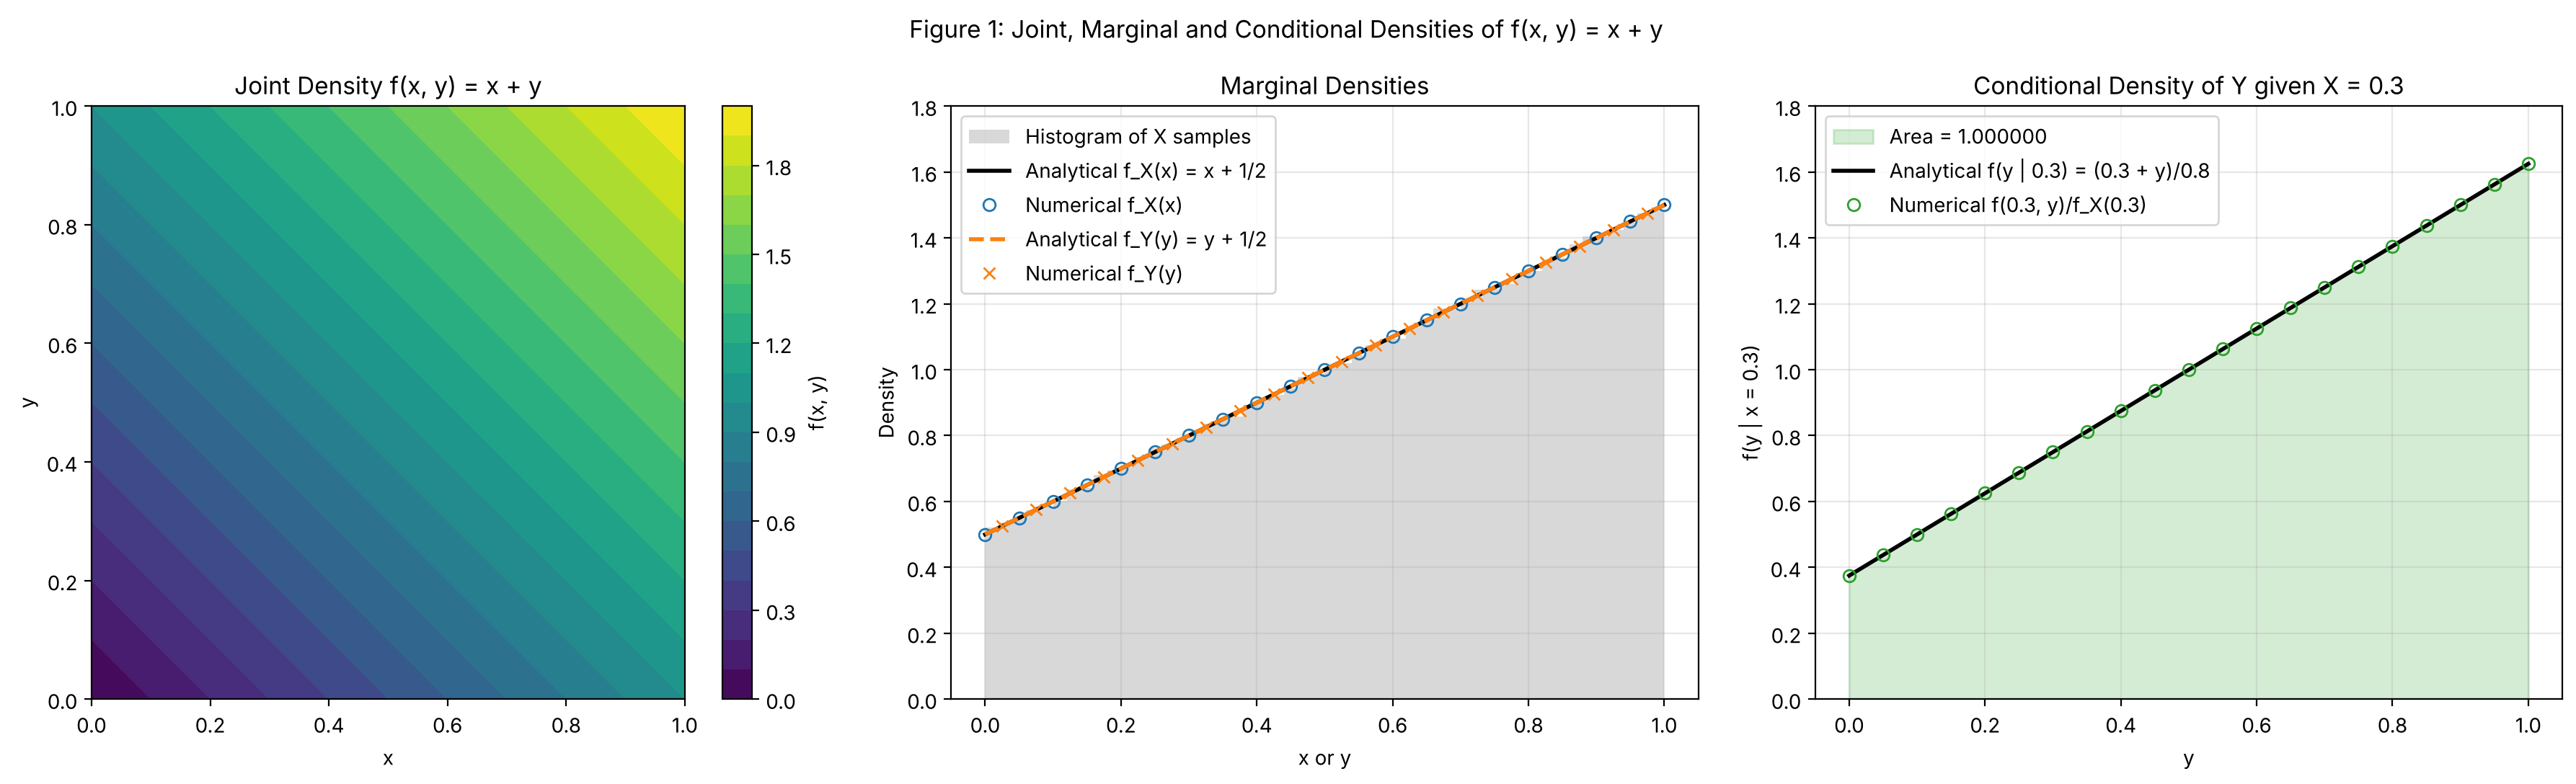

In [5]:
#Figure 1: joint density, marginals and conditional density

plt.figure(figsize=(18, 5.5))

#Joint density heatmap
plt.subplot(1, 3, 1)
plt.contourf(X_grid, Y_grid, joint_grid, levels=20, cmap="viridis")
plt.colorbar(label="f(x, y)")
plt.gca().set_aspect("equal")
plt.title("Joint Density f(x, y) = x + y")
plt.xlabel("x")
plt.ylabel("y")

#Marginals, analytical as lines and numerical as markers (every 50th grid point so the line is still visible)
plt.subplot(1, 3, 2)
plt.hist(x_samples, bins=50, range=(0, 1), density=True, alpha=0.3, color="gray", label="Histogram of X samples")
plt.plot(x_grid, marginal_x(x_grid), "black", linewidth=2, label="Analytical f_X(x) = x + 1/2")
plt.plot(x_grid[::50], fx_numerical[::50], "o", color="tab:blue", markerfacecolor="none", label="Numerical f_X(x)")
plt.plot(y_grid, marginal_y(y_grid), "--", color="tab:orange", linewidth=2, label="Analytical f_Y(y) = y + 1/2")
plt.plot(y_grid[25::50], fy_numerical[25::50], "x", color="tab:orange", label="Numerical f_Y(y)")
plt.ylim(0, 1.8)
plt.title("Marginal Densities")
plt.xlabel("x or y")
plt.ylabel("Density")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

#Conditional density at x = 0.3
plt.subplot(1, 3, 3)
plt.fill_between(y_grid, conditional_analytical, color="tab:green", alpha=0.2, label=f"Area = {conditional_integral:.6f}")
plt.plot(y_grid, conditional_analytical, "black", linewidth=2, label="Analytical f(y | 0.3) = (0.3 + y)/0.8")
plt.plot(y_grid[::50], conditional_numerical[::50], "o", color="tab:green", markerfacecolor="none", label="Numerical f(0.3, y)/f_X(0.3)")
plt.ylim(0, 1.8)
plt.title("Conditional Density of Y given X = 0.3")
plt.xlabel("y")
plt.ylabel("f(y | x = 0.3)")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.suptitle("Figure 1: Joint, Marginal and Conditional Densities of f(x, y) = x + y")
plt.tight_layout()
plt.show()

### Figure 1 Explanation

    The left graph depicts the joint density, which increases from 0 at the origin to 2 at the corner (1, 1). The middle graph depicts the marginal densities, and you will notice that the numerical marginals land right on the analytical lines x + 1/2 and y + 1/2 with a largest difference of 1.11e-15. Both marginals are the same because the density is symmetric in x and y. The right graph depicts the conditional density of Y given X = 0.3, which goes from 0.3750 at y = 0 to 1.6250 at y = 1 and has an area of 1.000000. The quadrature of the joint density was 1.0000000000, and every moment from quadrature matched our hand calculations with a difference of 2.58e-15 or smaller, so all of the check yourself values were reproduced.

    For rejection sampling the acceptance rate was 0.49976 with a standard error of 0.00034, which is close to the expected 1/M = 0.5. All of the sample statistics were within 3 standard errors of the exact values, for example the sample correlation was -0.089741 with a standard error of 0.001097 compared to the exact -0.090909. This shows that our rejection sampler produces samples from the correct density.

### Why is the Correlation Negative?

$$E[Y\mid X=x]=\frac{\frac{x}{2}+\frac{1}{3}}{x+\frac{1}{2}}$$

This goes from 0.6667 at $x=0$ to 0.5556 at $x=1$, and our samples show the same thing (0.6510 when $X<0.1$ and 0.5588 when $X>0.9$).

    When x is small, y makes up most of the density so Y is pulled toward large values. When x is large the density is already high for every y, so Y is spread out more evenly and its average drops, which means that a larger X goes with a smaller Y and gives the small negative correlation.

## Step 2: Uncorrelated Does Not Mean Independent

**Objective:** Show that two variables can have a correlation of 0 and still depend completely on each other, and that this can't happen for a jointly Gaussian pair.

$$X\sim\text{Uniform}(-1,1) \qquad Y=X^2$$

**Process:** We will show by hand that $\text{Cov}(X,Y)=0$ and check it with $10^7$ samples. Then we will show that $Y$ depends completely on $X$ with a scatter plot and with the variance of $Y$ in narrow bins of $x$. Finally, we will generate a jointly Gaussian pair with $\rho=0$ and check that its joint probabilities equal the product of its marginals.

### Covariance of X and Y = X²

PDF of X:

$$f_X(x)=\frac{1}{2} \qquad -1<x<1$$

Mean of X:

$$E[X]=\int_{-1}^{1}\frac{x}{2}\,dx=\left[\frac{x^2}{4}\right]_{-1}^{1}=\frac{1}{4}-\frac{1}{4}=0$$

Mean of Y:

$$E[Y]=E[X^2]=\int_{-1}^{1}\frac{x^2}{2}\,dx=\left[\frac{x^3}{6}\right]_{-1}^{1}=\frac{1}{6}+\frac{1}{6}=\frac{1}{3}$$

Covariance:

$$\text{Cov}(X,Y)=E[XY]-E[X]E[Y]=E[X^3]-0\cdot\frac{1}{3}$$

$$E[X^3]=\int_{-1}^{1}\frac{x^3}{2}\,dx=\left[\frac{x^4}{8}\right]_{-1}^{1}=\frac{1}{8}-\frac{1}{8}=0$$

$$\text{Cov}(X,Y)=0$$

Variances:

$$\text{Var}(X)=E[X^2]-E[X]^2=\frac{1}{3}-0=\frac{1}{3}$$

$$E[Y^2]=E[X^4]=\int_{-1}^{1}\frac{x^4}{2}\,dx=\left[\frac{x^5}{10}\right]_{-1}^{1}=\frac{1}{5}$$

$$\text{Var}(Y)=E[Y^2]-E[Y]^2=\frac{1}{5}-\frac{1}{9}=\frac{4}{45}=0.088889$$

### Numerical Check

We use the same standard errors as Step 1: $SE=\frac{s}{\sqrt{N}}$ for the means, variances and covariance, and batch means (100 batches of $10^5$ samples) for $\rho$. The sample correlation should land within a few times

$$\frac{1}{\sqrt{N}}=\frac{1}{\sqrt{10^7}}\approx 3.2\times10^{-4}$$

of zero.

In [6]:
#Step 2: Uncorrelated does not mean independent

#Part 2: Numerical check with 10^7 samples

N_2 = 10**7 #Ten million samples

#X is uniform on (-1, 1) and Y = X^2
x_step2 = rng2.uniform(-1, 1, N_2)
y_step2 = x_step2**2

#Hand calculated values
E_Y_exact_2 = 1 / 3
Var_X_exact_2 = 1 / 3
Var_Y_exact_2 = 4 / 45
Cov_exact_2 = 0
rho_exact_2 = 0

#Sample values
E_X_sim_2 = numpy.mean(x_step2)
E_Y_sim_2 = numpy.mean(y_step2)
Var_X_sim_2 = numpy.var(x_step2)
Var_Y_sim_2 = numpy.var(y_step2)
Cov_sim_2 = numpy.mean((x_step2 - E_X_sim_2) * (y_step2 - E_Y_sim_2))
rho_sim_2 = numpy.corrcoef(x_step2, y_step2)[0, 1]

#Standard errors, a sample mean has SE = s/sqrt(N)
#Var and Cov are sample means of (x - mean)^2 and (x - mean)(y - mean), so the same formula works
se_E_Y_2 = numpy.std(y_step2) / numpy.sqrt(N_2)
se_Var_X_2 = numpy.std((x_step2 - E_X_sim_2)**2) / numpy.sqrt(N_2)
se_Var_Y_2 = numpy.std((y_step2 - E_Y_sim_2)**2) / numpy.sqrt(N_2)
se_Cov_2 = numpy.std((x_step2 - E_X_sim_2) * (y_step2 - E_Y_sim_2)) / numpy.sqrt(N_2)

#The correlation is not a simple sample mean, so we use batch means like Step 1
#Split the samples into 100 batches of 10^5, find rho in each batch,
#and the standard error is the standard deviation of the batch values divided by sqrt(100)
n_batches_2 = 100
x_batches_2 = x_step2.reshape(n_batches_2, -1)
y_batches_2 = y_step2.reshape(n_batches_2, -1)
rho_batches_2 = numpy.array([numpy.corrcoef(x_batches_2[i], y_batches_2[i])[0, 1] for i in range(n_batches_2)])
se_rho_2 = numpy.std(rho_batches_2, ddof=1) / numpy.sqrt(n_batches_2)

#Arrays of exact values, sample values and standard errors
exact_2 = numpy.array([E_Y_exact_2, Var_X_exact_2, Var_Y_exact_2, Cov_exact_2, rho_exact_2])
sim_2 = numpy.array([E_Y_sim_2, Var_X_sim_2, Var_Y_sim_2, Cov_sim_2, rho_sim_2])
se_2 = numpy.array([se_E_Y_2, se_Var_X_2, se_Var_Y_2, se_Cov_2, se_rho_2])

#Difference between the sample and exact values
diff_2 = numpy.abs(sim_2 - exact_2)

#Checks if the difference is within 3 standard errors
within_three_SE_2 = diff_2 <= 3 * se_2

print(f"Step 2, N = {N_2}")
print("Quantity      Exact          Sample         Difference     SE             Within 3 SE")
print(f"E[Y]:         {exact_2[0]:<15.6f}{sim_2[0]:<15.6f}{diff_2[0]:<15.6f}{se_2[0]:<15.6f}{within_three_SE_2[0]}")
print(f"Var(X):       {exact_2[1]:<15.6f}{sim_2[1]:<15.6f}{diff_2[1]:<15.6f}{se_2[1]:<15.6f}{within_three_SE_2[1]}")
print(f"Var(Y):       {exact_2[2]:<15.6f}{sim_2[2]:<15.6f}{diff_2[2]:<15.6f}{se_2[2]:<15.6f}{within_three_SE_2[2]}")
print(f"Cov(X,Y):     {exact_2[3]:<15.6f}{sim_2[3]:<15.6f}{diff_2[3]:<15.6f}{se_2[3]:<15.6f}{within_three_SE_2[3]}")
print(f"rho:          {exact_2[4]:<15.6f}{sim_2[4]:<15.6f}{diff_2[4]:<15.6f}{se_2[4]:<15.6f}{within_three_SE_2[4]}")

#The manual says the correlation should be within a few times 1/sqrt(N) of zero
print(f"\nSample correlation: {rho_sim_2:.2e}   Standard Error: {se_rho_2:.2e}")
print(f"1/sqrt(N):          {1 / numpy.sqrt(N_2):.2e}")
print(f"|rho| / (1/sqrt(N)): {abs(rho_sim_2) * numpy.sqrt(N_2):.2f}")

Step 2, N = 10000000
Quantity      Exact          Sample         Difference     SE             Within 3 SE
E[Y]:         0.333333       0.333173       0.000161       0.000094       True
Var(X):       0.333333       0.333173       0.000161       0.000094       True
Var(Y):       0.088889       0.088857       0.000032       0.000030       True
Cov(X,Y):     0.000000       0.000078       0.000078       0.000068       True
rho:          0.000000       0.000456       0.000456       0.000394       True

Sample correlation: 4.56e-04   Standard Error: 3.94e-04
1/sqrt(N):          3.16e-04
|rho| / (1/sqrt(N)): 1.44


### Conditional Variance in Bins of x

$\text{Var}(Y\mid X=x)$ is the variance of $Y$ when $X$ is held at $x$. Since $Y=X^2$, knowing $x$ tells us $y$ exactly, so it should be 0. We estimate it by sorting the samples by $x$ and splitting them into bins of nearby $x$ values, then taking the variance of $y$ inside each bin.

It can't be exactly 0 because $x^2$ still changes a little inside a bin. Let $h$ be the bin width. The slope of $x^2$ is $2x$, so inside one bin $y$ is spread evenly over a length of about $2|x|h$:

$$\text{Var}(Y\mid X\text{ in bin})\approx\frac{(2xh)^2}{12}=\frac{x^2h^2}{3}$$

This is largest at $x=\pm1$, where it equals $h^2/3$, and it goes to 0 as $h$ goes to 0. We compare the bin with the largest variance to this expected value.

Part 3: Conditional Variance of Y in Bins of X
Bin Width     Bin Center     Largest Var(Y | X in bin)     Expected x^2 h^2/3     Difference     SE             Within 3 SE
0.0200        0.9900         1.312e-04                     1.312e-04              5.12e-08       3.71e-07       True
0.0020        -0.9990        1.367e-06                     1.382e-06              1.51e-08       1.23e-08       True

Var(Y) without binning: 0.088857
Largest binned variance (width 0.002) / Var(Y): 1.54e-05


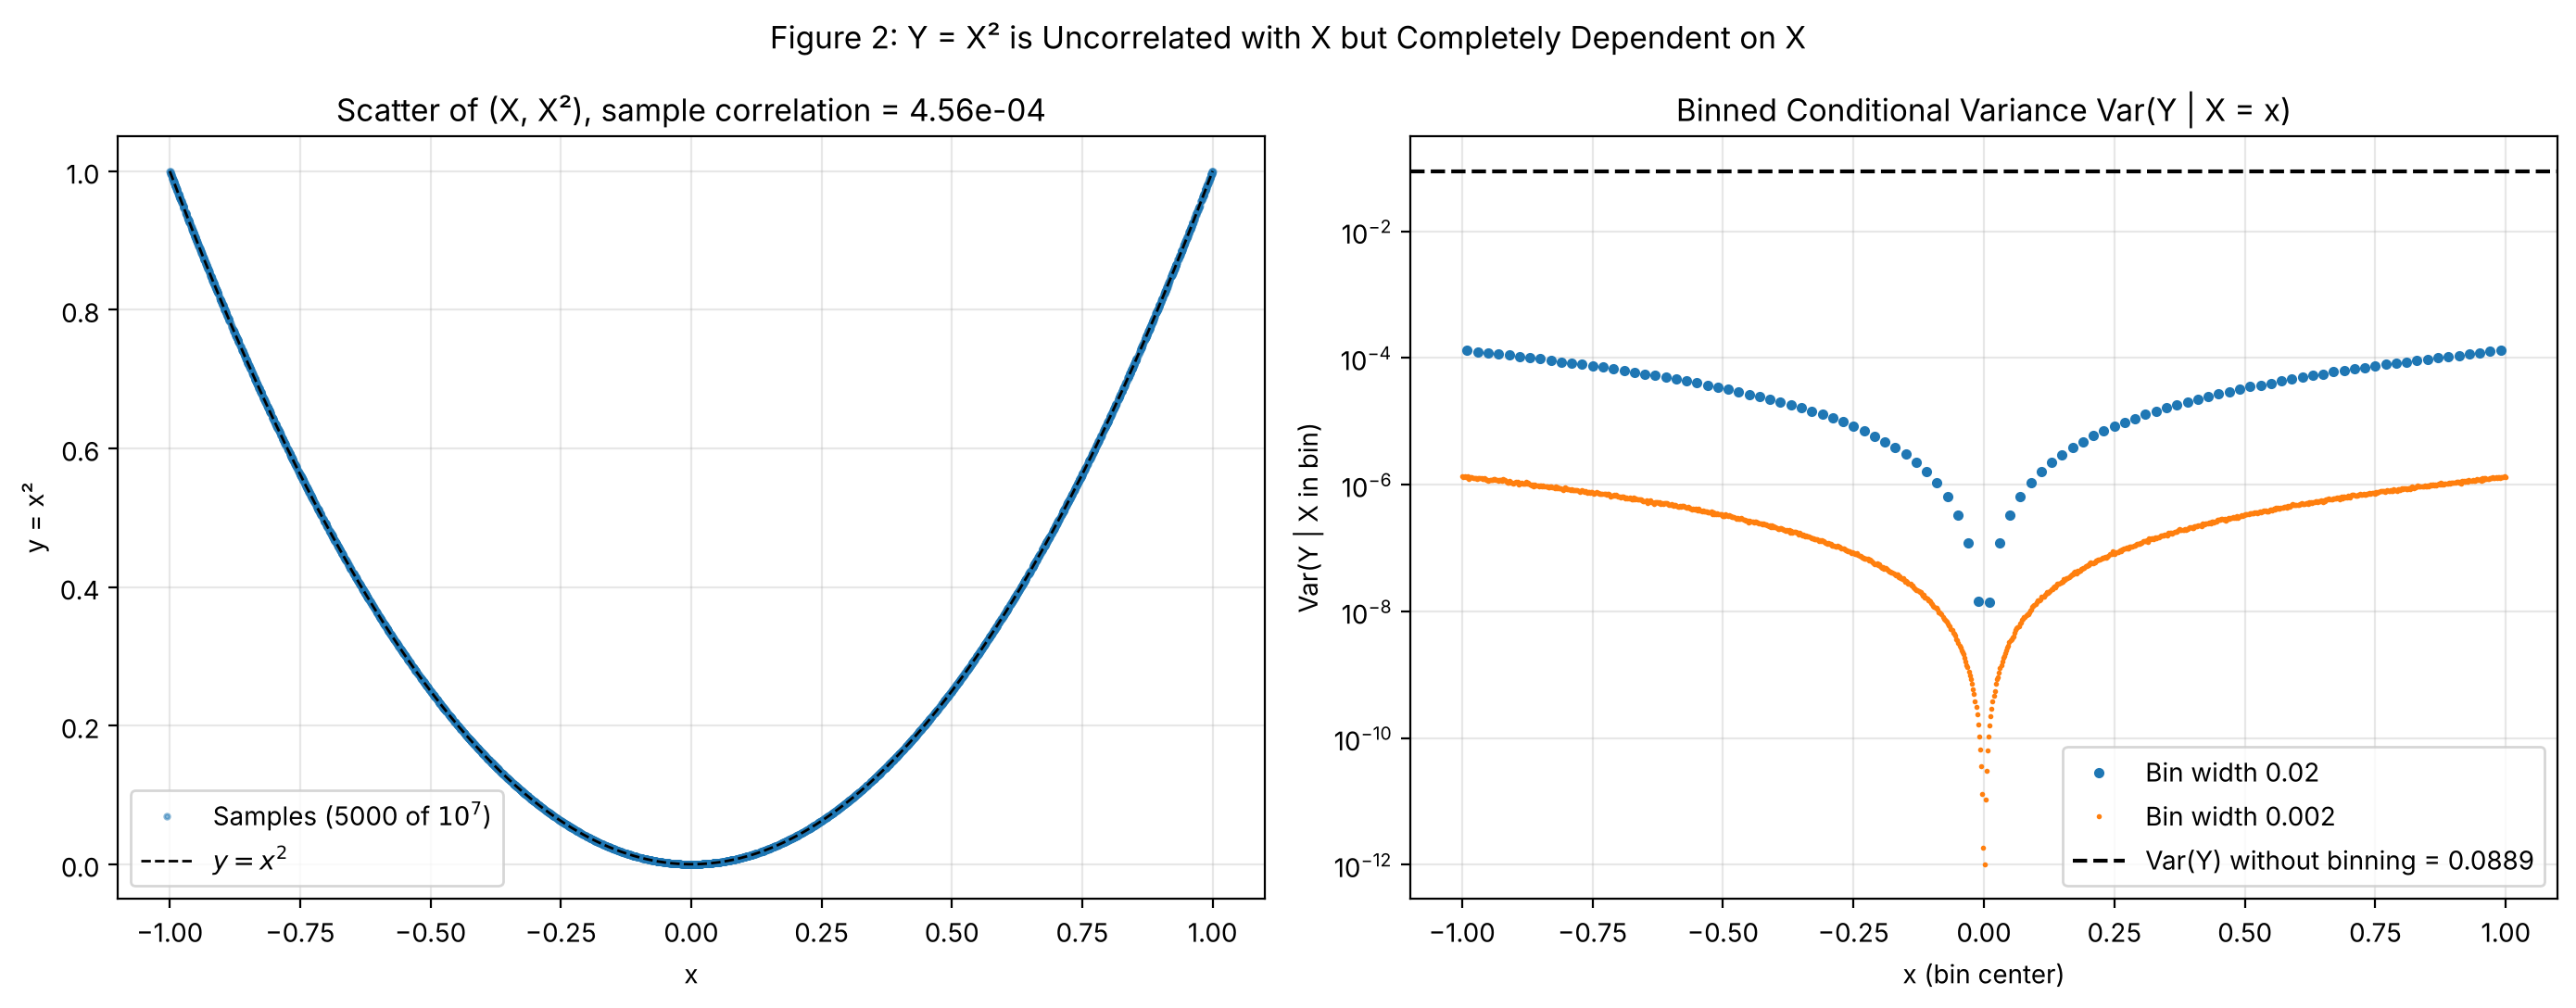

In [7]:
#Part 3: Conditional variance of Y in narrow bins of x

#Sorts the samples by x so that samples next to each other have almost the same x
order = numpy.argsort(x_step2)
x_sorted = x_step2[order]
y_sorted = y_step2[order]

#100 bins, each row holds 10^5 samples with x values next to each other (bin width about 0.02)
x_bins_100 = x_sorted.reshape(100, -1)
y_bins_100 = y_sorted.reshape(100, -1)
centers_100 = x_bins_100.mean(axis=1) #Middle of each bin
vars_100 = y_bins_100.var(axis=1) #Variance of y in each bin

#1000 bins, each row holds 10^4 samples (bin width about 0.002)
x_bins_1000 = x_sorted.reshape(1000, -1)
y_bins_1000 = y_sorted.reshape(1000, -1)
centers_1000 = x_bins_1000.mean(axis=1)
vars_1000 = y_bins_1000.var(axis=1)

#Bin with the largest variance for each bin width
k_100 = numpy.argmax(vars_100)
k_1000 = numpy.argmax(vars_1000)

#Width h of that bin (largest x minus smallest x in the bin)
h_100 = x_bins_100[k_100].max() - x_bins_100[k_100].min()
h_1000 = x_bins_1000[k_1000].max() - x_bins_1000[k_1000].min()

#Expected leftover variance x^2 h^2/3 at the center of that bin
leftover_100 = centers_100[k_100]**2 * h_100**2 / 3
leftover_1000 = centers_1000[k_1000]**2 * h_1000**2 / 3

#Standard error of a sample variance, it is a sample mean of (y - mean)^2 so SE = s/sqrt(N)
y_big_100 = y_bins_100[k_100]
y_big_1000 = y_bins_1000[k_1000]
se_var_100 = numpy.std((y_big_100 - y_big_100.mean())**2) / numpy.sqrt(len(y_big_100))
se_var_1000 = numpy.std((y_big_1000 - y_big_1000.mean())**2) / numpy.sqrt(len(y_big_1000))

#Difference between the largest binned variance and the expected leftover
diff_var_100 = abs(vars_100[k_100] - leftover_100)
diff_var_1000 = abs(vars_1000[k_1000] - leftover_1000)

print("Part 3: Conditional Variance of Y in Bins of X")
print("Bin Width     Bin Center     Largest Var(Y | X in bin)     Expected x^2 h^2/3     Difference     SE             Within 3 SE")
print(f"{h_100:<14.4f}{centers_100[k_100]:<15.4f}{vars_100[k_100]:<30.3e}{leftover_100:<23.3e}{diff_var_100:<15.2e}{se_var_100:<15.2e}{diff_var_100 <= 3 * se_var_100}")
print(f"{h_1000:<14.4f}{centers_1000[k_1000]:<15.4f}{vars_1000[k_1000]:<30.3e}{leftover_1000:<23.3e}{diff_var_1000:<15.2e}{se_var_1000:<15.2e}{diff_var_1000 <= 3 * se_var_1000}")
print(f"\nVar(Y) without binning: {Var_Y_sim_2:.6f}")
print(f"Largest binned variance (width 0.002) / Var(Y): {vars_1000.max() / Var_Y_sim_2:.2e}")

#Figure 2: scatter of (X, X^2) and the binned conditional variance
plt.figure(figsize=(14, 5.5))

#Scatter, 5000 points are plotted so the graph is readable (the correlation uses all 10^7)
plt.subplot(1, 2, 1)
plt.plot(x_step2[:5000], y_step2[:5000], ".", markersize=4, alpha=0.5, label="Samples (5000 of $10^7$)")
x_curve = numpy.linspace(-1, 1, 500)
plt.plot(x_curve, x_curve**2, "black", linestyle="--", linewidth=1, label="$y = x^2$")
plt.title(f"Scatter of (X, X²), sample correlation = {rho_sim_2:.2e}")
plt.xlabel("x")
plt.ylabel("y = x²")
plt.legend()
plt.grid(alpha=0.3)

#Binned conditional variance on a log axis so the small values can be seen next to Var(Y)
plt.subplot(1, 2, 2)
plt.semilogy(centers_100, vars_100, "o", markersize=3, label="Bin width 0.02")
plt.semilogy(centers_1000, vars_1000, ".", markersize=2, label="Bin width 0.002")
plt.axhline(Var_Y_sim_2, color="black", linestyle="--", label=f"Var(Y) without binning = {Var_Y_sim_2:.4f}")
plt.title("Binned Conditional Variance Var(Y | X = x)")
plt.xlabel("x (bin center)")
plt.ylabel("Var(Y | X in bin)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3, which="both")

plt.suptitle("Figure 2: Y = X² is Uncorrelated with X but Completely Dependent on X")
plt.tight_layout()
plt.show()

### Figure 2 Explanation

    The left graph depicts the scatter of (X, X²). Every sample lands on the curve y = x², so if you know X you know Y. The sample correlation is only 4.56e-04 with a standard error of 3.94e-04. That is 1.44 times 1/sqrt(N) = 3.16e-04, so it is within a few times 1/sqrt(N) of zero. All of the sample values (E[Y], Var(X), Var(Y), Cov(X,Y) and rho) were within 3 standard errors of our hand calculations.

    The right graph depicts the variance of Y inside each bin of x. You will notice that it is much smaller than the variance of Y without binning (the dashed line). The largest binned variance was 1.312e-04 for bins of width 0.0200 and 1.367e-06 for bins of width 0.0020, which match the expected x²h²/3 (1.312e-04 and 1.382e-06) within 3 standard errors. When the bins get 10 times narrower the variance drops by about 100 times, which means Var(Y | X = x) goes to 0 everywhere.

### What Correlation Measures

    The correlation coefficient only measures how well Y follows a straight line in X, and since Y = X² goes down on the left side and up on the right side, the two sides cancel out and the correlation is 0 even though Y depends completely on X.

### Jointly Gaussian Pair with ρ = 0

We will generate $10^6$ samples of a jointly Gaussian pair with zero mean, variances of 1 and $\rho=0$. We split each variable into 10 bins that each hold 10% of the samples, which makes a $10\times10$ grid of cells. If the two variables are independent, the joint probability of each cell should equal the product of the marginals:

$$P(\text{cell})=P(\text{row})\,P(\text{column})=0.1\cdot0.1=0.01$$

The standard error of a cell probability of $0.01$ is

$$SE=\sqrt{\frac{0.01(1-0.01)}{N}}$$

We compare the joint and product in all 100 cells, and we do the same thing for $X$ and $X^2$ to see the difference.

In [8]:
#Part 5: Jointly Gaussian pair with rho = 0

N_gauss = 10**6 #One million samples

#Jointly Gaussian pair with zero mean, variances of 1 and rho = 0
gauss_pair = rng2.multivariate_normal([0, 0], [[1, 0], [0, 1]], size=N_gauss)
g1 = gauss_pair[:, 0]
g2 = gauss_pair[:, 1]

#Sample correlation, the data is Gaussian here so SE = (1 - rho^2)/sqrt(N - 2) works like MP1
rho_gauss = numpy.corrcoef(g1, g2)[0, 1]
se_rho_gauss = (1 - rho_gauss**2) / numpy.sqrt(N_gauss - 2)

#Bin edges that split each variable into 10 bins with 10% of the samples in each
edges_g1 = numpy.quantile(g1, numpy.linspace(0, 1, 11))
edges_g2 = numpy.quantile(g2, numpy.linspace(0, 1, 11))

#Number of samples in each of the 10 x 10 cells
counts_gauss = numpy.histogram2d(g1, g2, bins=[edges_g1, edges_g2])[0]

#Empirical joint probability of each cell
joint_gauss = counts_gauss / N_gauss

#Product of the marginals, each row and column holds 10% of the samples
product_gauss = numpy.outer(joint_gauss.sum(axis=1), joint_gauss.sum(axis=0))

#Same thing for X and Y = X^2, using the first 10^6 samples so both pairs have the same N
x_first = x_step2[:N_gauss]
y_first = y_step2[:N_gauss]
edges_x = numpy.quantile(x_first, numpy.linspace(0, 1, 11))
edges_y = numpy.quantile(y_first, numpy.linspace(0, 1, 11))
counts_square = numpy.histogram2d(x_first, y_first, bins=[edges_x, edges_y])[0]
joint_square = counts_square / N_gauss
product_square = numpy.outer(joint_square.sum(axis=1), joint_square.sum(axis=0))

#Largest difference between the joint and the product over all 100 cells
max_diff_gauss = numpy.max(numpy.abs(joint_gauss - product_gauss))
max_diff_square = numpy.max(numpy.abs(joint_square - product_square))

#Standard error of a cell probability of 0.01 (10% x 10%)
se_cell = numpy.sqrt(0.01 * (1 - 0.01) / N_gauss)

#Number of cells within 3 standard errors of the product
cells_within_gauss = numpy.sum(numpy.abs(joint_gauss - product_gauss) <= 3 * se_cell)
cells_within_square = numpy.sum(numpy.abs(joint_square - product_square) <= 3 * se_cell)

print(f"Part 5: Gaussian pair, sample correlation = {rho_gauss:.2e}   Standard Error: {se_rho_gauss:.2e}")
print("\nJoint vs Product of Marginals, 10 x 10 cells, N = 1000000")
print("Pair                Largest Difference     Cell SE        Difference / SE     Cells Within 3 SE")
print(f"Gaussian, rho = 0   {max_diff_gauss:<23.2e}{se_cell:<15.2e}{max_diff_gauss / se_cell:<20.2f}{cells_within_gauss} of 100")
print(f"X and X^2           {max_diff_square:<23.2e}{se_cell:<15.2e}{max_diff_square / se_cell:<20.2f}{cells_within_square} of 100")

Part 5: Gaussian pair, sample correlation = -2.92e-04   Standard Error: 1.00e-03

Joint vs Product of Marginals, 10 x 10 cells, N = 1000000
Pair                Largest Difference     Cell SE        Difference / SE     Cells Within 3 SE
Gaussian, rho = 0   2.67e-04               9.95e-05       2.68                100 of 100
X and X^2           4.03e-02               9.95e-05       405.50              0 of 100


### Independence Results

    For the Gaussian pair the sample correlation was -2.92e-04 with a standard error of 1.00e-03. The largest difference between the joint probability and the product of the marginals was 2.67e-04, which is 2.68 times the cell standard error of 9.95e-05. 100 of 100 cells were within 3 standard errors, which means the pair is independent.

    For X and X² the largest difference was 4.03e-02, which is 405.50 standard errors, and 0 of 100 cells were within 3 standard errors. This means X and X² are dependent even though their correlation was 0.

### Why Uncorrelated Means Independent Only for Gaussians

For a jointly Gaussian pair with $\rho=0$ the density splits into two pieces:

$$f(x,y)=\frac{1}{2\pi\sigma_1\sigma_2}e^{-\frac{x^2}{2\sigma_1^2}-\frac{y^2}{2\sigma_2^2}}=\frac{1}{\sqrt{2\pi}\sigma_1}e^{-\frac{x^2}{2\sigma_1^2}}\cdot\frac{1}{\sqrt{2\pi}\sigma_2}e^{-\frac{y^2}{2\sigma_2^2}}=f_X(x)f_Y(y)$$

    When the correlation of a jointly Gaussian pair is 0, the density splits into the product of the marginals, which means the two variables are independent. This is not true for other distributions because the correlation only measures how well Y follows a straight line in X, so Y = X² can have a correlation of 0 and still depend on X. This makes the Gaussian assumption load bearing in engineering, because if we treat uncorrelated noise as independent and the noise is not Gaussian, our results can be wrong.

## Step 3: The Covariance Matrix and How Well We Can Estimate It

**Objective:** Check that a 4 x 4 covariance matrix is valid and find out how many samples we need to estimate it.

$$\Sigma=\begin{bmatrix}4&2&1&0\\2&5&2&1\\1&2&3&1\\0&1&1&2\end{bmatrix}$$

**Process:** We will check that $\Sigma$ is symmetric and that all of its eigenvalues are 0 or larger, then test `is_valid_covariance`. Then we will generate samples with this covariance, estimate $\Sigma$ with `sample_mean_cov` from $N=10^2$ to $10^6$, and see how fast the error falls as $N$ gets bigger.

### Valid Covariance Matrix

A covariance matrix has to be:

- **Symmetric:** $\Sigma=\Sigma^T$ because $\text{Cov}(X_i,X_j)=\text{Cov}(X_j,X_i)$
- **Positive semidefinite:** every eigenvalue is 0 or larger because a variance can't be negative

The determinant is the product of the eigenvalues:

$$\det\Sigma=\lambda_1\lambda_2\lambda_3\lambda_4$$

We use `eigvalsh` instead of `eig` because $\Sigma$ is symmetric, so the eigenvalues are real. To test `is_valid_covariance` we also use $\Sigma$ with one entry changed so it is not symmetric, and a symmetric matrix with a negative eigenvalue:

$$\det\begin{bmatrix}1-\lambda&2\\2&1-\lambda\end{bmatrix}=(1-\lambda)^2-4=0$$

$$1-\lambda=\pm2$$

$$\lambda=3,\;-1$$

In [9]:
#Step 3: The covariance matrix and how well we can estimate it

#Part 1: Valid covariance matrix

#4 x 4 covariance matrix
Sigma_3 = numpy.array([[4, 2, 1, 0],
                       [2, 5, 2, 1],
                       [1, 2, 3, 1],
                       [0, 1, 1, 2]], dtype=float)

#Symmetric: Sigma should equal its transpose, so the largest difference should be 0
sym_diff_3 = numpy.max(numpy.abs(Sigma_3 - Sigma_3.T))

#Eigenvalues, eigvalsh is used instead of eig because Sigma is symmetric
eigenvalues_3 = numpy.linalg.eigvalsh(Sigma_3)

#Determinant of Sigma, should equal the product of the eigenvalues
det_3 = numpy.linalg.det(Sigma_3)

print("Part 1: Valid Covariance Matrix")
print(f"Largest |Sigma - Sigma^T|:  {sym_diff_3:.1f}")
print(f"Eigenvalues:                {eigenvalues_3[0]:.4f}, {eigenvalues_3[1]:.4f}, {eigenvalues_3[2]:.4f}, {eigenvalues_3[3]:.4f}")
print(f"Determinant:                {det_3:.4f}")
print(f"Product of eigenvalues:     {numpy.prod(eigenvalues_3):.4f}")

#Non symmetric matrix: Sigma with the top right entry changed from 0 to 1, the bottom left entry stays 0
non_symmetric_3 = Sigma_3.copy()
non_symmetric_3[0, 3] = 1

#Symmetric matrix with a negative eigenvalue: [[1, 2], [2, 1]] has eigenvalues 3 and -1
negative_eig_3 = numpy.array([[1, 2], [2, 1]], dtype=float)

#Tests is_valid_covariance on all three matrices
valid_sigma_3 = func.is_valid_covariance(Sigma_3)
valid_non_symmetric_3 = func.is_valid_covariance(non_symmetric_3)
valid_negative_eig_3 = func.is_valid_covariance(negative_eig_3)

print("\nis_valid_covariance Test")
print("Matrix                        Smallest Eigenvalue     Valid")
print(f"Sigma:                        {eigenvalues_3.min():<24.4f}{valid_sigma_3}")
print(f"Non symmetric:                {'not symmetric':<24}{valid_non_symmetric_3}")
print(f"Symmetric [[1, 2], [2, 1]]:   {numpy.linalg.eigvalsh(negative_eig_3).min():<24.4f}{valid_negative_eig_3}")

Part 1: Valid Covariance Matrix
Largest |Sigma - Sigma^T|:  0.0
Eigenvalues:                1.2649, 1.7882, 3.0981, 7.8488
Determinant:                55.0000
Product of eigenvalues:     55.0000

is_valid_covariance Test
Matrix                        Smallest Eigenvalue     Valid
Sigma:                        1.2649                  True
Non symmetric:                not symmetric           False
Symmetric [[1, 2], [2, 1]]:   -1.0000                 False


### Valid Covariance Results

    Sigma is symmetric (largest difference from its transpose is 0.0) and its eigenvalues are 1.2649, 1.7882, 3.0981 and 7.8488. All of them are greater than 0, so Sigma is a valid covariance matrix. The determinant is 55.0000, which is the same as the product of the eigenvalues. is_valid_covariance returned True for Sigma, False for the non symmetric matrix, and False for [[1, 2], [2, 1]] because its smallest eigenvalue is -1.0000.

### Estimating Σ from Samples

Sample covariance, which is what `sample_mean_cov` calculates:

$$\hat\Sigma=\frac{1}{N-1}\sum_{n=1}^{N}(\mathbf{x}_n-\bar{\mathbf{x}})(\mathbf{x}_n-\bar{\mathbf{x}})^T$$

To measure how far the estimate is from $\Sigma$ we use the Frobenius norm, which squares the difference of every entry, adds them up and takes the square root:

$$\|\hat\Sigma-\Sigma\|_F=\sqrt{\sum_{i,j}\left(\hat\Sigma_{ij}-\Sigma_{ij}\right)^2}$$

One estimate at each $N$ is too random to see the pattern, so we repeat it 200 times at $N=10^2$ and $10^3$, 100 times at $10^4$, 30 times at $10^5$ and 10 times at $10^6$ and average the errors. The first repetition at each $N$ is kept as the single draw. The standard error of each average is

$$SE=\frac{s}{\sqrt{\text{repetitions}}}$$

If the error falls like $1/\sqrt{N}$:

$$\text{error}\approx\frac{C}{\sqrt{N}}$$

$$\log_{10}(\text{error})=\log_{10}C-\frac{1}{2}\log_{10}N$$

So with log scales on both axes the error should be a straight line with a slope of $-0.5$, and $\sqrt{N}\cdot\text{error}=C$ should stay the same. We fit a straight line to find the slope, and the fit also gives us a standard error for the slope.

Frobenius Norm of Sigma_hat - Sigma
N          Reps   Single Draw    Averaged       SE of Average  Expected   Difference     sqrt(N) x Single   sqrt(N) x Averaged
100        200    1.4018         1.5711         0.0364         1.56       0.0111         14.02              15.71
1000       200    0.6774         0.5114         0.0127         0.49       0.0214         21.42              16.17
10000      100    0.1357         0.1499         0.0044         0.16       0.0101         13.57              14.99
100000     30     0.0466         0.0501         0.0029         0.046      0.0041         14.75              15.86
1000000    10     0.0214         0.0168         0.0013         0.016      0.0008         21.42              16.81

Averaged error drop each time N is 10 times bigger: 3.07, 3.41, 2.99, 2.98   sqrt(10) = 3.16

N          sqrt(N) x Averaged   Difference from 15   SE
100        15.71                0.71                 0.36
1000       16.17                1.17                 0.40


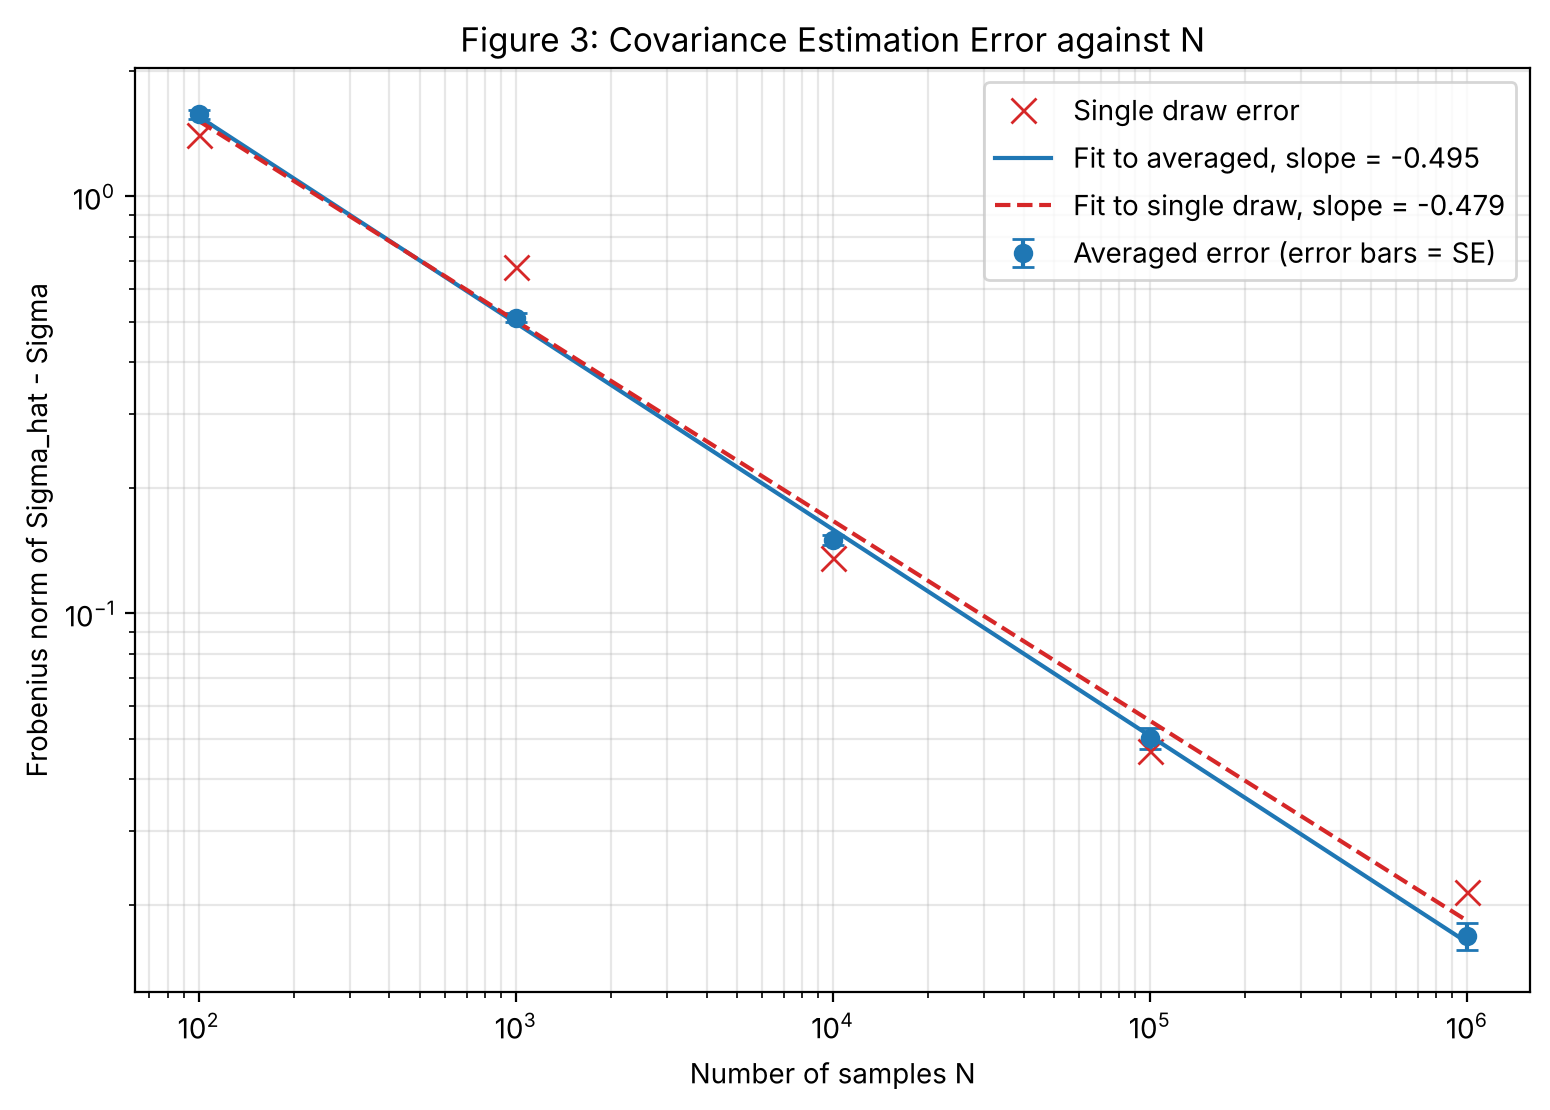

In [10]:
#Parts 2 to 4: Estimation error against N

#Sample sizes and the number of repetitions at each one
N_list_3 = numpy.array([10**2, 10**3, 10**4, 10**5, 10**6])
reps_3 = numpy.array([200, 200, 100, 30, 10])

#Zero mean for the samples
mu_3 = numpy.zeros(4)

#Expected averaged errors
expected_3 = numpy.array([1.56, 0.49, 0.16, 0.046, 0.016])

#Arrays to hold the results at each N
single_error_3 = numpy.zeros(5) #Error of the first repetition (single draw)
average_error_3 = numpy.zeros(5) #Average error over all repetitions
se_error_3 = numpy.zeros(5) #Standard error of the average

#Repeats the estimate at each N and saves the Frobenius norm of Sigma_hat - Sigma each time
for k in range(5):
    errors = numpy.zeros(reps_3[k])
    for r in range(reps_3[k]):
        #Generates N samples with covariance Sigma
        X_3 = rng3.multivariate_normal(mu_3, Sigma_3, size=N_list_3[k])
        #Estimates Sigma with our function
        Sigma_hat_3 = func.sample_mean_cov(X_3)[1]
        #Frobenius norm of the difference
        errors[r] = numpy.linalg.norm(Sigma_hat_3 - Sigma_3, "fro")
    single_error_3[k] = errors[0]
    average_error_3[k] = errors.mean()
    se_error_3[k] = errors.std(ddof=1) / numpy.sqrt(reps_3[k])

#Difference between the averaged and expected errors
diff_3 = numpy.abs(average_error_3 - expected_3)

#sqrt(N) x error should stay the same if the error falls like 1/sqrt(N)
sqrtN_single_3 = numpy.sqrt(N_list_3) * single_error_3
sqrtN_average_3 = numpy.sqrt(N_list_3) * average_error_3

print("Frobenius Norm of Sigma_hat - Sigma")
print("N          Reps   Single Draw    Averaged       SE of Average  Expected   Difference     sqrt(N) x Single   sqrt(N) x Averaged")
for k in range(5):
    print(f"{N_list_3[k]:<11}{reps_3[k]:<7}{single_error_3[k]:<15.4f}{average_error_3[k]:<15.4f}{se_error_3[k]:<15.4f}{expected_3[k]:<11}{diff_3[k]:<15.4f}{sqrtN_single_3[k]:<19.2f}{sqrtN_average_3[k]:.2f}")

#How much the averaged error drops each time N is 10 times bigger, should be about sqrt(10)
drop_3 = average_error_3[:-1] / average_error_3[1:]
print(f"\nAveraged error drop each time N is 10 times bigger: {drop_3[0]:.2f}, {drop_3[1]:.2f}, {drop_3[2]:.2f}, {drop_3[3]:.2f}   sqrt(10) = {numpy.sqrt(10):.2f}")

#Difference from 15 and standard error of sqrt(N) x averaged error at each N
diff_15_3 = numpy.abs(sqrtN_average_3 - 15)
se_sqrtN_3 = numpy.sqrt(N_list_3) * se_error_3
print("\nN          sqrt(N) x Averaged   Difference from 15   SE")
for k in range(5):
    print(f"{N_list_3[k]:<11}{sqrtN_average_3[k]:<21.2f}{diff_15_3[k]:<21.2f}{se_sqrtN_3[k]:.2f}")

#Range and mean of sqrt(N) x error, the averaged one should stay near 15 (within about 10%)
mean_sqrtN_average_3 = sqrtN_average_3.mean()
mean_sqrtN_single_3 = sqrtN_single_3.mean()
print("\n                             Lowest    Highest   Mean      Mean Difference from 15")
print(f"sqrt(N) x averaged error:    {sqrtN_average_3.min():<10.2f}{sqrtN_average_3.max():<10.2f}{mean_sqrtN_average_3:<10.2f}{100 * abs(mean_sqrtN_average_3 / 15 - 1):.1f}%")
print(f"sqrt(N) x single draw error: {sqrtN_single_3.min():<10.2f}{sqrtN_single_3.max():<10.2f}{mean_sqrtN_single_3:<10.2f}{100 * abs(mean_sqrtN_single_3 / 15 - 1):.1f}%")

#Straight line fit of log10(error) against log10(N), the slope is the rate
#cov=True also gives the standard error of the slope
log_N_3 = numpy.log10(N_list_3)
fit_average_3, fit_cov_average_3 = numpy.polyfit(log_N_3, numpy.log10(average_error_3), 1, cov=True)
fit_single_3, fit_cov_single_3 = numpy.polyfit(log_N_3, numpy.log10(single_error_3), 1, cov=True)
slope_average_3 = fit_average_3[0]
slope_single_3 = fit_single_3[0]
slope_se_average_3 = numpy.sqrt(fit_cov_average_3[0, 0])
slope_se_single_3 = numpy.sqrt(fit_cov_single_3[0, 0])

print("\nFitted Slopes          Slope       Standard Error     Difference from -0.5")
print(f"Averaged:              {slope_average_3:<12.4f}{slope_se_average_3:<19.4f}{abs(slope_average_3 + 0.5):.4f}")
print(f"Single draw:           {slope_single_3:<12.4f}{slope_se_single_3:<19.4f}{abs(slope_single_3 + 0.5):.4f}")

#Figure 3: estimation error against N on log scales
plt.figure(figsize=(9, 6))
N_line_3 = numpy.logspace(2, 6, 100)
plt.errorbar(N_list_3, average_error_3, yerr=se_error_3, fmt="o", color="tab:blue", capsize=4, label="Averaged error (error bars = SE)")
plt.plot(N_list_3, single_error_3, "x", color="tab:red", markersize=9, label="Single draw error")
plt.plot(N_line_3, 10**fit_average_3[1] * N_line_3**slope_average_3, color="tab:blue", label=f"Fit to averaged, slope = {slope_average_3:.3f}")
plt.plot(N_line_3, 10**fit_single_3[1] * N_line_3**slope_single_3, "--", color="tab:red", label=f"Fit to single draw, slope = {slope_single_3:.3f}")
plt.xscale("log")
plt.yscale("log")
plt.title("Figure 3: Covariance Estimation Error against N")
plt.xlabel("Number of samples N")
plt.ylabel("Frobenius norm of Sigma_hat - Sigma")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()

### Figure 3 Explanation

    The graph depicts the error of our covariance estimate against N with log scales on both axes. You will notice that the averaged errors (blue) fall on a straight line. The averaged errors were 1.5711, 0.5114, 0.1499, 0.0501 and 0.0168, which are close to the expected 1.56, 0.49, 0.16, 0.046 and 0.016 with a largest difference of 0.0214. The fitted slope was -0.4950 with a standard error of 0.0060, which is 0.0050 away from -0.5. This means the error falls like 1/sqrt(N), and it drops by about sqrt(10) = 3.16 every time N is 10 times bigger (3.07, 3.41, 2.99 and 2.98).

    sqrt(N) x averaged error stayed between 14.99 and 16.81 with a mean of 15.91, which is 6.1% away from the expected 15, so it stays about the same. The single draw errors (red) were 1.4018, 0.6774, 0.1357, 0.0466 and 0.0214, and their sqrt(N) x error jumped between 13.57 and 21.42. The single draw slope was -0.4794 with a standard error of 0.0346. The single draw curve is not good enough to fit a slope to because each point is only one random estimate, so one point can land far from the average (0.6774 vs 0.5114 at N = 1000) and move the slope.

### How Many Samples in 100 Dimensions?

$\Sigma$ is symmetric, so only the diagonal and the entries above it are free:

$$p=\frac{d(d+1)}{2}$$

$$d=4:\quad p=\frac{4\cdot5}{2}=10$$

$$d=100:\quad p=\frac{100\cdot101}{2}=5050$$

Each free parameter has its own error that falls like $1/\sqrt{N}$, and the Frobenius norm adds all of them up:

$$\|\hat\Sigma-\Sigma\|_F\approx C\sqrt{\frac{p}{N}}$$

To keep the same accuracy with more free parameters, $N$ has to grow by the same amount as $p$:

$$N_{100}\approx10^4\cdot\frac{5050}{10}$$

In [11]:
#Part 5: Free parameters and samples needed in 100 dimensions

#Number of free parameters d(d + 1)/2
p_4 = 4 * (4 + 1) // 2
p_100 = 100 * (100 + 1) // 2

#Relative accuracy at N = 10^4 in four dimensions (averaged error divided by the size of Sigma)
relative_error_3 = average_error_3[2] / numpy.linalg.norm(Sigma_3, "fro")

#N has to grow by the same amount as the number of free parameters
N_needed_3 = 10**4 * p_100 / p_4

print("Part 5: Free Parameters")
print(f"d = 4:     {p_4}")
print(f"d = 100:   {p_100}")
print(f"\nRelative accuracy at N = 10^4 (d = 4): {relative_error_3:.4f}")
print(f"Free parameter ratio:                  {p_100 / p_4:.0f}")
print(f"Samples needed for d = 100:            {N_needed_3:.0f}")

Part 5: Free Parameters
d = 4:     10
d = 100:   5050

Relative accuracy at N = 10^4 (d = 4): 0.0172
Free parameter ratio:                  505
Samples needed for d = 100:            5050000


### Free Parameters Results

    For d = 4 there are 10 free parameters and for d = 100 there are 5050, which is 505 times more. At N = 10^4 our averaged error was 0.0172 of the Frobenius norm of Sigma. Since the error grows with the number of free parameters, a 100 dimensional covariance would need roughly 5050000 samples to get the same accuracy.

### Why This Is a Problem for a Radar

    A radar with 100 array elements would need roughly 5050000 samples to estimate its covariance as well as we did with 10^4 samples in four dimensions, but the targets and noise around the radar change long before it can collect that many. A designer can add a small amount to the diagonal of the estimated covariance, which keeps the estimate usable even with far fewer samples.

## Step 4: Linear Transformations of Random Vectors

**Objective:** Derive how the mean and covariance change under $\mathbf{y}=A\mathbf{x}+\mathbf{b}$, and see what happens when the output covariance is singular.

**Process:** In order to accomplish this objective we will start with a random varible and then use our computed values of $\mu_y$ and $\Sigma_y$ by hand for a $3\times2$ matrix $A$, and check them using a million samples. Then we will look at the rank of $\Sigma_y$, repeat with a rank deficient $2\times2$ matrix, and show that a singular covariance breaks the Gaussian density. 

### The Two Transformation Rules

Mean, using linearity of expectation:

$$\boldsymbol\mu_y=E[A\mathbf{x}+\mathbf{b}]=A\,E[\mathbf{x}]+\mathbf{b}=A\boldsymbol\mu_x+\mathbf{b}$$

Covariance, $\mathbf{b}$ cancels because $\mathbf{y}-\boldsymbol\mu_y=A\mathbf{x}+\mathbf{b}-A\boldsymbol\mu_x-\mathbf{b}=A(\mathbf{x}-\boldsymbol\mu_x)$:

$$\Sigma_y=E\left[(\mathbf{y}-\boldsymbol\mu_y)(\mathbf{y}-\boldsymbol\mu_y)^T\right]=E\left[A(\mathbf{x}-\boldsymbol\mu_x)(\mathbf{x}-\boldsymbol\mu_x)^TA^T\right]$$

$$=A\,E\left[(\mathbf{x}-\boldsymbol\mu_x)(\mathbf{x}-\boldsymbol\mu_x)^T\right]A^T$$

$$\Sigma_y=A\Sigma_xA^T$$

### By Hand

$$\boldsymbol\mu_x=\begin{bmatrix}1\\-2\end{bmatrix} \qquad \Sigma_x=\begin{bmatrix}4&2\\2&4\end{bmatrix} \qquad A=\begin{bmatrix}1&2\\0&1\\1&-1\end{bmatrix}$$

Mean:

$$\boldsymbol\mu_y=A\boldsymbol\mu_x=\begin{bmatrix}1(1)+2(-2)\\0(1)+1(-2)\\1(1)-1(-2)\end{bmatrix}=\begin{bmatrix}-3\\-2\\3\end{bmatrix}$$

Covariance, first $A\Sigma_x$:

$$A\Sigma_x=\begin{bmatrix}1(4)+2(2)&1(2)+2(4)\\0(4)+1(2)&0(2)+1(4)\\1(4)-1(2)&1(2)-1(4)\end{bmatrix}=\begin{bmatrix}8&10\\2&4\\2&-2\end{bmatrix}$$

Then multiply by $A^T=\begin{bmatrix}1&0&1\\2&1&-1\end{bmatrix}$:

$$\Sigma_y=\begin{bmatrix}8+20&0+10&8-10\\2+8&0+4&2-4\\2-4&0-2&2+2\end{bmatrix}=\begin{bmatrix}28&10&-2\\10&4&-2\\-2&-2&4\end{bmatrix}$$

Determinant:

$$\det\Sigma_y=28(16-4)-10(40-4)+(-2)(-20+8)=336-360+24=0$$

### Standard Errors

Each entry of $\boldsymbol\mu_y$ is a sample mean, so $SE=s/\sqrt{N}$. Each entry of $\hat\Sigma_y$ is a sample mean of $(y_i-\bar y_i)(y_j-\bar y_j)$, so its standard error is the standard deviation of that product divided by $\sqrt{N}$, the same method as Steps 1 and 2.

In [12]:
#Step 4: Linear transformations of random vectors

N_4 = 10**6 #One million samples

mu_x_4 =    numpy.array([1, -2], dtype=float)
Sigma_x_4 = numpy.array([[4, 2], [2, 4]], dtype=float)
A_4 = numpy.array([[1, 2], [0, 1], [1, -1]], dtype=float)

#Hand calculated values
mu_y_exact_4 = numpy.array([-3, -2, 3], dtype=float)
Sigma_y_exact_4 = numpy.array([[28, 10, -2], [10, 4, -2], [-2, -2, 4]], dtype=float)

#The same values from the transformation rules
assert numpy.allclose(A_4 @ mu_x_4, mu_y_exact_4)
assert numpy.allclose(A_4 @ Sigma_x_4 @ A_4.T, Sigma_y_exact_4)

#Compares the sample mean and covariance of y against the exact values, with standard errors
def compare_mean_cov(y, mu_exact, Sigma_exact):
    N = y.shape[0]
    d = y.shape[1]
    mean_sim, cov_sim = func.sample_mean_cov(y)
    se_mean = numpy.std(y, axis=0) / numpy.sqrt(N)

    #Products (y_i - mean_i)(y_j - mean_j) for every pair (i, j), shaped (N, d, d)
    middle = y - mean_sim
    products = middle[:, :, None] * middle[:, None, :]
    se_cov = numpy.std(products, axis=0) / numpy.sqrt(N)

    print("Entry        Exact          Sample         Difference     SE             Within 3 SE")
    for i in range(d):
        diff = abs(mean_sim[i] - mu_exact[i])
        print(f"mu[{i}]:       {mu_exact[i]:<15.4f}{mean_sim[i]:<15.4f}{diff:<15.4f}{se_mean[i]:<15.4f}{diff <= 3 * se_mean[i]}")
    for i in range(d):
        for j in range(i, d):
            diff = abs(cov_sim[i, j] - Sigma_exact[i, j])
            print(f"Sigma[{i},{j}]:  {Sigma_exact[i, j]:<15.4f}{cov_sim[i, j]:<15.4f}{diff:<15.4f}{se_cov[i, j]:<15.4f}{diff <= 3 * se_cov[i, j]}")

    #Largest difference measured in standard errors
    z_mean = numpy.abs(mean_sim - mu_exact) / se_mean #compares our simulated resutls with theory for the z
    z_cov = numpy.abs(cov_sim - Sigma_exact) / se_cov #same as the above function but for covariance matrix
    print(f"Largest |difference| / SE: mean = {z_mean.max():.2f}, covariance = {z_cov.max():.2f}")
    return mean_sim, cov_sim

#Part 2: Simulate x and apply y = A x 
x_4 = rng4.multivariate_normal(mu_x_4, Sigma_x_4, size=N_4)
y_4 = x_4 @ A_4.T

print(f"Part 2: y = A x, N = {N_4}")
mean_y_4, cov_y_4 = compare_mean_cov(y_4, mu_y_exact_4, Sigma_y_exact_4)

#Part 3: Rank of Sigma_y
print("\nPart 3: Rank of Sigma_y")
print(f"Rank of exact Sigma_y:          {numpy.linalg.matrix_rank(Sigma_y_exact_4)}")
print(f"Rank of sample Sigma_y:         {numpy.linalg.matrix_rank(cov_y_4)}")
print(f"Eigenvalues of exact Sigma_y:   {numpy.round(numpy.linalg.eigvalsh(Sigma_y_exact_4), 4)}")
print(f"Eigenvalues of sample Sigma_y:  {numpy.round(numpy.linalg.eigvalsh(cov_y_4), 4)}")

#n = [1, -3, -1] solves A^T n = 0, so n . y = n . A x = 0 for every sample
normal_4 = numpy.array([1, -3, -1], dtype=float)
print(f"\nA^T n for n = [1, -3, -1]:      {A_4.T @ normal_4}")
print(f"Largest |n . y| over all samples: {numpy.max(numpy.abs(y_4 @ normal_4)):.2e}")
print(f"Largest |y| over all samples:     {numpy.max(numpy.abs(y_4)):.2f}")

Part 2: y = A x, N = 1000000


Entry        Exact          Sample         Difference     SE             Within 3 SE
mu[0]:       -3.0000        -3.0002        0.0002         0.0053         True
mu[1]:       -2.0000        -1.9992        0.0008         0.0020         True
mu[2]:       3.0000         2.9973         0.0027         0.0020         True
Sigma[0,0]:  28.0000        27.9430        0.0570         0.0396         True
Sigma[0,1]:  10.0000        9.9879         0.0121         0.0146         True
Sigma[0,2]:  -2.0000        -2.0207        0.0207         0.0108         True
Sigma[1,1]:  4.0000         3.9988         0.0012         0.0057         True
Sigma[1,2]:  -2.0000        -2.0084        0.0084         0.0045         True
Sigma[2,2]:  4.0000         4.0045         0.0045         0.0057         True
Largest |difference| / SE: mean = 1.36, covariance = 1.92

Part 3: Rank of Sigma_y
Rank of exact Sigma_y:          2
Rank of sample Sigma_y:         2
Eigenvalues of exact Sigma_y:   [ 0.      4.1436 31.8564]
Eige

### Simulation Results

    All 3 entries of the sample mean and all 6 unique entries of the sample covariance were within 3 standard errors of the hand values mu_y = [-3, -2, 3] and Sigma_y = [[28, 10, -2], [10, 4, -2], [-2, -2, 4]]. The largest |difference| / SE was 1.36 for the mean and 1.92 for the covariance, so the transformation rules are confirmed.

### Rank of Sigma_y

    Sigma_y has rank 2 (eigenvalues 0, 4.1436 and 31.8564) because y = A x is built from only the 2 random numbers in x, so the rank of A Sigma_x A^T can be no larger than the rank of A, which is 2. Geometrically, every sample of y lives on a plane through the origin in 3D, the column space of A, which is the plane y1 - 3 y2 - y3 = 0. The largest |n . y| over all samples was 3.55e-15 while the samples reach values as large as 28.56, so the samples sit on that plane up to rounding error.

### Rank Deficient A

$$A=\begin{bmatrix}1&1\\2&2\end{bmatrix}$$

Mean:

$$\boldsymbol\mu_y=\begin{bmatrix}1-2\\2-4\end{bmatrix}=\begin{bmatrix}-1\\-2\end{bmatrix}$$

Covariance:

$$A\Sigma_x=\begin{bmatrix}4+2&2+4\\8+4&4+8\end{bmatrix}=\begin{bmatrix}6&6\\12&12\end{bmatrix}$$

$$\Sigma_y=A\Sigma_xA^T=\begin{bmatrix}6&6\\12&12\end{bmatrix}\begin{bmatrix}1&2\\1&2\end{bmatrix}=\begin{bmatrix}12&24\\24&48\end{bmatrix}$$

$$\det\Sigma_y=12(48)-24(24)=576-576=0$$

The second row of $A$ is 2 times the first, so $y_2=2(x_1+x_2)=2y_1$ for every sample. The outputs lie on the line $y_2=2y_1$ through the origin, which also passes through $\boldsymbol\mu_y=[-1,-2]^T$.

Part 4: y = A x with rank deficient A, N = 1000000
Entry        Exact          Sample         Difference     SE             Within 3 SE
mu[0]:       -1.0000        -1.0010        0.0010         0.0035         True
mu[1]:       -2.0000        -2.0020        0.0020         0.0069         True
Sigma[0,0]:  12.0000        11.9660        0.0340         0.0169         True
Sigma[0,1]:  24.0000        23.9320        0.0680         0.0339         True
Sigma[1,1]:  48.0000        47.8639        0.1361         0.0678         True
Largest |difference| / SE: mean = 0.29, covariance = 2.01

Rank of exact Sigma_y:            1
Rank of sample Sigma_y:           1
Eigenvalues of exact Sigma_y:     [ 0. 60.]
Largest |y2 - 2 y1| over samples: 0.00e+00

Part 5: Determinant of the Singular Covariances
Matrix                    det              det / product of diagonal
Exact 3 x 3 Sigma_y       1.60e-14         3.57e-17
Sample 3 x 3 Sigma_y      1.42e-12         3.17e-15
Exact 2 x 2 Sigma_y       0.00e+00

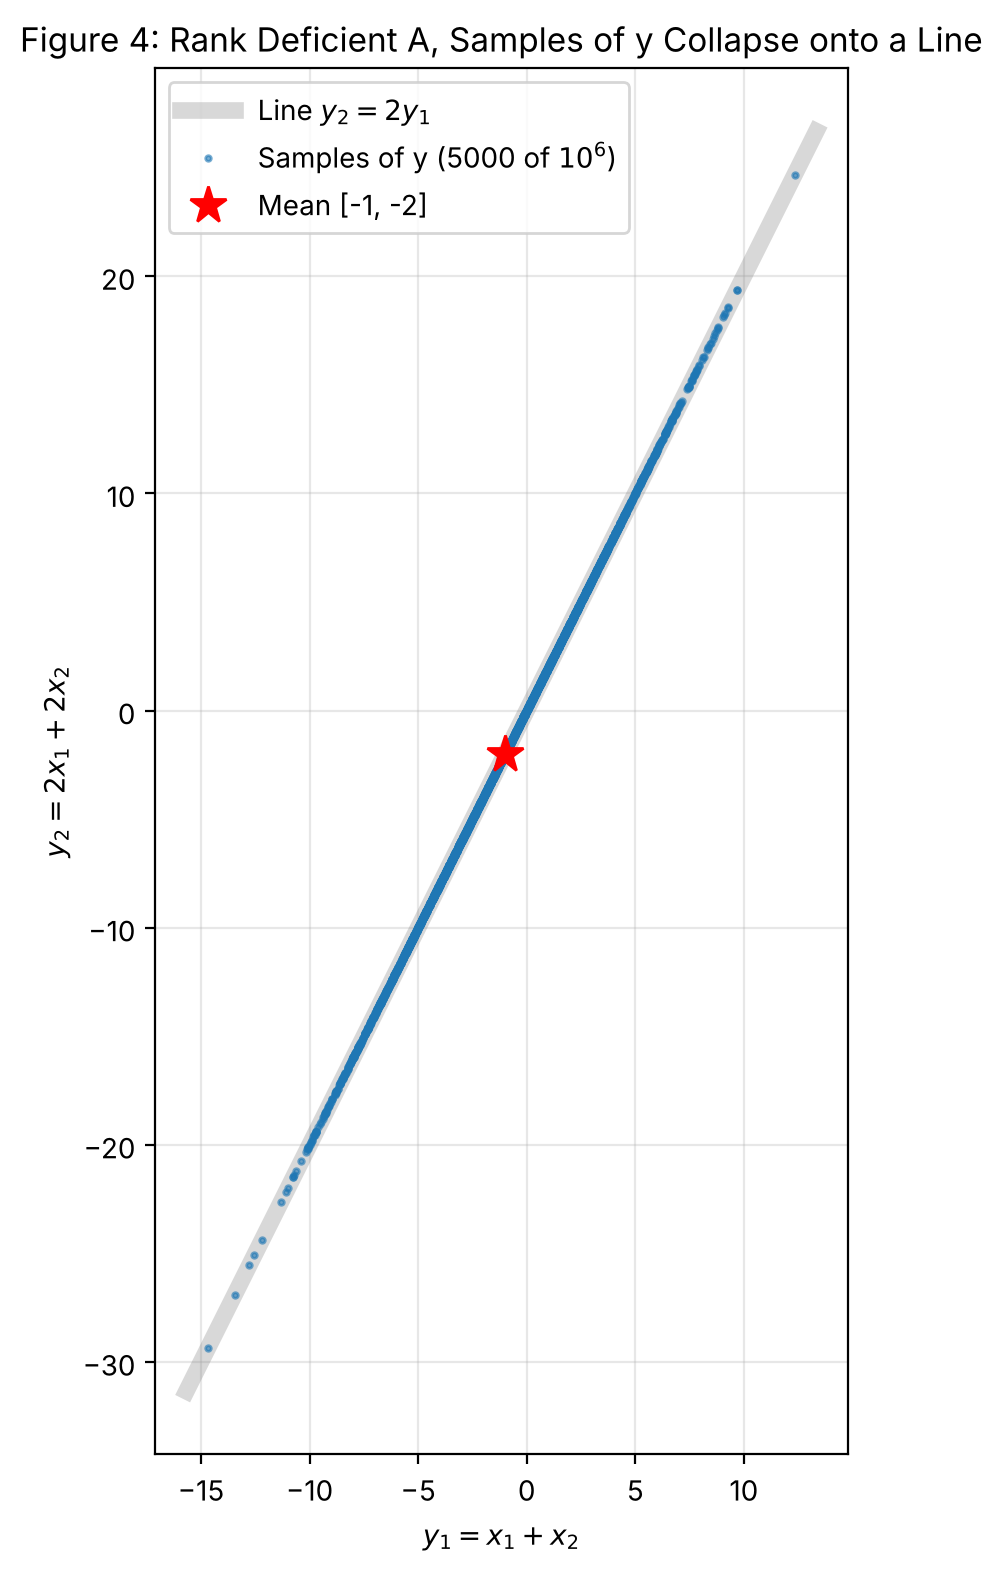

In [13]:
#Part 4: Rank deficient A

A2_4 = numpy.array([[1, 1], [2, 2]], dtype=float)
mu_y2_exact_4 = numpy.array([-1, -2], dtype=float)
Sigma_y2_exact_4 = numpy.array([[12, 24], [24, 48]], dtype=float)
assert numpy.allclose(A2_4 @ mu_x_4, mu_y2_exact_4)
assert numpy.allclose(A2_4 @ Sigma_x_4 @ A2_4.T, Sigma_y2_exact_4)

#Same x samples as Part 2
y2_4 = x_4 @ A2_4.T

print(f"Part 4: y = A x with rank deficient A, N = {N_4}")
mean_y2_4, cov_y2_4 = compare_mean_cov(y2_4, mu_y2_exact_4, Sigma_y2_exact_4)
print(f"\nRank of exact Sigma_y:            {numpy.linalg.matrix_rank(Sigma_y2_exact_4)}")
print(f"Rank of sample Sigma_y:           {numpy.linalg.matrix_rank(cov_y2_4)}")
print(f"Eigenvalues of exact Sigma_y:     {numpy.round(numpy.linalg.eigvalsh(Sigma_y2_exact_4), 4)}")
print(f"Largest |y2 - 2 y1| over samples: {numpy.max(numpy.abs(y2_4[:, 1] - 2 * y2_4[:, 0])):.2e}")

#Part 5: A singular covariance breaks the Gaussian density
#det / (product of the diagonal) is 1 for uncorrelated variables and 0 for a singular matrix, so it shows the size of det on a fair scale
print("\nPart 5: Determinant of the Singular Covariances")
print("Matrix                    det              det / product of diagonal")
for name, S in [("Exact 3 x 3 Sigma_y", Sigma_y_exact_4), ("Sample 3 x 3 Sigma_y", cov_y_4),
                ("Exact 2 x 2 Sigma_y", Sigma_y2_exact_4), ("Sample 2 x 2 Sigma_y", cov_y2_4)]:
    det_S = numpy.linalg.det(S)
    print(f"{name:<26}{det_S:<17.2e}{det_S / numpy.prod(numpy.diag(S)):.2e}")

#Try to evaluate our Gaussian density at the mean with the singular covariance
print("\nEvaluating gaussian_pdf at the mean with the exact singular Sigma_y:")
for name, mu_S, S in [("2 x 2", mu_y2_exact_4, Sigma_y2_exact_4), ("3 x 3", mu_y_exact_4, Sigma_y_exact_4)]:
    try:
        value = func.gaussian_pdf(mu_S, mu_S, S)
        print(f"{name}: returned {value:.3e}")
    except (ValueError, numpy.linalg.LinAlgError) as error:
        print(f"{name}: {type(error).__name__}: {error}")

#Figure 4: rank deficient output samples and the line they lie on
plt.figure(figsize=(6, 9))
y1_line_4 = numpy.linspace(y2_4[:5000, 0].min() - 1, y2_4[:5000, 0].max() + 1, 100)
plt.plot(y1_line_4, 2 * y1_line_4, color="gray", linewidth=6, alpha=0.3, label="Line $y_2 = 2y_1$")
plt.plot(y2_4[:5000, 0], y2_4[:5000, 1], ".", color="tab:blue", markersize=4, alpha=0.6, label="Samples of y (5000 of $10^6$)")
plt.plot(mu_y2_exact_4[0], mu_y2_exact_4[1], "r*", markersize=14, label="Mean [-1, -2]")
plt.gca().set_aspect("equal")
plt.title("Figure 4: Rank Deficient A, Samples of y Collapse onto a Line")
plt.xlabel("$y_1 = x_1 + x_2$")
plt.ylabel("$y_2 = 2x_1 + 2x_2$")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.show()

### Figure 4 Explanation
    This figure confirms our simulation agaisnt the exact values we expct to get with 1 million trials we do have some diffrence because our random simulations have sampling error. This difference in our covarience is given by the number 2.01 which is about 2 standard erros from the exact value whihc is accepatable because it is within 3 standard errors. While the number .29 is the difference for our mean values which is well within our values so we can confirm that simulation agrees with theory. We can see that this figure only displays 5000 of our 1,000,000 samples and that the ones it does display fit well within our y2 = 2 y1. This line passes thorugh the orgin and our mean [1, 2]. We can see that this datat becomes a line so the ordinary gaussian formula breaks. From our function to get the determinate we can see we got a zero which means our data has collasped into fewer dimension. Dispite the fact er got a small value for the 3x3 determinate the number is so small we can say that it is insignficant and becomes zero.The negative number and very small positive number for our 3x3 can be attributed to the floating point roundoff. 

## Step 5: The Multivariate Gaussian

**Objective:** Build the multivariate Gaussian density ourselves and learn to read its contours.

$$\boldsymbol\mu=\mathbf{0} \qquad \Sigma=\begin{bmatrix}4&2\\2&4\end{bmatrix}$$

**Process:** We will write out the density, check `gaussian_pdf` against scipy, integrate it over a large region, then plot the contours that hold 50%, 90% and 99% of the probability over $10^4$ samples and count how many samples fall inside each. Finally we sweep $\rho$ from 0 to 0.99.

### The Density

$$f(\mathbf{x})=\frac{1}{(2\pi)^{d/2}\,|\Sigma|^{1/2}}\exp\!\left(-\frac{1}{2}(\mathbf{x}-\boldsymbol\mu)^T\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)\right)$$

- $\mathbf{x}$ = the point where the density is evaluated, a $d\times1$ vector
- $\boldsymbol\mu$ = mean vector, the center of the density
- $\Sigma$ = covariance matrix, sets the size, shape and tilt of the contours
- $d$ = dimension, here $d=2$
- $|\Sigma|$ = determinant of $\Sigma$, the squared volume scale of the spread
- $(2\pi)^{d/2}|\Sigma|^{1/2}$ = normalizing constant that makes the density integrate to 1
- $r^2=(\mathbf{x}-\boldsymbol\mu)^T\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)$ = squared Mahalanobis distance, the distance from the mean measured in units of the spread in each direction

`gaussian_pdf` finds $\mathbf{z}=\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)$ by solving $\Sigma\mathbf{z}=\mathbf{x}-\boldsymbol\mu$ with `numpy.linalg.solve`, which is faster and more accurate than forming $\Sigma^{-1}$, and then $r^2=(\mathbf{x}-\boldsymbol\mu)^T\mathbf{z}$.

By hand for this $\Sigma$:

$$|\Sigma|=4(4)-2(2)=12 \qquad \Sigma^{-1}=\frac{1}{12}\begin{bmatrix}4&-2\\-2&4\end{bmatrix} \qquad \rho=\frac{\sigma_{12}}{\sigma_1\sigma_2}=\frac{2}{\sqrt{4\cdot4}}=0.5$$

$$f(x_1,x_2)=\frac{1}{2\pi\sqrt{12}}\exp\!\left(-\frac{4x_1^2-4x_1x_2+4x_2^2}{24}\right)=\frac{1}{4\pi\sqrt{3}}\exp\!\left(-\frac{x_1^2-x_1x_2+x_2^2}{6}\right)$$

In [14]:
#Step 5: The multivariate Gaussian

mu_5 = numpy.zeros(2)  #creates a vector 2x1 of zeros

Sigma_5 = numpy.array([[4, 2], [2, 4]], dtype=float)

det_5 = numpy.linalg.det(Sigma_5) #gets the determinate of sigma 5

#Compare gaussian_pdf with scipy at five scattered points
points_5 = numpy.array([[0, 0], [1, -2], [3, 3], [-4, 1], [2.5, -5]], dtype=float)
pdf_ours_5 = func.gaussian_pdf(points_5, mu_5, Sigma_5)
pdf_scipy_5 = scipy.stats.multivariate_normal.pdf(points_5, mean=mu_5, cov=Sigma_5)
rel_diff_5 = numpy.abs(pdf_ours_5 - pdf_scipy_5) / pdf_scipy_5

print("Part 1: gaussian_pdf vs scipy.stats.multivariate_normal.pdf")
print("Point            Ours               Scipy              Relative Difference")
for i in range(len(points_5)):
    print(f"{str(points_5[i]):<17}{pdf_ours_5[i]:<19.10e}{pdf_scipy_5[i]:<19.10e}{rel_diff_5[i]:.2e}")
print(f"Largest relative difference: {rel_diff_5.max():.2e}")
print(f"\ndet(Sigma) = {det_5:.6f}   f(0, 0) = 1/(2 pi sqrt(12)) = {1 / (2 * numpy.pi * numpy.sqrt(12)):.10f}")

#Part 2: Integrate the density over a large square
#The ellipse r^2 = c extends r * sigma = 2r along each axis, so the square [-15, 15]^2 holds the ellipse with r = 7.5
#and the probability left outside the square is less than exp(-7.5^2/2)

L_5 = 15
grid_5 = numpy.linspace(-L_5, L_5, 1201)
G1_5, G2_5 = numpy.meshgrid(grid_5, grid_5, indexing="ij")
grid_points_5 = numpy.column_stack([G1_5.ravel(), G2_5.ravel()])
pdf_grid_5 = func.gaussian_pdf(grid_points_5, mu_5, Sigma_5).reshape(G1_5.shape)
integral_5 = scipy.integrate.simpson(scipy.integrate.simpson(pdf_grid_5, x=grid_5, axis=1), x=grid_5)
r_box_5 = L_5 / numpy.sqrt(Sigma_5[0, 0])

print("\nPart 2: Integral of the Density")
print(f"Region: [-{L_5}, {L_5}] x [-{L_5}, {L_5}], 1201 x 1201 grid, Simpson's rule")
print(f"Mahalanobis radius held by the square: {r_box_5:.2f}")
print(f"Upper bound on probability outside:    {numpy.exp(-r_box_5**2 / 2):.2e}")
print(f"Integral:                              {integral_5:.12f}")
print(f"Difference from 1:                     {abs(integral_5 - 1):.2e}")

Part 1: gaussian_pdf vs scipy.stats.multivariate_normal.pdf
Point            Ours               Scipy              Relative Difference
[0. 0.]          4.5944074618e-02   4.5944074618e-02   1.51e-16
[ 1. -2.]        1.4307132956e-02   1.4307132956e-02   2.42e-16
[3. 3.]          1.0251508727e-02   1.0251508727e-02   3.38e-16
[-4.  1.]        1.3873908372e-03   1.3873908372e-03   3.13e-16
[ 2.5 -5. ]      3.1296726268e-05   3.1296726268e-05   2.17e-15
Largest relative difference: 2.17e-15

det(Sigma) = 12.000000   f(0, 0) = 1/(2 pi sqrt(12)) = 0.0459440746

Part 2: Integral of the Density
Region: [-15, 15] x [-15, 15], 1201 x 1201 grid, Simpson's rule
Mahalanobis radius held by the square: 7.50
Upper bound on probability outside:    6.10e-13
Integral:                              1.000000000000
Difference from 1:                     1.28e-13


### Finding the Contour Levels

A contour of constant density is a set where $r^2$ is constant, so it is an ellipse. For a $d=2$ Gaussian, $r^2$ is a chi square random variable with 2 degrees of freedom, which has the CDF

$$P(r^2\leq k)=1-e^{-k/2}$$

Setting this equal to the probability $p$ we want inside the contour:

$$1-e^{-k/2}=p \;\Rightarrow\; k=-2\ln(1-p)$$

$$p=0.5:\;k=1.3863 \qquad p=0.9:\;k=4.6052 \qquad p=0.99:\;k=9.2103$$

The density on that contour is

$$f_k=\frac{1}{2\pi|\Sigma|^{1/2}}e^{-k/2}$$

which is the level we pass to `contour`. We check the fraction inside by counting the samples with $r^2\leq k$, and the standard error of that fraction is $\sqrt{p(1-p)/N}$.

### Ellipse Axes

With $\Sigma=V\Lambda V^T$, the contour $r^2=k$ is an ellipse whose axes point along the eigenvectors, with semi axis lengths $\sqrt{k\lambda_i}$.

Part 3: Probability Contours, N = 10000
Contour    k = -2 ln(1 - p)    chi2 ppf      Density Level    Fraction Inside    Difference    SE         Within 3 SE
50%       1.3863              1.3863        0.022972         0.5028             0.0028        0.0050     True
90%       4.6052              4.6052        0.004594         0.9024             0.0024        0.0030     True
99%       9.2103              9.2103        0.000459         0.9902             0.0002        0.0010     True

Part 4: Correlation and Ellipse Axes
rho = 0.5000   det(Sigma) = 12.0000
Eigenvalue 2.0000   eigenvector [-0.7071  0.7071]   direction 135.0 degrees
Eigenvalue 6.0000   eigenvector [0.7071 0.7071]   direction 45.0 degrees

Contour             Semi Axis along Eigenvalue 2     Semi Axis along Eigenvalue 6
r^2 = 1 (1 sigma)   1.4142                           2.4495
50%                 1.6651                           2.8841
90%                 3.0349                           5.2565
99%                 4.2919

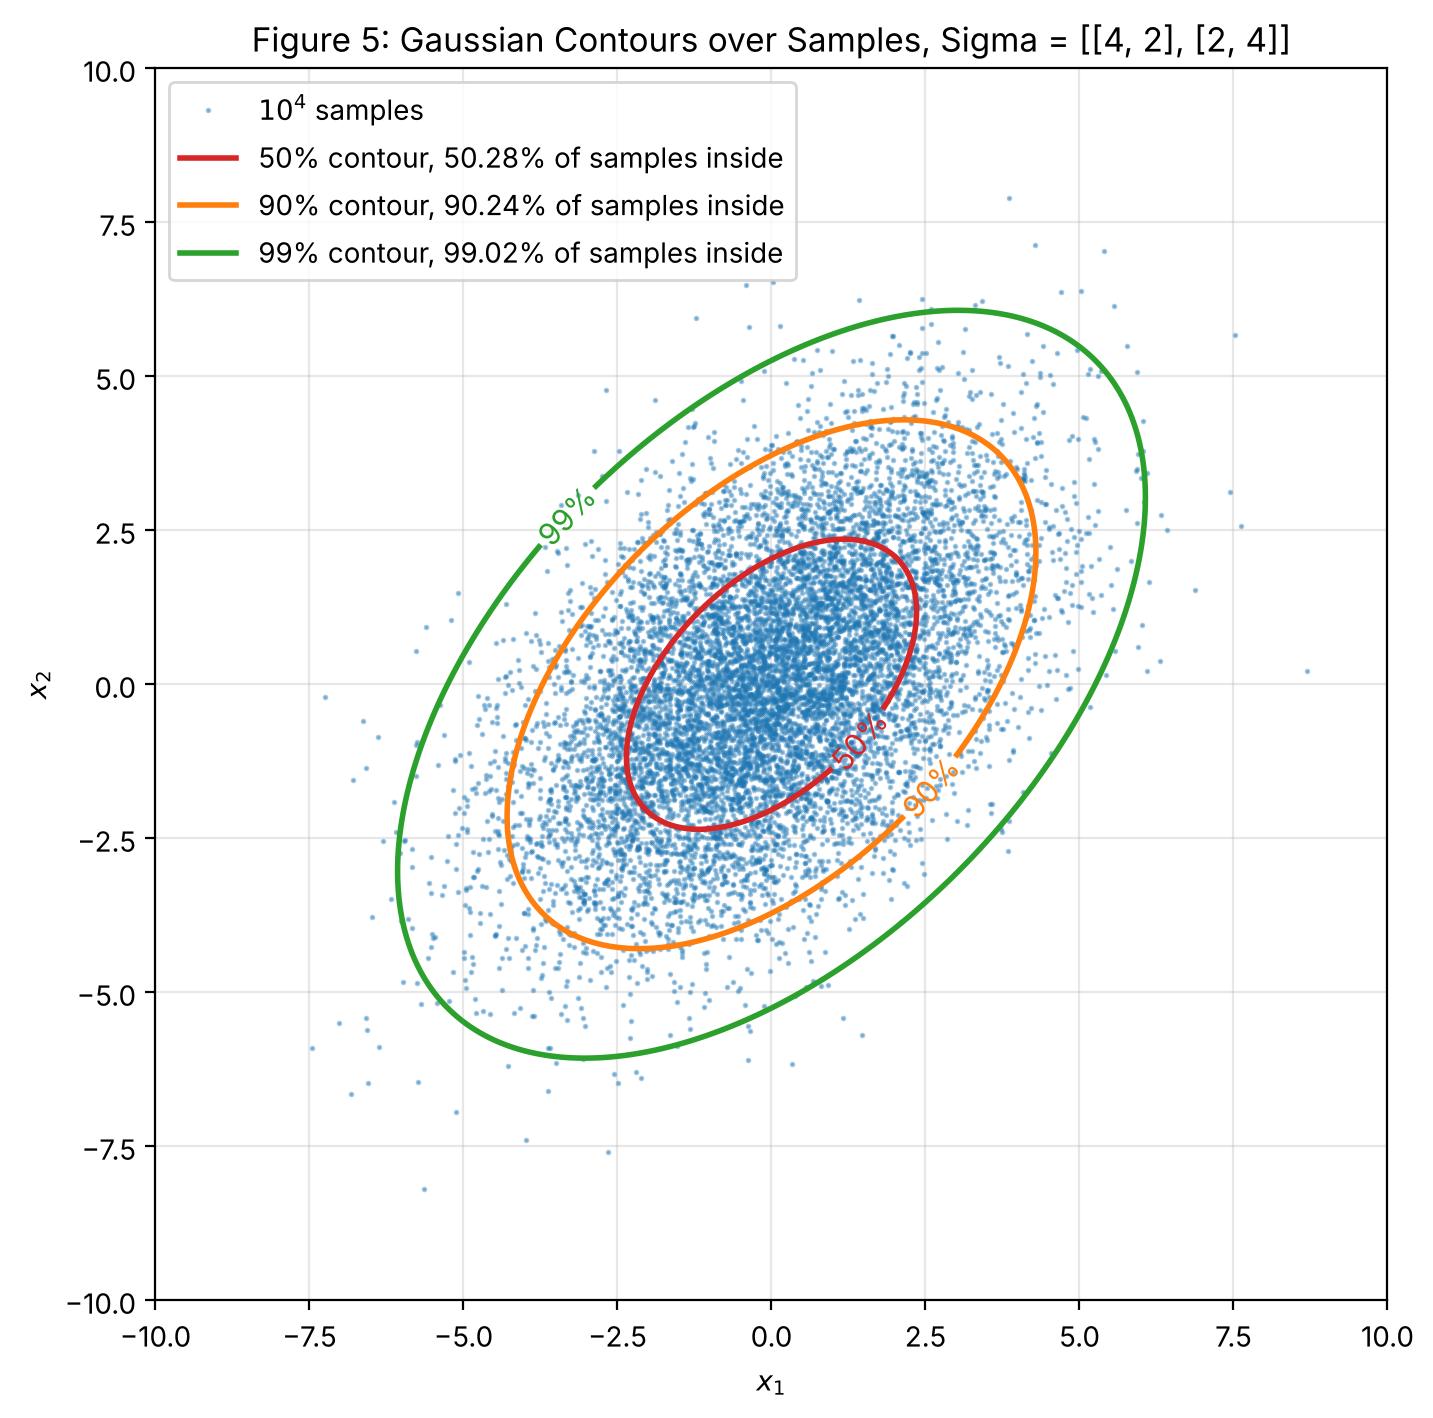

In [15]:
#Part 3: Contours that hold 50%, 90% and 99% of the probability

N_5 = 10**4
samples_5 = rng5.multivariate_normal(mu_5, Sigma_5, size=N_5) #Kept for Step 6

probs_5 = numpy.array([0.5, 0.9, 0.99])
k_5 = -2 * numpy.log(1 - probs_5)                    #Mahalanobis radius squared of each contour
k_chi2_5 = scipy.stats.chi2.ppf(probs_5, df=2)       #Same values from the chi square distribution
levels_5 = numpy.exp(-k_5 / 2) / (2 * numpy.pi * numpy.sqrt(det_5)) #Density on each contour

#Squared Mahalanobis distance of every sample, using solve instead of the inverse
mahal_sq_5 = numpy.sum(samples_5 * numpy.linalg.solve(Sigma_5, samples_5.T).T, axis=1)

fraction_5 = numpy.array([numpy.mean(mahal_sq_5 <= k) for k in k_5])
se_fraction_5 = numpy.sqrt(probs_5 * (1 - probs_5) / N_5)
diff_fraction_5 = numpy.abs(fraction_5 - probs_5)

print(f"Part 3: Probability Contours, N = {N_5}")
print("Contour    k = -2 ln(1 - p)    chi2 ppf      Density Level    Fraction Inside    Difference    SE         Within 3 SE")
for i in range(3):
    print(f"{100 * probs_5[i]:.0f}%{'':<7}{k_5[i]:<20.4f}{k_chi2_5[i]:<14.4f}{levels_5[i]:<17.6f}{fraction_5[i]:<19.4f}{diff_fraction_5[i]:<14.4f}{se_fraction_5[i]:<11.4f}{diff_fraction_5[i] <= 3 * se_fraction_5[i]}")

#Part 4: Correlation and ellipse axes
rho_5 = Sigma_5[0, 1] / numpy.sqrt(Sigma_5[0, 0] * Sigma_5[1, 1])
eigenvalues_5, V_5 = numpy.linalg.eigh(Sigma_5)
angles_5 = numpy.degrees(numpy.arctan2(V_5[1], V_5[0]))

print("\nPart 4: Correlation and Ellipse Axes")
print(f"rho = {rho_5:.4f}   det(Sigma) = {det_5:.4f}")
for i in range(2):
    print(f"Eigenvalue {eigenvalues_5[i]:.4f}   eigenvector {numpy.round(V_5[:, i], 4)}   direction {angles_5[i]:.1f} degrees")
print("\nContour             Semi Axis along Eigenvalue 2     Semi Axis along Eigenvalue 6")
for name, k in [("r^2 = 1 (1 sigma)", 1.0), ("50%", k_5[0]), ("90%", k_5[1]), ("99%", k_5[2])]:
    print(f"{name:<20}{numpy.sqrt(k * eigenvalues_5[0]):<33.4f}{numpy.sqrt(k * eigenvalues_5[1]):.4f}")

#Figure 5: contours over a scatter of the samples
plot_grid_5 = numpy.linspace(-10, 10, 801)
P1_5, P2_5 = numpy.meshgrid(plot_grid_5, plot_grid_5)
pdf_plot_5 = func.gaussian_pdf(numpy.column_stack([P1_5.ravel(), P2_5.ravel()]), mu_5, Sigma_5).reshape(P1_5.shape)
colors_5 = ["tab:red", "tab:orange", "tab:green"]

plt.figure(figsize=(8, 8))
plt.plot(samples_5[:, 0], samples_5[:, 1], ".", color="tab:blue", markersize=2, alpha=0.4, label="$10^4$ samples")
for i in range(3):
    contour = plt.contour(P1_5, P2_5, pdf_plot_5, levels=[levels_5[i]], colors=colors_5[i], linewidths=2)
    plt.clabel(contour, fmt={levels_5[i]: f"{100 * probs_5[i]:.0f}%"}, fontsize=11)
    plt.plot([], [], color=colors_5[i], linewidth=2, label=f"{100 * probs_5[i]:.0f}% contour, {100 * fraction_5[i]:.2f}% of samples inside")
plt.gca().set_aspect("equal")
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.title("Figure 5: Gaussian Contours over Samples, Sigma = [[4, 2], [2, 4]]")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.show()

### Gaussian PDF and Integral Results

    Our gaussian_pdf matched scipy at all five points with a largest relative difference of 2.17e-15, and f(0, 0) = 0.0459440746 = 1/(2 pi sqrt(12)). The integral over [-15, 15] x [-15, 15] was 1.000000000000, a difference from 1 of 1.28e-13. We chose the region so that it holds the ellipse with Mahalanobis radius 7.50 (the ellipse r^2 = c reaches r x sigma = 2r along each axis), so the probability left outside the square is below 6.10e-13.

### Figure 5 Explanation

    Figure 5 depicts 10^4 samples with the contours that should hold 50%, 90% and 99% of the probability. We found the levels from the chi square CDF of r^2 with 2 degrees of freedom, k = -2 ln(1 - p) = 1.3863, 4.6052 and 9.2103, which matched scipy.stats.chi2.ppf, and turned each one into a density level (0.022972, 0.004594 and 0.000459). Counting the samples with r^2 <= k gave fractions of 0.5028, 0.9024 and 0.9902, which are differences of 0.0028, 0.0024 and 0.0002 with standard errors of 0.0050, 0.0030 and 0.0010, so all three are within 3 standard errors.

### Correlation and Ellipse Axes

    For this Sigma, rho = 0.5000 and det(Sigma) = 12.0000. eigh returned the eigenvalues 2 and 6. The short axis points along [-0.7071, 0.7071] at 135.0 degrees, which is the same axis as -45 degrees because the sign of an eigenvector does not matter, and the long axis points along [0.7071, 0.7071] at 45.0 degrees. The semi axis lengths are sqrt(k x eigenvalue): 1.4142 and 2.4495 for the 1 sigma ellipse, 1.6651 and 2.8841 for 50%, 3.0349 and 5.2565 for 90%, and 4.2919 and 7.4338 for 99%.

Part 5: Correlation Sweep
rho      det(Sigma)    16(1 - rho^2)    Eigenvalues 4(1 - rho), 4(1 + rho)    90% Semi Axes (short, long)    Var(X2 | X1) = 4(1 - rho^2)
0        16.0000       16.0000          [4. 4.]                               [4.2919 4.2919]                4.0000
0.5      12.0000       12.0000          [2. 6.]                               [3.0349 5.2565]                3.0000
0.9      3.0400        3.0400           [0.4 7.6]                             [1.3572 5.916 ]                0.7600


0.99     0.3184        0.3184           [0.04 7.96]                           [0.4292 6.0545]                0.0796


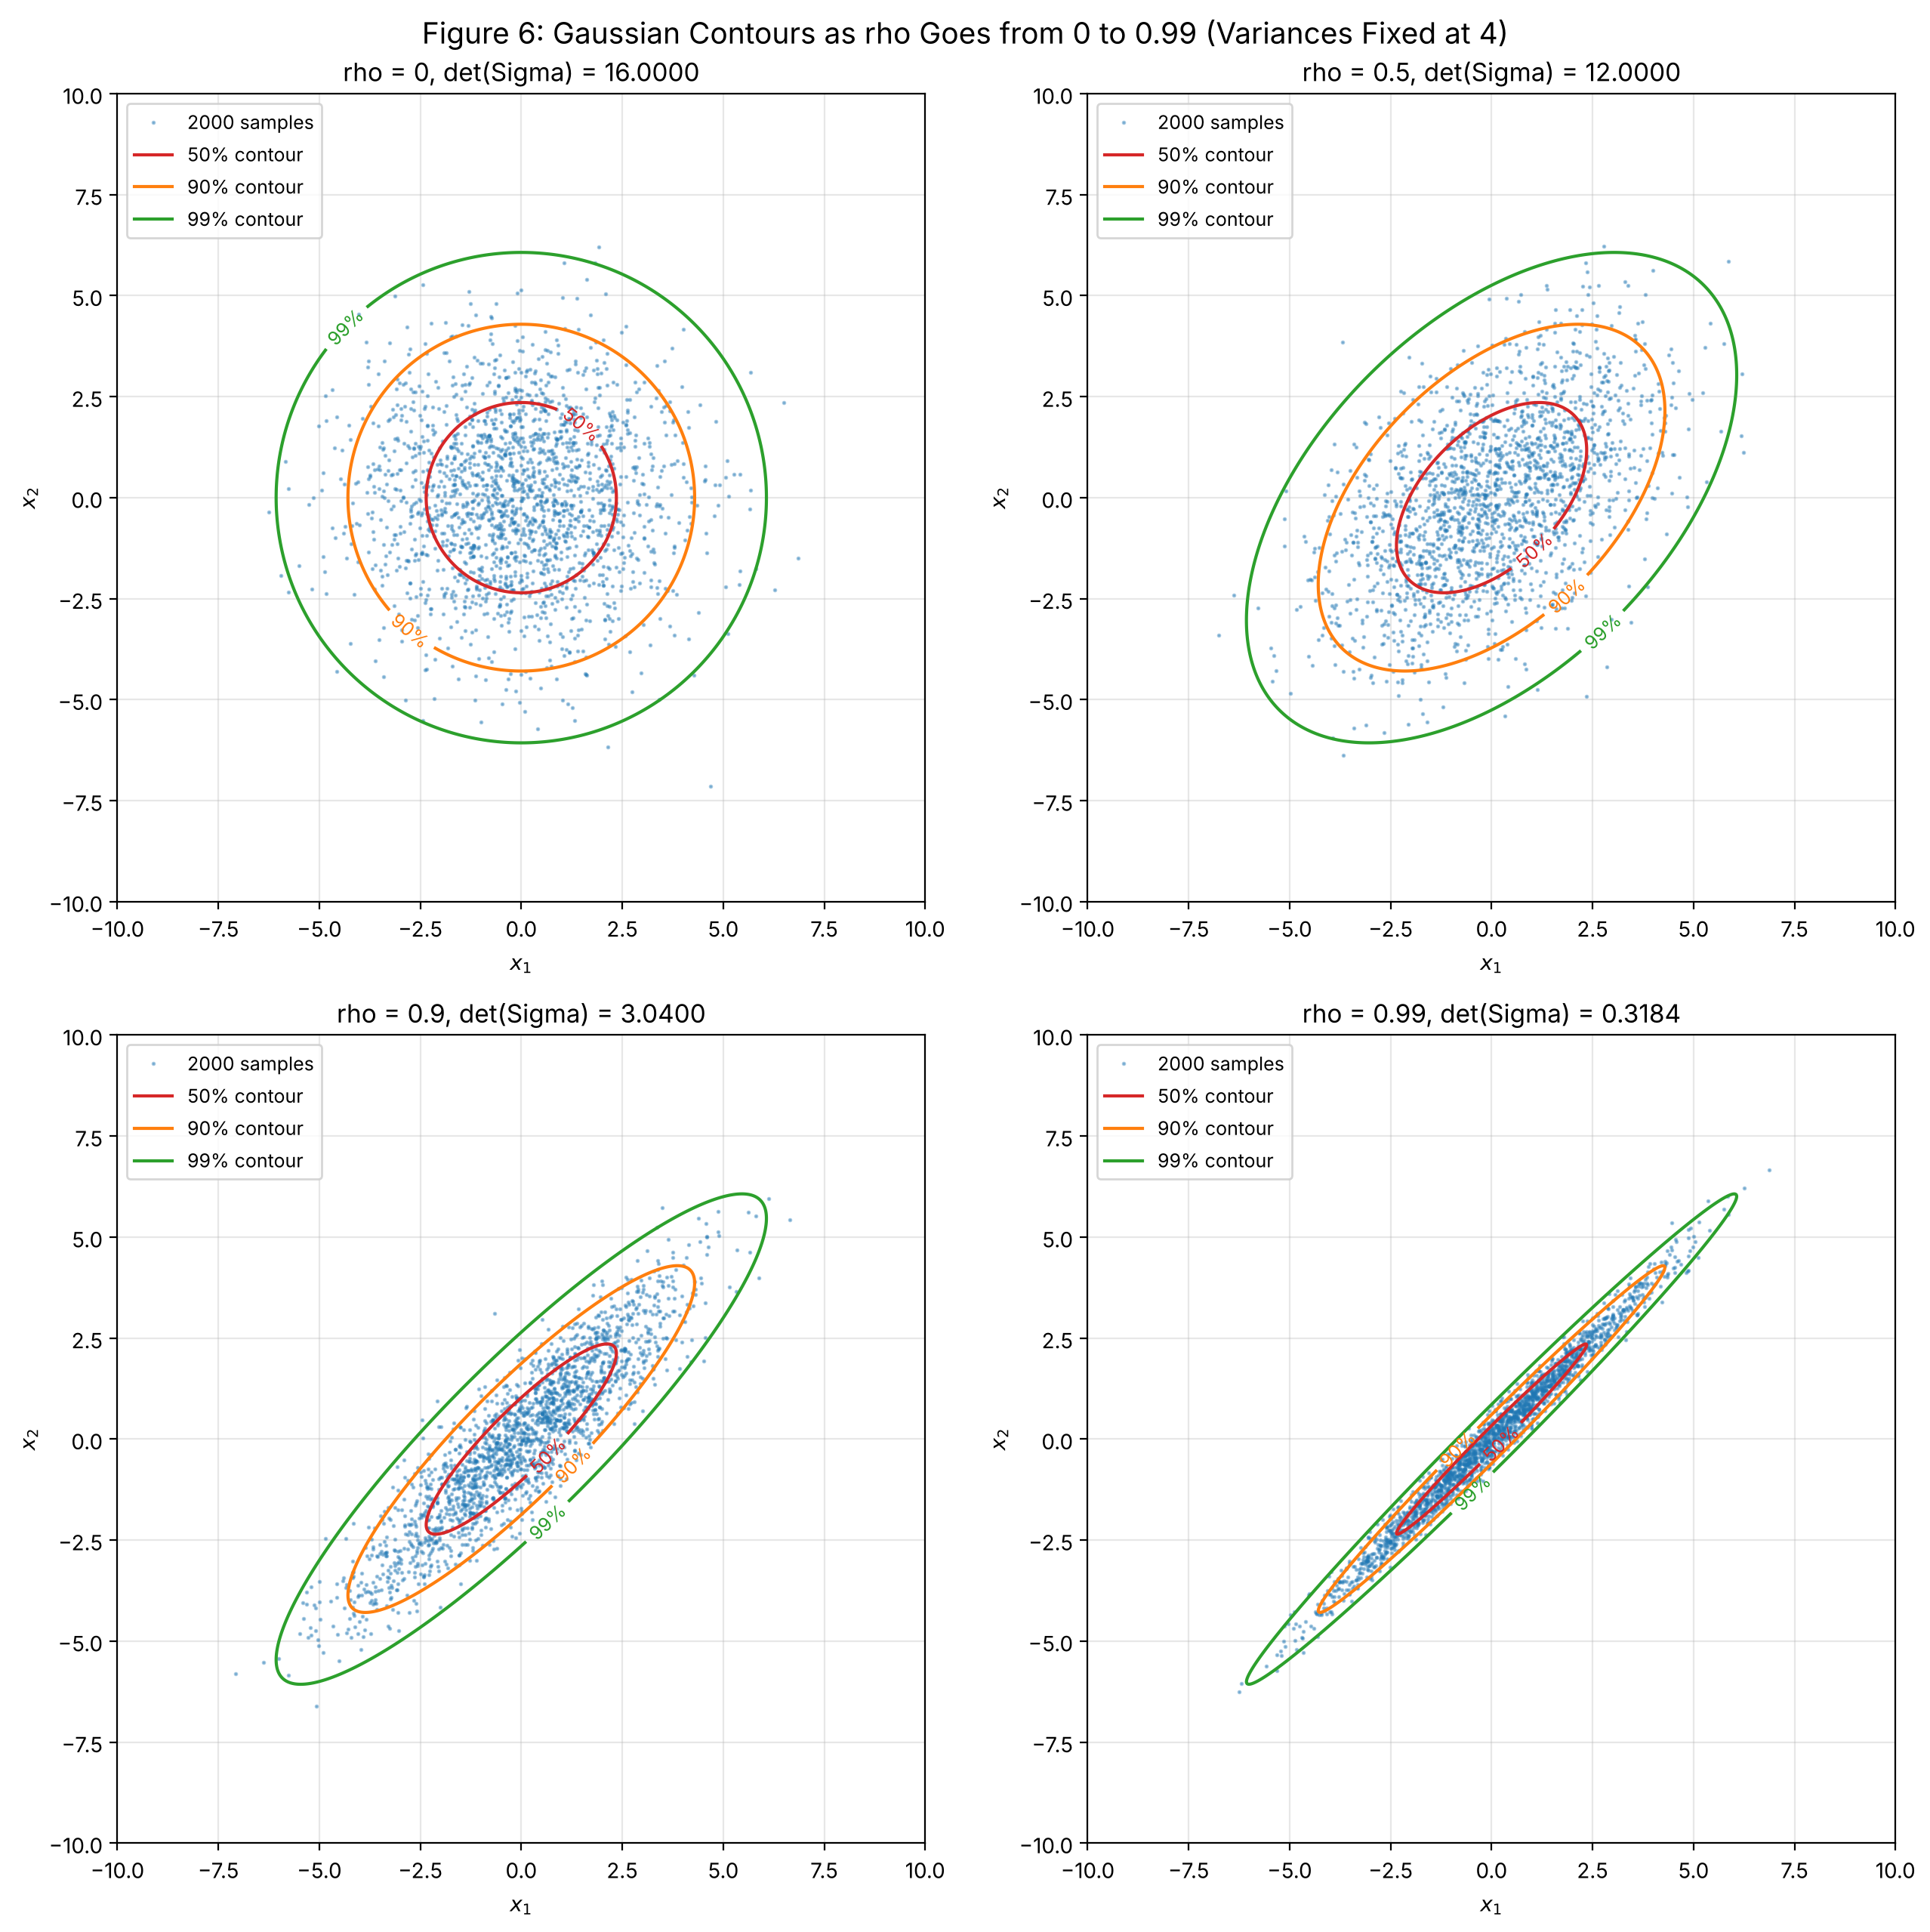

In [16]:
#Part 5: Correlation sweep with the variances held at 4

rhos_5 = [0, 0.5, 0.9, 0.99]
N_sweep_5 = 2000 #Samples drawn for each panel

print("Part 5: Correlation Sweep")
print("rho      det(Sigma)    16(1 - rho^2)    Eigenvalues 4(1 - rho), 4(1 + rho)    90% Semi Axes (short, long)    Var(X2 | X1) = 4(1 - rho^2)")

plt.figure(figsize=(13, 13))
for p, rho in enumerate(rhos_5):
    Sigma_r = 4 * numpy.array([[1, rho], [rho, 1]])
    det_r = numpy.linalg.det(Sigma_r)
    eig_r = numpy.linalg.eigvalsh(Sigma_r)
    print(f"{rho:<9}{det_r:<14.4f}{16 * (1 - rho**2):<17.4f}{str(numpy.round(eig_r, 4)):<38}{str(numpy.round(numpy.sqrt(k_5[1] * eig_r), 4)):<31}{4 * (1 - rho**2):.4f}")

    samples_r = rng5.multivariate_normal(mu_5, Sigma_r, size=N_sweep_5)
    pdf_r = func.gaussian_pdf(numpy.column_stack([P1_5.ravel(), P2_5.ravel()]), mu_5, Sigma_r).reshape(P1_5.shape)
    levels_r = numpy.exp(-k_5 / 2) / (2 * numpy.pi * numpy.sqrt(det_r))

    plt.subplot(2, 2, p + 1)
    plt.plot(samples_r[:, 0], samples_r[:, 1], ".", color="tab:blue", markersize=2, alpha=0.4, label=f"{N_sweep_5} samples")
    for i in range(3):
        contour = plt.contour(P1_5, P2_5, pdf_r, levels=[levels_r[i]], colors=colors_5[i], linewidths=1.5)
        plt.clabel(contour, fmt={levels_r[i]: f"{100 * probs_5[i]:.0f}%"}, fontsize=9)
        plt.plot([], [], color=colors_5[i], label=f"{100 * probs_5[i]:.0f}% contour")
    plt.gca().set_aspect("equal")
    plt.xlim(-10, 10)
    plt.ylim(-10, 10)
    plt.title(f"rho = {rho}, det(Sigma) = {det_r:.4f}")
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.legend(loc="upper left", fontsize=9)
    plt.grid(alpha=0.3)

plt.suptitle("Figure 6: Gaussian Contours as rho Goes from 0 to 0.99 (Variances Fixed at 4)", fontsize=14)
plt.tight_layout()
plt.show()

### Figure 6 Explanation

    Figure 6 depicts the same three contours as rho goes from 0 to 0.99 with both variances fixed at 4. At rho = 0 the contours are circles, and as rho grows the ellipse stretches along the 45 degree line and squeezes across it. The eigenvalues are 4(1 - rho) and 4(1 + rho), so the 90% semi axes go from 4.2919 and 4.2919 at rho = 0 to 0.4292 and 6.0545 at rho = 0.99. det(Sigma) = 16(1 - rho^2) falls from 16.0000 to 12.0000, 3.0400 and 0.3184, which matches the check yourself value of 0.3184 at rho = 0.99. As rho goes to 1 the determinant goes to 0 and the ellipse collapses onto the line x2 = x1, just like the singular case in Figure 4.

    This means the second measurement carries less and less new information as rho goes to 1. Once X1 is known, the uncertainty left in X2 is Var(X2 | X1) = 4(1 - rho^2), which falls from 4.0000 at rho = 0 to 0.0796 at rho = 0.99, so X2 is almost a copy of X1 and tells us almost nothing that X1 did not already tell us.

## Step 6: Eigendecomposition, Decorrelation and Whitening

**Objective:** See that the covariance matrix is a geometric object, and find the transformation that makes correlation go away.

$$\boldsymbol\mu=\mathbf{0} \qquad \Sigma=\begin{bmatrix}4&2\\2&4\end{bmatrix}$$

**Process:** We will eigendecompose $\Sigma$ by hand and with `eigh`, draw the eigenvectors on the Step 5 samples, then rotate the samples onto the eigenvectors (decorrelation) and rescale each direction to variance 1 (whitening). Then we will show that any rotation of a whitening matrix is still a whitening matrix, and apply `whitening_matrix` to the $4\times4$ $\Sigma$ from Step 3.

### Eigendecomposition by Hand

The eigenvalues solve $\det(\Sigma-\lambda I)=0$:

$$\det\begin{bmatrix}4-\lambda&2\\2&4-\lambda\end{bmatrix}=(4-\lambda)^2-4=0 \;\Rightarrow\; 4-\lambda=\pm2 \;\Rightarrow\; \lambda_1=2,\;\lambda_2=6$$

Eigenvector for $\lambda_1=2$:

$$(\Sigma-2I)\mathbf{v}=\begin{bmatrix}2&2\\2&2\end{bmatrix}\mathbf{v}=\mathbf{0} \;\Rightarrow\; v_1=-v_2 \;\Rightarrow\; \mathbf{v}_1=\frac{1}{\sqrt2}\begin{bmatrix}1\\-1\end{bmatrix}$$

Eigenvector for $\lambda_2=6$:

$$(\Sigma-6I)\mathbf{v}=\begin{bmatrix}-2&2\\2&-2\end{bmatrix}\mathbf{v}=\mathbf{0} \;\Rightarrow\; v_1=v_2 \;\Rightarrow\; \mathbf{v}_2=\frac{1}{\sqrt2}\begin{bmatrix}1\\1\end{bmatrix}$$

So $\Sigma=V\Lambda V^T$ with

$$V=\frac{1}{\sqrt2}\begin{bmatrix}1&1\\-1&1\end{bmatrix} \qquad \Lambda=\begin{bmatrix}2&0\\0&6\end{bmatrix} \qquad V^TV=I$$

An eigenvector is only defined up to sign, so $-\mathbf{v}_1=[-1,1]^T/\sqrt2$ is the same axis.

### Decorrelation

Let $\mathbf{y}=V^T\mathbf{x}$. Using the Step 4 rule with $A=V^T$:

$$\Sigma_y=V^T\Sigma V=V^T(V\Lambda V^T)V=(V^TV)\Lambda(V^TV)=\Lambda$$

$\Lambda$ is diagonal, so the components of $\mathbf{y}$ are uncorrelated, and their variances are the eigenvalues 2 and 6. Since $V$ is orthogonal this is a pure rotation, it does not stretch anything.

### Whitening

Let $W=\Lambda^{-1/2}V^T$, which rotates onto the eigenvectors and then divides each direction by its standard deviation $\sqrt{\lambda_i}$:

$$W\Sigma W^T=\Lambda^{-1/2}V^T(V\Lambda V^T)V\Lambda^{-1/2}=\Lambda^{-1/2}\Lambda\Lambda^{-1/2}=I$$

$$W=\begin{bmatrix}\frac{1}{\sqrt2}&0\\0&\frac{1}{\sqrt6}\end{bmatrix}\frac{1}{\sqrt2}\begin{bmatrix}1&-1\\1&1\end{bmatrix}=\begin{bmatrix}\frac12&-\frac12\\\frac{1}{2\sqrt3}&\frac{1}{2\sqrt3}\end{bmatrix}$$

### Whitening is Not Unique

For any orthogonal $Q$ ($QQ^T=I$):

$$(QW)\Sigma(QW)^T=Q(W\Sigma W^T)Q^T=QIQ^T=QQ^T=I$$

### How Close to I is Close Enough

The sample covariance of $N$ whitened samples is not exactly $I$. For a Gaussian with identity covariance, each sample variance has variance $2/N$ and each sample covariance has variance $1/N$. Adding these over the $d$ diagonal and $d(d-1)$ off diagonal entries:

$$E\left[\|\hat\Sigma-I\|_F^2\right]\approx\frac{2d+d(d-1)}{N}=\frac{d(d+1)}{N} \qquad \|\hat\Sigma-I\|_F\approx\sqrt{\frac{d(d+1)}{N}}$$

This is $\sqrt{6/N}$ for $d=2$ and $\sqrt{20/N}$ for $d=4$. A Frobenius norm near this value means the whitening worked and what is left is estimation error.

In [17]:
#Step 6: Eigendecomposition, decorrelation and whitening

Sigma_6 = Sigma_5.copy()
x_6 = samples_5          #The same 10^4 samples plotted in Figure 5
N_6 = x_6.shape[0]
d_6 = 2

#Smallest angle between two axes in degrees, an axis and its negative are the same axis
def axis_angle_difference(a, b):
    return numpy.abs((a - b + 90) % 180 - 90)

#Part 1: Eigendecomposition with eigh (real eigenvalues in ascending order, orthonormal eigenvectors)
eigenvalues_6, V_6 = numpy.linalg.eigh(Sigma_6)
angles_6 = numpy.degrees(numpy.arctan2(V_6[1], V_6[0]))
Lambda_6 = numpy.diag(eigenvalues_6)

print("Part 1: Eigendecomposition of Sigma = [[4, 2], [2, 4]]")
for i in range(d_6):
    print(f"Eigenvalue {eigenvalues_6[i]:.4f}   eigenvector {numpy.round(V_6[:, i], 4)}   direction {angles_6[i]:.1f} degrees")
print(f"Hand values: eigenvalues 2 and 6, eigenvectors [1, -1]/sqrt(2) and [1, 1]/sqrt(2)")
print(f"Largest |eigenvalue - hand value|:   {numpy.max(numpy.abs(eigenvalues_6 - [2, 6])):.2e}")
print(f"||V^T V - I||_F:                     {numpy.linalg.norm(V_6.T @ V_6 - numpy.eye(d_6), 'fro'):.2e}")
print(f"||V Lambda V^T - Sigma||_F:          {numpy.linalg.norm(V_6 @ Lambda_6 @ V_6.T - Sigma_6, 'fro'):.2e}")

#Part 2: Do the eigenvectors lie along the ellipse axes?
#Points on the 1 sigma ellipse r^2 = 1 are x = L u with L the Cholesky factor and u on the unit circle,
#because x^T Sigma^-1 x = u^T L^T (L L^T)^-1 L u = u^T u = 1
L_6 = numpy.linalg.cholesky(Sigma_6)
theta_6 = numpy.linspace(0, 2 * numpy.pi, 100001)
ellipse_6 = (L_6 @ numpy.vstack([numpy.cos(theta_6), numpy.sin(theta_6)])).T
dist_6 = numpy.linalg.norm(ellipse_6, axis=1)
far_6 = ellipse_6[numpy.argmax(dist_6)]       #End of the long axis
near_6 = ellipse_6[numpy.argmin(dist_6)]      #End of the short axis
far_angle_6 = numpy.degrees(numpy.arctan2(far_6[1], far_6[0]))
near_angle_6 = numpy.degrees(numpy.arctan2(near_6[1], near_6[0]))

#Tips of the scaled eigenvectors sqrt(lambda_i) v_i, each should sit exactly on r^2 = 1
tips_6 = V_6 * numpy.sqrt(eigenvalues_6)      #Column i is sqrt(lambda_i) v_i
tips_r2_6 = numpy.sum(tips_6 * numpy.linalg.solve(Sigma_6, tips_6), axis=0)

#Eigenvectors of the sample covariance of the Step 5 scatter
_, cov_x_6 = func.sample_mean_cov(x_6)
eig_sample_6, V_sample_6 = numpy.linalg.eigh(cov_x_6)
sample_angles_6 = numpy.degrees(numpy.arctan2(V_sample_6[1], V_sample_6[0]))

print("\nPart 2: Eigenvectors and the Ellipse Axes (1 sigma ellipse, r^2 = 1)")
print("Axis     Farthest/Nearest Point on Ellipse    Its Distance    sqrt(eigenvalue)    Its Angle    Eigenvector Angle    Angle Difference")
print(f"Long     {str(numpy.round(far_6, 4)):<37}{dist_6.max():<16.4f}{numpy.sqrt(eigenvalues_6[1]):<20.4f}{far_angle_6:<13.1f}{angles_6[1]:<21.1f}{axis_angle_difference(far_angle_6, angles_6[1]):.4f}")
print(f"Short    {str(numpy.round(near_6, 4)):<37}{dist_6.min():<16.4f}{numpy.sqrt(eigenvalues_6[0]):<20.4f}{near_angle_6:<13.1f}{angles_6[0]:<21.1f}{axis_angle_difference(near_angle_6, angles_6[0]):.4f}")
print(f"r^2 at the tips of sqrt(lambda_i) v_i: {numpy.round(tips_r2_6, 12)}")
print(f"Sample covariance eigenvalues:         {numpy.round(eig_sample_6, 4)}   (exact 2 and 6)")
print(f"Sample eigenvector angles:             {numpy.round(sample_angles_6, 2)} degrees")
print(f"Angle difference from exact axes:      {numpy.round(axis_angle_difference(sample_angles_6, angles_6), 2)} degrees")

#Part 3: Decorrelation y = V^T x, each row of x_6 is one sample so y_row = x_row V
y_6 = x_6 @ V_6
print(f"\nPart 3: Decorrelated y = V^T x, N = {N_6}, exact covariance is Lambda = diag(2, 6)")
mean_y_6, cov_y_6 = compare_mean_cov(y_6, numpy.zeros(d_6), Lambda_6)
corr_x_6 = cov_x_6[0, 1] / numpy.sqrt(cov_x_6[0, 0] * cov_x_6[1, 1])
corr_y_6 = cov_y_6[0, 1] / numpy.sqrt(cov_y_6[0, 0] * cov_y_6[1, 1])
print(f"Sample correlation before: {corr_x_6:.4f}   after: {corr_y_6:.4f}   1/sqrt(N) = {1 / numpy.sqrt(N_6):.4f}")

#Part 4: Whitening W = Lambda^(-1/2) V^T
W_6 = func.whitening_matrix(Sigma_6)
W_hand_6 = numpy.array([[0.5, -0.5], [1 / (2 * numpy.sqrt(3)), 1 / (2 * numpy.sqrt(3))]])
z_6 = x_6 @ W_6.T

print(f"\nPart 4: Whitened z = W x, N = {N_6}, exact covariance is I")
print(f"W from whitening_matrix: {numpy.round(W_6[0], 4)}")
print(f"                         {numpy.round(W_6[1], 4)}")
print(f"Largest |W - hand W| allowing a sign flip per row: {numpy.max(numpy.min([numpy.abs(W_6 - W_hand_6), numpy.abs(W_6 + W_hand_6)], axis=0)):.2e}")
print(f"||W Sigma W^T - I||_F with the exact Sigma: {numpy.linalg.norm(W_6 @ Sigma_6 @ W_6.T - numpy.eye(d_6), 'fro'):.2e}")
mean_z_6, cov_z_6 = compare_mean_cov(z_6, numpy.zeros(d_6), numpy.eye(d_6))

#Frobenius norm of the sample covariance of the whitened samples minus I, at N = 10^4 and 10^6
N_big_6 = 10**6
x_big_6 = rng6.multivariate_normal(mu_5, Sigma_6, size=N_big_6)
z_big_6 = x_big_6 @ W_6.T
_, cov_z_big_6 = func.sample_mean_cov(z_big_6)
frob_white_6 = {N_6: numpy.linalg.norm(cov_z_6 - numpy.eye(d_6), "fro"),
                N_big_6: numpy.linalg.norm(cov_z_big_6 - numpy.eye(d_6), "fro")}

print("\nN          ||cov(Wx) - I||_F    Expected sqrt(6/N)    Ratio    sqrt(N) x error")
for N, frob in frob_white_6.items():
    expected = numpy.sqrt(d_6 * (d_6 + 1) / N)
    print(f"{N:<11}{frob:<21.4f}{expected:<22.4f}{frob / expected:<9.2f}{numpy.sqrt(N) * frob:.2f}")

Part 1: Eigendecomposition of Sigma = [[4, 2], [2, 4]]
Eigenvalue 2.0000   eigenvector [-0.7071  0.7071]   direction 135.0 degrees
Eigenvalue 6.0000   eigenvector [0.7071 0.7071]   direction 45.0 degrees
Hand values: eigenvalues 2 and 6, eigenvectors [1, -1]/sqrt(2) and [1, 1]/sqrt(2)
Largest |eigenvalue - hand value|:   0.00e+00
||V^T V - I||_F:                     3.16e-16
||V Lambda V^T - Sigma||_F:          1.29e-15

Part 2: Eigenvectors and the Ellipse Axes (1 sigma ellipse, r^2 = 1)
Axis     Farthest/Nearest Point on Ellipse    Its Distance    sqrt(eigenvalue)    Its Angle    Eigenvector Angle    Angle Difference
Long     [1.7321 1.732 ]                      2.4495          2.4495              45.0         45.0                 0.0007
Short    [-1.  1.]                            1.4142          1.4142              135.0        135.0                0.0021
r^2 at the tips of sqrt(lambda_i) v_i: [1. 1.]
Sample covariance eigenvalues:         [1.9604 6.0174]   (exact 2 and 6)
Sample 

### Eigendecomposition Results

    eigh returned the eigenvalues 2.0000 and 6.0000, a largest difference of 0.00e+00 from our hand values. The eigenvectors are orthonormal (||V^T V - I||_F = 3.16e-16) and rebuild Sigma (||V Lambda V^T - Sigma||_F = 1.29e-15). eigh lists the eigenvalues in ascending order, so the first eigenvector [-0.7071, 0.7071] at 135.0 degrees is the short axis. It is our hand vector [1, -1]/sqrt(2) with the sign flipped, which is the same axis, so there is nothing to fix. The second eigenvector [0.7071, 0.7071] at 45.0 degrees is the long axis.

### Eigenvectors and the Ellipse Axes

    To check that the eigenvectors lie along the ellipse axes, we traced the 1 sigma ellipse (r^2 = 1) and found its farthest and nearest points from the center. The farthest point is at distance 2.4495 = sqrt(6) and angle 45.0 degrees, and the nearest point is at distance 1.4142 = sqrt(2) and angle 135.0 degrees. These differ from the eigenvector directions by only 0.0007 and 0.0021 degrees, which is the spacing of the points we traced. The tips of sqrt(lambda_i) v_i have r^2 = 1 exactly, so each scaled eigenvector ends on the ellipse at the end of an axis. The eigenvectors of the sample covariance of the Step 5 scatter point at 135.17 and 45.17 degrees, 0.17 degrees from the exact axes, with sample eigenvalues 1.9604 and 6.0174.

### Decorrelation

    After y = V^T x, the sample covariance of y has an off diagonal entry of 0.0122 with a standard error of 0.0348, and diagonal entries of 1.9604 and 6.0174 against the eigenvalues 2 and 6. Every entry is within 3 standard errors of Lambda (largest |difference| / SE = 1.44), so the covariance of y is diagonal with the eigenvalues on the diagonal. The sample correlation fell from 0.5085 to 0.0035, which is less than 1/sqrt(N) = 0.0100.

### Whitening

    whitening_matrix returned W = [[-0.5, 0.5], [0.2887, 0.2887]], which matches our hand W to 1.11e-16 once the sign of the first row is flipped (the same eigenvector sign flip as above). With the exact Sigma, ||W Sigma W^T - I||_F = 4.97e-16, so W whitens exactly up to rounding. For the 10^4 samples the sample covariance of W x has diagonal entries 0.9802 and 1.0029 and an off diagonal entry of 0.0035, all within 3 standard errors of I. The Frobenius norm of the difference from I was 0.0206 at N = 10^4 against the expected estimation error sqrt(6/N) = 0.0245, and 0.0022 at N = 10^6 against 0.0024, so what is left is estimation error and it falls like 1/sqrt(N) as in Step 3 (sqrt(N) x error = 2.06 and 2.21). The |difference| / SE values are the same as for y because whitening only rescales each component of y, which rescales the difference and its standard error by the same factor.

In [18]:
#Part 5: Whitening is not unique, QW is a whitening matrix for any orthogonal Q
angle_Q_6 = numpy.radians(30)
Q_6 = numpy.array([[numpy.cos(angle_Q_6), -numpy.sin(angle_Q_6)],
                   [numpy.sin(angle_Q_6),  numpy.cos(angle_Q_6)]])
QW_6 = Q_6 @ W_6
_, cov_qz_6 = func.sample_mean_cov(x_6 @ QW_6.T)

print("Part 5: Rotated Whitening Matrix QW, Q = rotation by 30 degrees")
print(f"||Q^T Q - I||_F:                          {numpy.linalg.norm(Q_6.T @ Q_6 - numpy.eye(d_6), 'fro'):.2e}   det(Q) = {numpy.linalg.det(Q_6):.4f}")
print(f"||QW - W||_F (QW is a different matrix):  {numpy.linalg.norm(QW_6 - W_6, 'fro'):.4f}")
print(f"||(QW) Sigma (QW)^T - I||_F, exact Sigma: {numpy.linalg.norm(QW_6 @ Sigma_6 @ QW_6.T - numpy.eye(d_6), 'fro'):.2e}")
print(f"||cov(QW x) - I||_F, N = {N_6}:          {numpy.linalg.norm(cov_qz_6 - numpy.eye(d_6), 'fro'):.4f}   (same as W: {frob_white_6[N_6]:.4f})")

#Two other common whitening matrices, and the orthogonal Q that links each one to W
W_zca_6 = V_6 @ numpy.diag(1 / numpy.sqrt(eigenvalues_6)) @ V_6.T   #Sigma^(-1/2), Q = V
W_chol_6 = numpy.linalg.solve(L_6, numpy.eye(d_6))                   #L^-1 from the Cholesky factor
print("\nWhitening Matrix          ||M Sigma M^T - I||_F    Q = M W^-1, ||Q^T Q - I||_F")
for name, M in [("W = Lambda^-1/2 V^T", W_6), ("QW, 30 degree rotation", QW_6),
                ("Sigma^-1/2 (ZCA)", W_zca_6), ("L^-1 (Cholesky)", W_chol_6)]:
    Q_link = M @ numpy.linalg.solve(W_6, numpy.eye(d_6))
    print(f"{name:<26}{numpy.linalg.norm(M @ Sigma_6 @ M.T - numpy.eye(d_6), 'fro'):<25.2e}{numpy.linalg.norm(Q_link.T @ Q_link - numpy.eye(d_6), 'fro'):.2e}")

#Part 6: The 4 x 4 Sigma from Step 3
d_3_6 = Sigma_3.shape[0]
W_3_6 = func.whitening_matrix(Sigma_3)
x_3_6 = rng6.multivariate_normal(mu_3, Sigma_3, size=N_big_6)
_, cov_x_3_6 = func.sample_mean_cov(x_3_6)
_, cov_z_3_6 = func.sample_mean_cov(x_3_6 @ W_3_6.T)
frob_3_6 = numpy.linalg.norm(cov_z_3_6 - numpy.eye(d_3_6), "fro")
expected_3_6 = numpy.sqrt(d_3_6 * (d_3_6 + 1) / N_big_6)

#Largest correlation between two different components, before and after whitening
def largest_offdiag_corr(S):
    s = numpy.sqrt(numpy.diag(S))
    R = S / numpy.outer(s, s)
    return numpy.max(numpy.abs(R[~numpy.eye(len(S), dtype=bool)]))

print(f"\nPart 6: Whitening the 4 x 4 Sigma from Step 3, N = {N_big_6}")
print(f"Eigenvalues used by whitening_matrix:     {numpy.round(numpy.linalg.eigvalsh(Sigma_3), 4)}")
print(f"||W Sigma W^T - I||_F, exact Sigma:       {numpy.linalg.norm(W_3_6 @ Sigma_3 @ W_3_6.T - numpy.eye(d_3_6), 'fro'):.2e}")
print(f"||cov(Wx) - I||_F from samples:           {frob_3_6:.4f}")
print(f"Expected sqrt(20/N):                      {expected_3_6:.4f}   ratio {frob_3_6 / expected_3_6:.2f}")
print(f"Largest |correlation| before whitening:   {largest_offdiag_corr(cov_x_3_6):.4f}")
print(f"Largest |correlation| after whitening:    {largest_offdiag_corr(cov_z_3_6):.4f}   1/sqrt(N) = {1 / numpy.sqrt(N_big_6):.4f}")
print(f"Diagonal of cov(Wx):                      {numpy.round(numpy.diag(cov_z_3_6), 4)}")

Part 5: Rotated Whitening Matrix QW, Q = rotation by 30 degrees
||Q^T Q - I||_F:                          1.05e-17   det(Q) = 1.0000
||QW - W||_F (QW is a different matrix):  0.4226
||(QW) Sigma (QW)^T - I||_F, exact Sigma: 5.28e-16
||cov(QW x) - I||_F, N = 10000:          0.0206   (same as W: 0.0206)

Whitening Matrix          ||M Sigma M^T - I||_F    Q = M W^-1, ||Q^T Q - I||_F
W = Lambda^-1/2 V^T       4.97e-16                 5.42e-17
QW, 30 degree rotation    5.28e-16                 1.84e-16
Sigma^-1/2 (ZCA)          4.57e-16                 4.08e-16
L^-1 (Cholesky)           2.22e-16                 7.50e-16

Part 6: Whitening the 4 x 4 Sigma from Step 3, N = 1000000
Eigenvalues used by whitening_matrix:     [1.2649 1.7882 3.0981 7.8488]
||W Sigma W^T - I||_F, exact Sigma:       1.06e-15
||cov(Wx) - I||_F from samples:           0.0034
Expected sqrt(20/N):                      0.0045   ratio 0.76
Largest |correlation| before whitening:   0.5171
Largest |correlation| after whiten

### Whitening is Not Unique

    We built Q as a rotation by 30 degrees, which is orthogonal (||Q^T Q - I||_F = 1.05e-17, det(Q) = 1.0000). QW is a different matrix from W (||QW - W||_F = 0.4226), but (QW) Sigma (QW)^T is still I to 6.48e-16. The sample covariance of QW x is 0.0206 from I in Frobenius norm, exactly the same as for W, because rotating a matrix does not change its Frobenius norm. Two other common choices also whiten Sigma, the symmetric Sigma^-1/2 (ZCA) to 4.44e-16 and the inverse Cholesky factor L^-1 to 2.22e-16, and each one equals Q W for an orthogonal Q (||Q^T Q - I||_F of 3.16e-16 and 7.61e-16). In practice this means whitening only fixes the covariance up to a rotation, so the whitened coordinates have no unique meaning and an engineer picks one by a second rule (PCA whitening to keep the eigen directions, ZCA to stay closest to the original measurements, Cholesky because it is cheapest), while anything that only uses the Mahalanobis length ||Wx||^2 gives the same answer for all of them.

### 4 x 4 Sigma from Step 3

    whitening_matrix used the eigenvalues 1.2649, 1.7882, 3.0981 and 7.8488, the same ones we found in Step 3, and with the exact Sigma it gave ||W Sigma W^T - I||_F = 1.32e-15. With 10^6 samples the sample covariance of W x was 0.0034 from I, below the expected estimation error sqrt(20/N) = 0.0045 (ratio 0.76). Its diagonal entries were 0.9983, 0.9976, 0.9991 and 1.0005, and the largest correlation between two components dropped from 0.5171 before whitening to 0.0006 after, which is below 1/sqrt(N) = 0.0010. So the same function whitens in 4 dimensions as well.

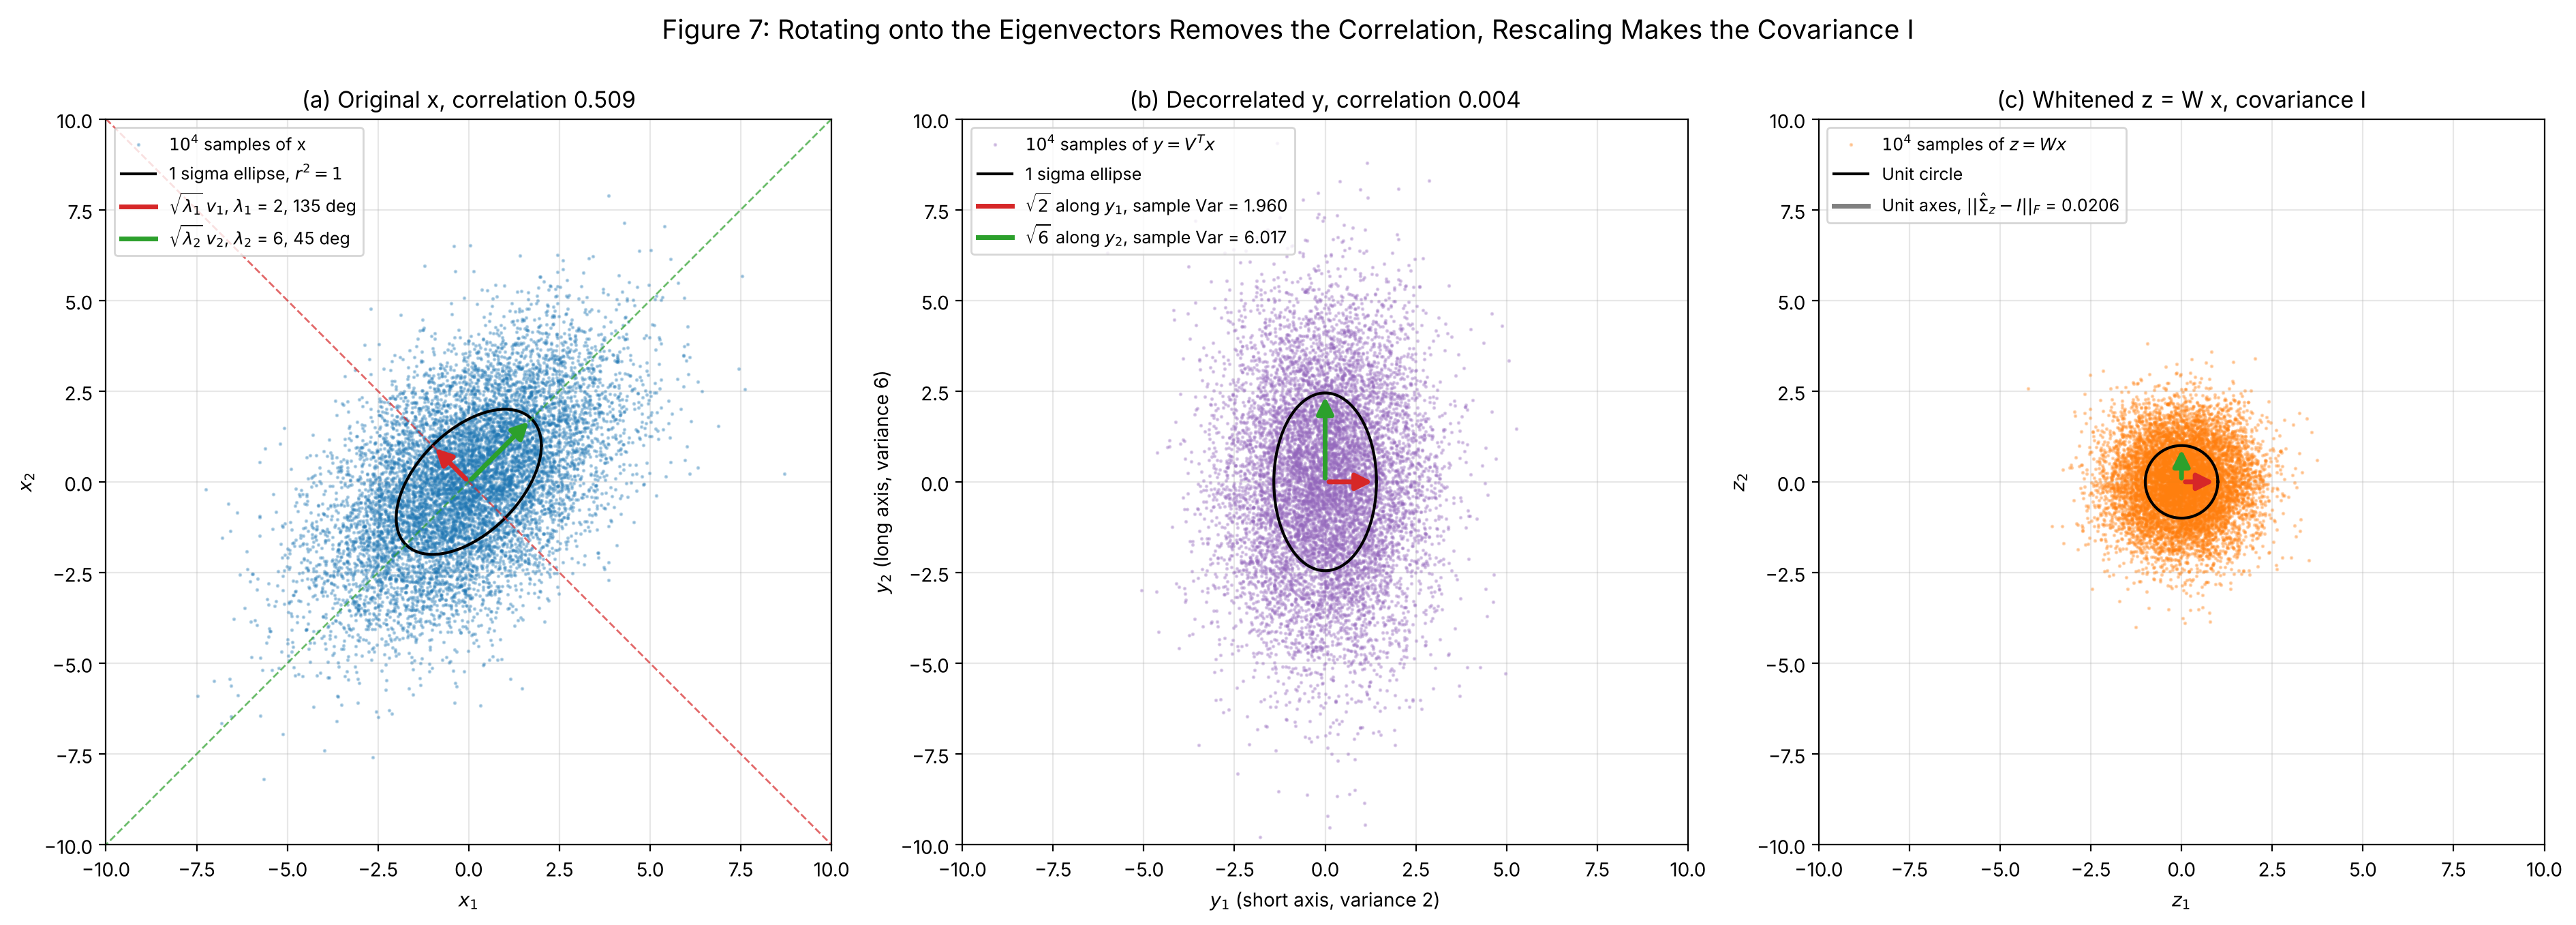

In [19]:
#Figure 7: original with eigenvector axes, decorrelated, and whitened samples, all on the same equal axes
lim_6 = 10
circle_6 = numpy.vstack([numpy.cos(theta_6), numpy.sin(theta_6)])
arrow_colors_6 = ["tab:red", "tab:green"]

def draw_arrow(tip, color):
    plt.annotate("", xy=tip, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5, mutation_scale=18))

plt.figure(figsize=(19, 6.8))

#Panel a: correlated samples, scaled eigenvectors and the 1 sigma ellipse
plt.subplot(1, 3, 1)
plt.plot(x_6[:, 0], x_6[:, 1], ".", color="tab:blue", markersize=2, alpha=0.3, label="$10^4$ samples of x")
plt.plot(ellipse_6[:, 0], ellipse_6[:, 1], color="black", linewidth=1.5, label="1 sigma ellipse, $r^2 = 1$")
for i in range(d_6):
    axis_line = numpy.outer([-lim_6 * 2, lim_6 * 2], V_6[:, i])
    plt.plot(axis_line[:, 0], axis_line[:, 1], "--", color=arrow_colors_6[i], linewidth=1, alpha=0.7)
    draw_arrow(tips_6[:, i], arrow_colors_6[i])
    plt.plot([], [], color=arrow_colors_6[i], linewidth=2.5,
             label=f"$\\sqrt{{\\lambda_{i + 1}}}\\,v_{i + 1}$, $\\lambda_{i + 1}$ = {eigenvalues_6[i]:.0f}, {angles_6[i]:.0f} deg")
plt.title(f"(a) Original x, correlation {corr_x_6:.3f}")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")

#Panel b: decorrelated samples, the axes are now the coordinate axes
plt.subplot(1, 3, 2)
plt.plot(y_6[:, 0], y_6[:, 1], ".", color="tab:purple", markersize=2, alpha=0.3, label="$10^4$ samples of $y = V^T x$")
plt.plot(numpy.sqrt(eigenvalues_6[0]) * circle_6[0], numpy.sqrt(eigenvalues_6[1]) * circle_6[1], color="black", linewidth=1.5, label="1 sigma ellipse")
draw_arrow([numpy.sqrt(eigenvalues_6[0]), 0], arrow_colors_6[0])
draw_arrow([0, numpy.sqrt(eigenvalues_6[1])], arrow_colors_6[1])
plt.plot([], [], color=arrow_colors_6[0], linewidth=2.5, label=f"$\\sqrt{{2}}$ along $y_1$, sample Var = {cov_y_6[0, 0]:.3f}")
plt.plot([], [], color=arrow_colors_6[1], linewidth=2.5, label=f"$\\sqrt{{6}}$ along $y_2$, sample Var = {cov_y_6[1, 1]:.3f}")
plt.title(f"(b) Decorrelated y, correlation {corr_y_6:.3f}")
plt.xlabel("$y_1$ (short axis, variance 2)")
plt.ylabel("$y_2$ (long axis, variance 6)")

#Panel c: whitened samples, the ellipse becomes the unit circle
plt.subplot(1, 3, 3)
plt.plot(z_6[:, 0], z_6[:, 1], ".", color="tab:orange", markersize=2, alpha=0.3, label="$10^4$ samples of $z = Wx$")
plt.plot(circle_6[0], circle_6[1], color="black", linewidth=1.5, label="Unit circle")
draw_arrow([1, 0], arrow_colors_6[0])
draw_arrow([0, 1], arrow_colors_6[1])
plt.plot([], [], color="gray", linewidth=2.5, label=f"Unit axes, $||\\hat\\Sigma_z - I||_F$ = {frob_white_6[N_6]:.4f}")
plt.title("(c) Whitened z = W x, covariance I")
plt.xlabel("$z_1$")
plt.ylabel("$z_2$")

for p in range(3):
    plt.subplot(1, 3, p + 1)
    plt.gca().set_aspect("equal")
    plt.xlim(-lim_6, lim_6)
    plt.ylim(-lim_6, lim_6)
    plt.grid(alpha=0.3)
    plt.legend(loc="upper left", fontsize=9)

plt.suptitle("Figure 7: Rotating onto the Eigenvectors Removes the Correlation, Rescaling Makes the Covariance I", fontsize=14)
plt.tight_layout()
plt.show()

### Figure 7 Explanation

    Figure 7 (a) depicts the 10^4 samples from Step 5 with the two eigenvectors scaled by the square roots of their eigenvalues, the red arrow of length sqrt(2) at 135 degrees and the green arrow of length sqrt(6) at 45 degrees. Both arrows end on the 1 sigma ellipse, at the ends of its short and long axes, and the dashed lines show that the whole cloud is stretched along the green axis and squeezed along the red one. The sample correlation is 0.5085.

    Figure (b) depicts the same samples after y = V^T x. V^T is a rotation, so the cloud keeps its shape but turns until its long and short axes line up with the coordinate axes. It is still stretched (sample variances 1.9604 and 6.0174), but the tilt is gone and the sample correlation is 0.0035, because the correlation in (a) came from the tilt and not from the stretch.

    Figure (c) depicts the samples after z = W x, which divides each axis of (b) by its standard deviation. The ellipse becomes the unit circle and the cloud looks the same in every direction, with a sample covariance 0.0206 from I. All three panels use the same equal axes, so the shrink from (b) to (c) is real: whitening squeezes the long axis by sqrt(6) and the short axis by sqrt(2).

## Step 7: The Conditional Gaussian

**Objective:** Show that knowing one component of a jointly Gaussian pair tells us something about the other, and that for Gaussians the conditional mean is a straight line in what we observed.

$$\boldsymbol\mu=\mathbf{0} \qquad \Sigma=\begin{bmatrix}4&2\\2&4\end{bmatrix} \qquad \sigma_X^2=\sigma_Y^2=4,\;\; \text{Cov}(X,Y)=2,\;\; \rho=0.5$$

**Process:** We will divide the joint density by the marginal of $X$ and complete the square to get the conditional density of $Y$ given $X=x$. Then we will state the general partitioned result and show the $2\times2$ answer is a special case. Then we will generate $10^6$ samples, bin them by $x$, and check that the binned conditional mean follows $0.5x$ and the binned conditional variance stays at 3 for every $x$.

### Conditional Density of Y given X = x

Determinant and inverse of $\Sigma$:

$$|\Sigma|=4\cdot4-2\cdot2=12 \qquad \Sigma^{-1}=\frac{1}{12}\begin{bmatrix}4&-2\\-2&4\end{bmatrix}$$

Quadratic form in the exponent of the joint density:

$$\begin{bmatrix}x&y\end{bmatrix}\Sigma^{-1}\begin{bmatrix}x\\y\end{bmatrix}=\frac{4x^2-4xy+4y^2}{12}=\frac{x^2-xy+y^2}{3}$$

Joint density and the marginal of $X$, which is $N(0,4)$ because a marginal of a Gaussian vector is Gaussian with the matching diagonal entry:

$$f_{XY}(x,y)=\frac{1}{2\pi\sqrt{12}}\exp\!\left(-\frac{x^2-xy+y^2}{6}\right) \qquad f_X(x)=\frac{1}{\sqrt{8\pi}}\exp\!\left(-\frac{x^2}{8}\right)$$

Divide, the conditional density is the joint density divided by the marginal:

$$f_{Y|X}(y\mid x)=\frac{f_{XY}(x,y)}{f_X(x)}=\frac{\sqrt{8\pi}}{2\pi\sqrt{12}}\exp\!\left(-\frac{x^2-xy+y^2}{6}+\frac{x^2}{8}\right)$$

Exponent, pull out $-\frac{1}{6}$ and complete the square in $y$:

$$-\frac{1}{6}\left(y^2-xy+x^2-\frac{3x^2}{4}\right)=-\frac{1}{6}\left(y^2-xy+\frac{x^2}{4}\right)=-\frac{(y-\frac{x}{2})^2}{2\cdot3}$$

Constant:

$$\frac{\sqrt{8\pi}}{2\pi\sqrt{12}}=\frac{\sqrt{8}}{2\sqrt{\pi}\sqrt{12}}=\frac{1}{\sqrt{\pi}}\cdot\frac{1}{2}\sqrt{\frac{2}{3}}=\frac{1}{\sqrt{6\pi}}=\frac{1}{\sqrt{2\pi\cdot3}}$$

Result:

$$f_{Y|X}(y\mid x)=\frac{1}{\sqrt{2\pi\cdot3}}\exp\!\left(-\frac{(y-\frac{x}{2})^2}{2\cdot3}\right)$$

$$Y\mid X=x\;\sim\;N\!\left(\tfrac{1}{2}x,\;3\right) \qquad E[Y\mid X=x]=0.5x \qquad \text{Var}(Y\mid X=x)=3$$

The conditional density is Gaussian because the exponent stayed quadratic in $y$, and the constant came out to exactly the normalizer of a variance 3 Gaussian, so it integrates to 1 without any extra work.

### General Result for a Partitioned Gaussian Vector

Split a jointly Gaussian vector into the part we observe, $\mathbf{x}_a$, and the part we want, $\mathbf{x}_b$:

$$\begin{bmatrix}\mathbf{x}_a\\\mathbf{x}_b\end{bmatrix}\sim N\!\left(\begin{bmatrix}\boldsymbol\mu_a\\\boldsymbol\mu_b\end{bmatrix},\begin{bmatrix}\Sigma_{aa}&\Sigma_{ab}\\\Sigma_{ba}&\Sigma_{bb}\end{bmatrix}\right)$$

Then

$$\mathbf{x}_b\mid\mathbf{x}_a\;\sim\;N\!\left(\boldsymbol\mu_b+\Sigma_{ba}\Sigma_{aa}^{-1}(\mathbf{x}_a-\boldsymbol\mu_a),\;\;\Sigma_{bb}-\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{ab}\right)$$

- $\Sigma_{ba}\Sigma_{aa}^{-1}$ = gain matrix, how much the mean of $\mathbf{x}_b$ moves per unit of $\mathbf{x}_a$
- $\Sigma_{bb}-\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{ab}$ = the Schur complement of $\Sigma_{aa}$, the uncertainty left in $\mathbf{x}_b$ after seeing $\mathbf{x}_a$. It has no $\mathbf{x}_a$ in it.

Why it is true: define the leftover $\mathbf{e}=\mathbf{x}_b-\boldsymbol\mu_b-\Sigma_{ba}\Sigma_{aa}^{-1}(\mathbf{x}_a-\boldsymbol\mu_a)$, which is a linear function of the Gaussian vector so it is Gaussian. Using the Step 4 rules:

$$\text{Cov}(\mathbf{e},\mathbf{x}_a)=\Sigma_{ba}-\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{aa}=0$$

$$\text{Cov}(\mathbf{e})=\Sigma_{bb}-2\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{ab}+\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{aa}\Sigma_{aa}^{-1}\Sigma_{ab}=\Sigma_{bb}-\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{ab}$$

$\mathbf{e}$ and $\mathbf{x}_a$ are jointly Gaussian and uncorrelated, so by Step 2 they are independent. Fixing $\mathbf{x}_a$ does not change the distribution of $\mathbf{e}$, so $\mathbf{x}_b=\boldsymbol\mu_b+\Sigma_{ba}\Sigma_{aa}^{-1}(\mathbf{x}_a-\boldsymbol\mu_a)+\mathbf{e}$ is a fixed shift plus $\mathbf{e}$, which gives the mean and covariance above.

Our case is $\mathbf{x}_a=X$, $\mathbf{x}_b=Y$, every block is a $1\times1$ number, $\Sigma_{aa}=4$, $\Sigma_{ab}=\Sigma_{ba}=2$, $\Sigma_{bb}=4$, $\boldsymbol\mu=\mathbf{0}$:

$$E[Y\mid X=x]=0+\frac{2}{4}(x-0)=0.5x \qquad \text{Var}(Y\mid X=x)=4-\frac{2\cdot2}{4}=3$$

which is the same answer as the hand derivation. In terms of $\rho$ the scalar case is

$$E[Y\mid X=x]=\mu_Y+\rho\frac{\sigma_Y}{\sigma_X}(x-\mu_X) \qquad \text{Var}(Y\mid X)=\sigma_Y^2(1-\rho^2)=4(1-0.25)=3$$

### Numerical Check

We split the $x$ axis into bins of width 0.25 from $-6$ to $6$ (3 standard deviations of $X$) and drop bins with fewer than 200 samples. In each bin we take the sample mean and sample variance of $y$, with standard errors

$$SE_{\text{mean}}=\frac{s}{\sqrt{n}} \qquad SE_{\text{var}}=\frac{\text{std}\big((y-\bar y)^2\big)}{\sqrt{n}}$$

the same as Step 2. Each binned mean is plotted against the average $x$ inside its bin, not the bin center, because the mean of $0.5X$ over the bin is exactly $0.5\bar x$.

We fit a line through the binned means by weighted least squares with weights $w_i=1/SE_i^2$, so the tail bins with few samples count less. The slope and its standard error are

$$\hat b=\frac{\sum w_i(x_i-\bar x_w)(y_i-\bar y_w)}{\sum w_i(x_i-\bar x_w)^2} \qquad SE(\hat b)=\frac{1}{\sqrt{\sum w_i(x_i-\bar x_w)^2}}$$

which should be close to the SE of a regression on all $10^6$ points, $\sqrt{\text{Var}(Y\mid X)/(N\,\text{Var}(X))}=\sqrt{3/(4\cdot10^6)}$.

A bin has width, so the variance inside it is slightly larger than 3, because the mean $0.5x$ moves a little across the bin:

$$\text{Var}(Y\mid X\text{ in bin})=3+0.25\,\text{Var}(X\mid X\text{ in bin})\approx3+0.25\cdot\frac{0.25^2}{12}=3.0013$$

This is much smaller than the SE of any bin, but we compare against it anyway.

Part 1 and 2: Conditional Density of Y given X = x
rho = 0.5000
E[Y | X = x] = 0.5000 x      Var(Y | X = x) = 3.0000
Largest relative difference f(x, y)/f_X(x) vs N(x/2, 3) density at 5 points: 3.42e-16

Part 3: Conditional Mean, N = 1000000, 48 bins of width 0.25 from -5.87 to 5.87
Samples per bin: smallest 670, largest 50153, 2629 samples outside the kept bins
Fitted slope:      0.501340 +/- 0.000879   exact 0.5   |difference| / SE = 1.52
Fitted intercept:  0.000047 +/- 0.001735   exact 0     |difference| / SE = 0.03
Slope SE expected from sqrt(Var(Y|X) / (N Var(X))) = 0.000866
Largest |binned mean - 0.5 x| / SE: 2.74   bins within 3 SE: 48 of 48
Chi square of the binned means about the fitted line: 47.7 with 46 degrees of freedom

Part 4: Conditional Variance
Largest binning correction 0.25 Var(X | bin): 0.00138
Binned variances: smallest 2.8123, largest 3.1977
Weighted average of the binned variances: 3.0011 +/- 0.0042   exact 3   |difference| / SE = 0.27
Slope of variance against 

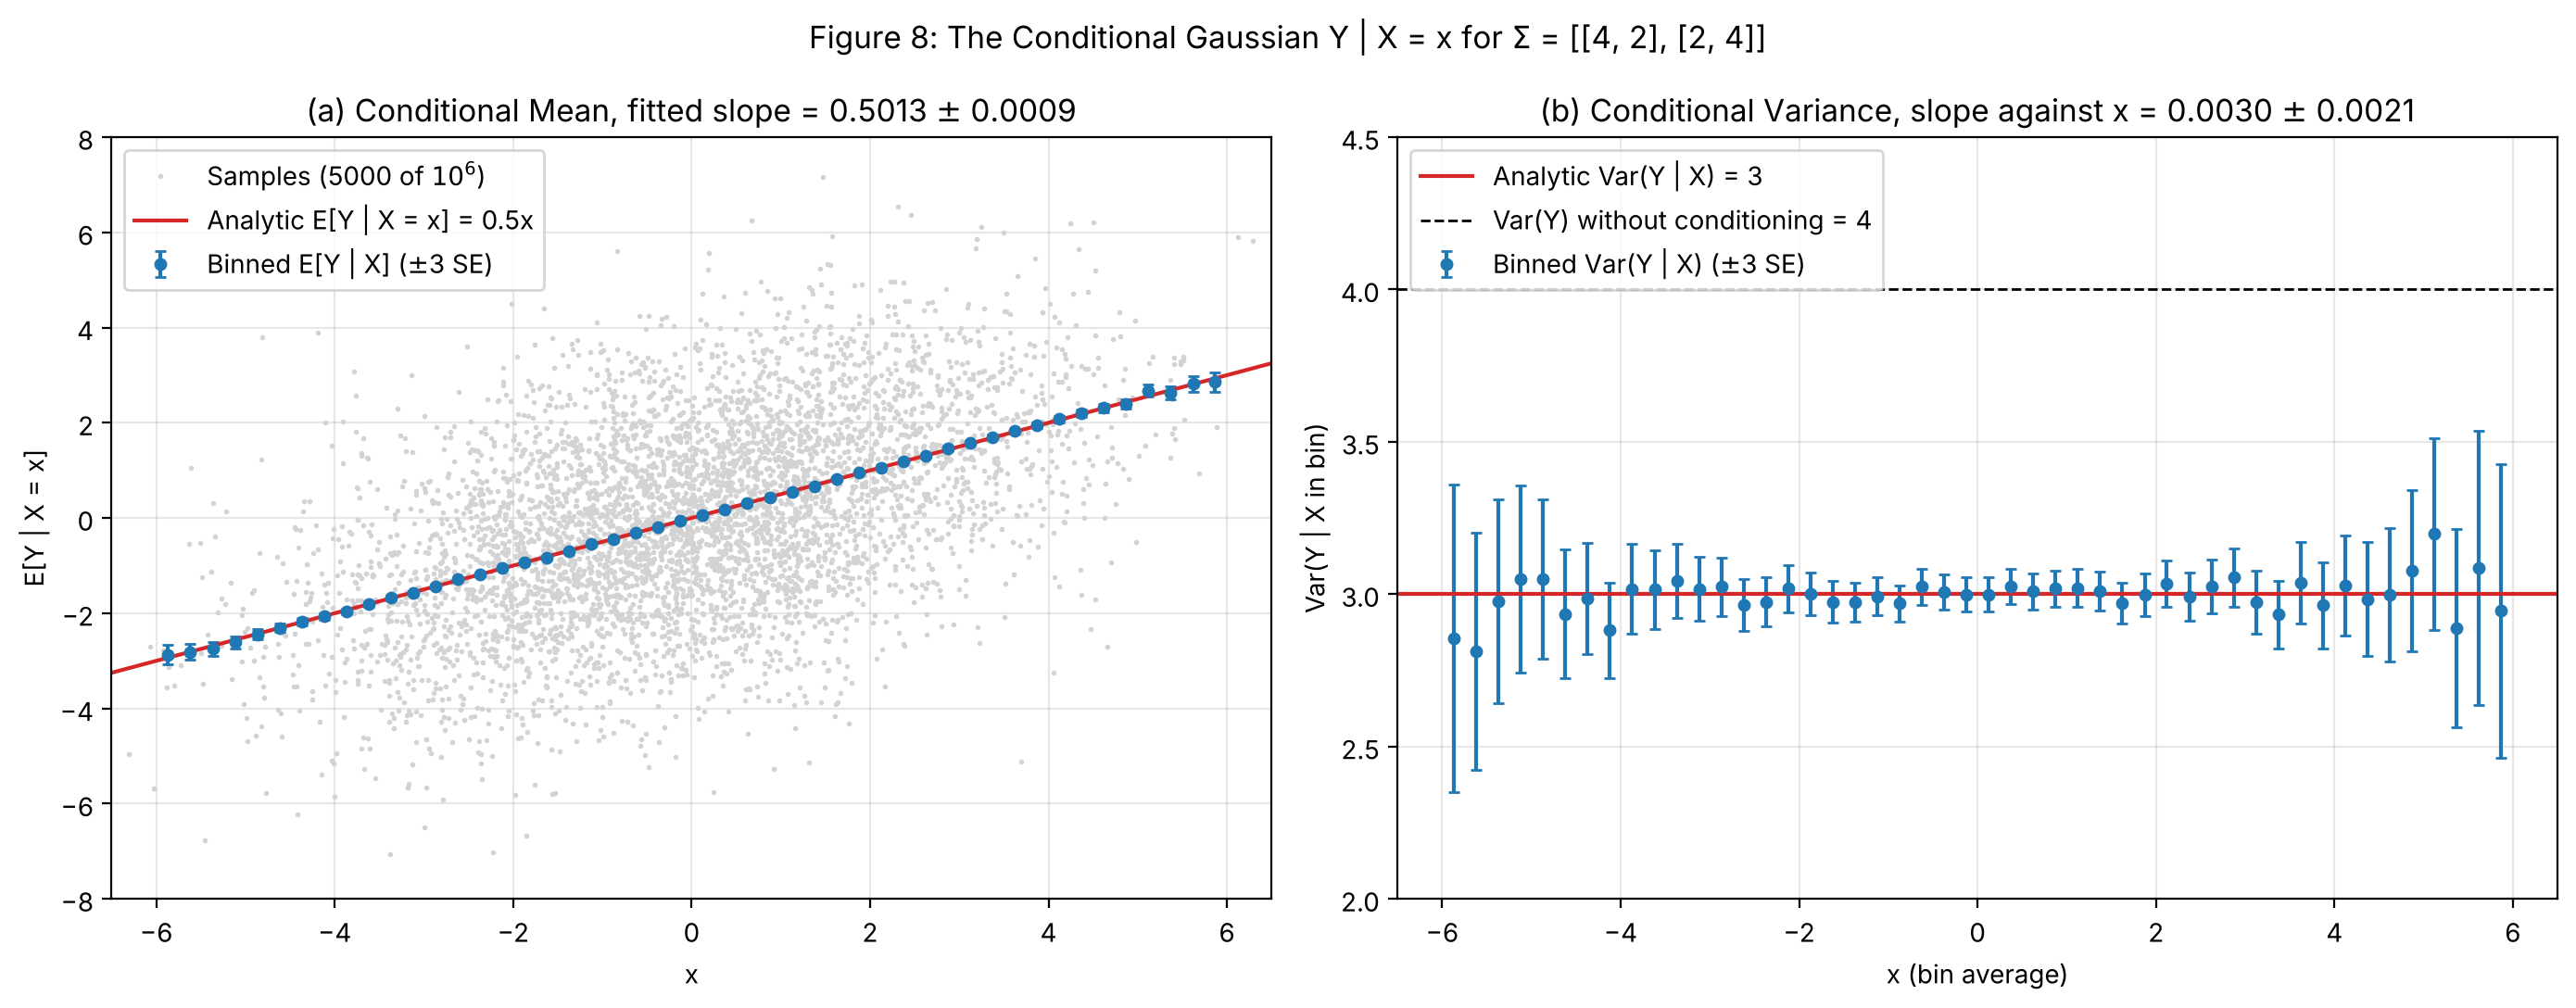

In [20]:
#Step 7: The conditional Gaussian

N_7 = 10**6 #One million samples

mu_7 = numpy.zeros(2)
Sigma_7 = Sigma_5.copy() #[[4, 2], [2, 4]]

#Hand calculated values from the partitioned formula
slope_exact_7 = Sigma_7[1, 0] / Sigma_7[0, 0]                                #Sigma_yx / Sigma_xx = 2/4 = 0.5
cond_var_exact_7 = Sigma_7[1, 1] - Sigma_7[1, 0] * Sigma_7[0, 1] / Sigma_7[0, 0] #Sigma_yy - Sigma_yx Sigma_xx^-1 Sigma_xy = 4 - 1 = 3
rho_7 = Sigma_7[0, 1] / numpy.sqrt(Sigma_7[0, 0] * Sigma_7[1, 1])
assert numpy.isclose(slope_exact_7, 0.5)
assert numpy.isclose(cond_var_exact_7, 3.0)
assert numpy.isclose(cond_var_exact_7, Sigma_7[1, 1] * (1 - rho_7**2)) #Same thing written as sigma_y^2 (1 - rho^2)

#Part 1 check: the joint density divided by the marginal of X should equal the N(x/2, 3) density at every point
check_pts_7 = numpy.array([[0.0, 0.0], [1.0, -2.0], [-3.0, 1.5], [2.5, 2.5], [4.0, -1.0]])
joint_7 = func.gaussian_pdf(check_pts_7, mu_7, Sigma_7)
marg_x_7 = numpy.exp(-check_pts_7[:, 0]**2 / (2 * Sigma_7[0, 0])) / numpy.sqrt(2 * numpy.pi * Sigma_7[0, 0])
cond_formula_7 = numpy.exp(-(check_pts_7[:, 1] - slope_exact_7 * check_pts_7[:, 0])**2 / (2 * cond_var_exact_7)) / numpy.sqrt(2 * numpy.pi * cond_var_exact_7)
ratio_diff_7 = numpy.max(numpy.abs(joint_7 / marg_x_7 - cond_formula_7) / cond_formula_7)

print("Part 1 and 2: Conditional Density of Y given X = x")
print(f"rho = {rho_7:.4f}")
print(f"E[Y | X = x] = {slope_exact_7:.4f} x      Var(Y | X = x) = {cond_var_exact_7:.4f}")
print(f"Largest relative difference f(x, y)/f_X(x) vs N(x/2, 3) density at 5 points: {ratio_diff_7:.2e}")

#Part 3: Generate 10^6 samples and bin them by x
samples_7 = rng7.multivariate_normal(mu_7, Sigma_7, size=N_7)
x_7 = samples_7[:, 0]
y_7 = samples_7[:, 1]

#Fixed width bins of 0.25 from -6 to 6 (3 standard deviations of X), bins with fewer than 200 samples are dropped
edges_7 = numpy.arange(-6, 6 + 0.25, 0.25)
bin_index_7 = numpy.digitize(x_7, edges_7) - 1
min_count_7 = 200

x_mean_bins_7 = []   #Average x inside each bin, used as the x position of the bin
y_mean_bins_7 = []   #Conditional mean of y inside each bin
y_mean_se_7 = []     #Standard error of the conditional mean, s/sqrt(n)
y_var_bins_7 = []    #Conditional variance of y inside each bin
y_var_se_7 = []      #Standard error of the conditional variance
x_var_bins_7 = []    #Spread of x inside each bin, used for the small binning correction
counts_7 = []

for b in range(len(edges_7) - 1):
    in_bin = bin_index_7 == b
    n = numpy.count_nonzero(in_bin)
    if n < min_count_7:
        continue
    xb = x_7[in_bin]
    yb = y_7[in_bin]
    x_mean_bins_7.append(xb.mean())
    y_mean_bins_7.append(yb.mean())
    y_mean_se_7.append(yb.std(ddof=1) / numpy.sqrt(n))
    y_var_bins_7.append(yb.var(ddof=1))
    #Sample variance is a sample mean of (y - mean)^2, so its SE is the std of (y - mean)^2 over sqrt(n), same as Step 2
    y_var_se_7.append(numpy.std((yb - yb.mean())**2) / numpy.sqrt(n))
    x_var_bins_7.append(xb.var(ddof=1))
    counts_7.append(n)

x_mean_bins_7 = numpy.array(x_mean_bins_7)
y_mean_bins_7 = numpy.array(y_mean_bins_7)
y_mean_se_7 = numpy.array(y_mean_se_7)
y_var_bins_7 = numpy.array(y_var_bins_7)
y_var_se_7 = numpy.array(y_var_se_7)
x_var_bins_7 = numpy.array(x_var_bins_7)
counts_7 = numpy.array(counts_7)
n_bins_7 = len(counts_7)

#Weighted least squares line through the binned means, each bin weighted by 1/SE^2 so the noisy tail bins count less
def weighted_line_fit(x, y, se):
    w = 1 / se**2
    x_bar = numpy.sum(w * x) / numpy.sum(w)
    y_bar = numpy.sum(w * y) / numpy.sum(w)
    Sxx = numpy.sum(w * (x - x_bar)**2)
    slope = numpy.sum(w * (x - x_bar) * (y - y_bar)) / Sxx
    intercept = y_bar - slope * x_bar
    slope_se = numpy.sqrt(1 / Sxx)
    intercept_se = numpy.sqrt(1 / numpy.sum(w) + x_bar**2 / Sxx)
    chi2 = numpy.sum(w * (y - intercept - slope * x)**2)
    return slope, slope_se, intercept, intercept_se, chi2

slope_7, slope_se_7, icept_7, icept_se_7, chi2_mean_7 = weighted_line_fit(x_mean_bins_7, y_mean_bins_7, y_mean_se_7)

#Check on the slope SE: a straight regression on all 10^6 points has SE = sqrt(Var(Y|X) / (N Var(X)))
slope_se_theory_7 = numpy.sqrt(cond_var_exact_7 / (N_7 * Sigma_7[0, 0]))

#Difference of each binned mean from the analytic line 0.5 x
z_mean_7 = (y_mean_bins_7 - slope_exact_7 * x_mean_bins_7) / y_mean_se_7

print(f"\nPart 3: Conditional Mean, N = {N_7}, {n_bins_7} bins of width 0.25 from {x_mean_bins_7.min():.2f} to {x_mean_bins_7.max():.2f}")
print(f"Samples per bin: smallest {counts_7.min()}, largest {counts_7.max()}, {N_7 - counts_7.sum()} samples outside the kept bins")
print(f"Fitted slope:      {slope_7:.6f} +/- {slope_se_7:.6f}   exact 0.5   |difference| / SE = {abs(slope_7 - slope_exact_7) / slope_se_7:.2f}")
print(f"Fitted intercept:  {icept_7:.6f} +/- {icept_se_7:.6f}   exact 0     |difference| / SE = {abs(icept_7) / icept_se_7:.2f}")
print(f"Slope SE expected from sqrt(Var(Y|X) / (N Var(X))) = {slope_se_theory_7:.6f}")
print(f"Largest |binned mean - 0.5 x| / SE: {numpy.max(numpy.abs(z_mean_7)):.2f}   bins within 3 SE: {numpy.sum(numpy.abs(z_mean_7) <= 3)} of {n_bins_7}")
print(f"Chi square of the binned means about the fitted line: {chi2_mean_7:.1f} with {n_bins_7 - 2} degrees of freedom")

#Part 4: Conditional variance in each bin
#A bin has width, so Y inside it also picks up the spread of the mean 0.5 x across the bin:
#Var(Y | X in bin) = 3 + 0.25 Var(X | X in bin), and Var(X | X in bin) is about 0.25^2/12
expected_var_bins_7 = cond_var_exact_7 + slope_exact_7**2 * x_var_bins_7
z_var_7 = (y_var_bins_7 - expected_var_bins_7) / y_var_se_7

#Fit a line to the variances, if Var(Y | X) does not depend on x the slope should be 0 within its SE
var_slope_7, var_slope_se_7, var_icept_7, var_icept_se_7, chi2_var_7 = weighted_line_fit(x_mean_bins_7, y_var_bins_7, y_var_se_7)

#Weighted average of all the binned variances
w_var_7 = 1 / y_var_se_7**2
var_avg_7 = numpy.sum(w_var_7 * y_var_bins_7) / numpy.sum(w_var_7)
var_avg_se_7 = numpy.sqrt(1 / numpy.sum(w_var_7))

#For comparison, the variance of Y without conditioning
var_y_all_7 = y_7.var(ddof=1)

print(f"\nPart 4: Conditional Variance")
print(f"Largest binning correction 0.25 Var(X | bin): {numpy.max(slope_exact_7**2 * x_var_bins_7):.5f}")
print(f"Binned variances: smallest {y_var_bins_7.min():.4f}, largest {y_var_bins_7.max():.4f}")
print(f"Weighted average of the binned variances: {var_avg_7:.4f} +/- {var_avg_se_7:.4f}   exact 3   |difference| / SE = {abs(var_avg_7 - cond_var_exact_7) / var_avg_se_7:.2f}")
print(f"Slope of variance against x: {var_slope_7:.5f} +/- {var_slope_se_7:.5f}   |slope| / SE = {abs(var_slope_7) / var_slope_se_7:.2f}")
print(f"Largest |binned variance - expected| / SE: {numpy.max(numpy.abs(z_var_7)):.2f}   bins within 3 SE: {numpy.sum(numpy.abs(z_var_7) <= 3)} of {n_bins_7}")
print(f"Chi square of the binned variances about the expected values: {numpy.sum(z_var_7**2):.1f} with {n_bins_7} degrees of freedom")
print(f"Var(Y) without conditioning: {var_y_all_7:.4f}   (exact 4), knowing X removes {100 * (1 - var_avg_7 / var_y_all_7):.1f}% of the variance (exact rho^2 = 25%)")

#Figure 8: binned conditional means and binned conditional variances
x_line_7 = numpy.linspace(-6.5, 6.5, 200)

plt.figure(figsize=(14, 5.5))

plt.subplot(1, 2, 1)
plt.plot(x_7[:5000], y_7[:5000], ".", color="lightgray", markersize=2, label="Samples (5000 of $10^6$)")
plt.errorbar(x_mean_bins_7, y_mean_bins_7, yerr=3 * y_mean_se_7, fmt="o", color="tab:blue", markersize=4, capsize=2, label="Binned E[Y | X] ($\\pm$3 SE)")
plt.plot(x_line_7, slope_exact_7 * x_line_7, color="tab:red", linewidth=1.5, label="Analytic E[Y | X = x] = 0.5x")
plt.title(f"(a) Conditional Mean, fitted slope = {slope_7:.4f} $\\pm$ {slope_se_7:.4f}")
plt.xlabel("x")
plt.ylabel("E[Y | X = x]")
plt.xlim(-6.5, 6.5)
plt.ylim(-8, 8)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.errorbar(x_mean_bins_7, y_var_bins_7, yerr=3 * y_var_se_7, fmt="o", color="tab:blue", markersize=4, capsize=2, label="Binned Var(Y | X) ($\\pm$3 SE)")
plt.axhline(cond_var_exact_7, color="tab:red", linewidth=1.5, label="Analytic Var(Y | X) = 3")
plt.axhline(Sigma_7[1, 1], color="black", linestyle="--", linewidth=1, label="Var(Y) without conditioning = 4")
plt.title(f"(b) Conditional Variance, slope against x = {var_slope_7:.4f} $\\pm$ {var_slope_se_7:.4f}")
plt.xlabel("x (bin average)")
plt.ylabel("Var(Y | X in bin)")
plt.xlim(-6.5, 6.5)
plt.ylim(2, 4.5)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.suptitle("Figure 8: The Conditional Gaussian Y | X = x for $\\Sigma$ = [[4, 2], [2, 4]]")
plt.tight_layout()
plt.show()


### Figure 8 Explanation

    Figure 8 (a) depicts the 48 binned conditional means of Y with ±3 SE error bars on top of 5000 of the 10^6 samples, and the analytic line E[Y | X = x] = 0.5x in red. You will notice that every bin sits on the line, from x = -5.87 to 5.87. All 48 of 48 bins were within 3 standard errors of 0.5x (largest |difference| / SE = 2.74), and the chi square about the fitted line was 47.7 with 46 degrees of freedom, so the scatter of the bins around the line is the size we expect from sampling noise and there is no curvature. The weighted fit gave a slope of 0.501340 ± 0.000879, which is 1.52 standard errors from 0.5, and an intercept of 0.000047 ± 0.001735, 0.03 standard errors from 0. The slope SE matches the SE of a regression on all the points, sqrt(3/(4·10^6)) = 0.000866, so binning did not throw away information about the slope. The gray cloud shows why the mean is not the whole story: at any x the samples still spread about ±sqrt(3) = ±1.73 around the line.

    Figure 8 (b) depicts the binned conditional variance of Y. The bins scatter around the red line at 3 and not around the dashed line at Var(Y) = 4, from 2.8123 to 3.1977 with the largest spread in the tail bins that have as few as 670 samples. All 48 of 48 bins were within 3 standard errors of the expected 3 + 0.25 Var(X | bin) (largest |difference| / SE = 2.32, chi square 44.1 with 48 degrees of freedom). The weighted average of the binned variances is 3.0011 ± 0.0042, 0.27 standard errors from 3. A line fit to the variances against x has slope 0.00297 ± 0.00215, 1.38 standard errors from 0, so the variance does not depend on x. The largest binning correction was only 0.00138. The sample Var(Y) was 4.0053, so knowing X removed 25.1% of the variance of Y, which matches rho^2 = 25%.

### The Conditional Variance Does Not Depend on x

    Var(Y | X = x) = Σ_yy - Σ_yx Σ_xx^-1 Σ_xy has no x in it, so for a Gaussian every observed value of x leaves the same uncertainty of 3. This is special to the Gaussian. In Step 1, f(x, y) = x + y gave E[Y | X = x] = (x/2 + 1/3)/(x + 1/2), which is a curve and not a line, and its conditional variance also changes with x. In Step 2, Y = X² had a conditional variance of 0 at every x but a conditional mean x² that is not linear at all. Only the Gaussian gives both a straight line conditional mean and a constant conditional variance.

### Why Linearity Makes the Linear Estimator of Step 8 Optimal

    The estimator with the smallest mean squared error over every possible function of the data is the conditional mean E[S | X]. For jointly Gaussian data, Step 7 shows that E[S | X = x] = Σ_sx^T Σ_xx^-1 x is a linear function of x, which is exactly the LMMSE estimator w^T x with w = Σ_xx^-1 Σ_sx. So restricting ourselves to linear estimators loses nothing, the best linear estimator is the best estimator of any kind, and its error variance σ_s^2 - Σ_sx^T Σ_xx^-1 Σ_sx is the Schur complement from the partitioned formula. Because the conditional variance does not depend on x, that MMSE is the error for every measurement we could see and not just on average. For non Gaussian data the LMMSE weights are still the best straight line, but a nonlinear estimator could beat it, like it would in Step 2 where a linear estimator of X² from X does no better than guessing the mean.

In [21]:
#Total notebook runtime
total_runtime = time.time() - T_START

print("Total notebook runtime:", round(total_runtime / 60, 2), "minutes")

#Youtube unlisted demo video
# 

Total notebook runtime: 0.12 minutes
